# Import Library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import cmath
import csv
import time

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.layers import Dense, Conv1D, Flatten, GRU, Input, MaxPooling1D, concatenate, BatchNormalization, Reshape
from tensorflow.keras.losses import MeanSquaredError, MeanAbsolutePercentageError
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import plot_model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

In [ ]:

from scipy.interpolate import interp1d

# Fungsi Penting

In [ ]:

def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)

  return depth_plot, resis_plot

In [ ]:

def measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # MSE untuk resistivitas_semu
  mse_resistivitas = np.mean(np.square(resistivitas_semu - resistivitas_semu_predict))

  # MSE untuk fasa
  mse_fasa = np.mean(np.square(fasa - fasa_predict))

  # Cetak hasil
  print(f"MSE Resistivitas Semu: {mse_resistivitas:.2f}")
  print(f"MSE Fasa: {mse_fasa:.2f}")

In [ ]:

def measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # Hitung MAPE
  mape = np.mean(np.abs((resistivitas_semu - resistivitas_semu_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE resistivitas semu: {mape:.2f}%")
  # Hitung MAPE
  mape = np.mean(np.abs((fasa - fasa_predict) / fasa)) * 100

  # Cetak hasil
  print(f"MAPE fasa: {mape:.2f}%")

In [ ]:
import numpy as np

def measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # RMSE untuk resistivitas_semu
  rmse_resistivitas = np.sqrt(np.mean(np.square(resistivitas_semu - resistivitas_semu_predict)))

  # RMSE untuk fasa
  rmse_fasa = np.sqrt(np.mean(np.square(fasa - fasa_predict)))

  # Cetak hasil
  print(f"RMSE Resistivitas Semu: {rmse_resistivitas:.2f}")
  print(f"RMSE Fasa: {rmse_fasa:.2f}")

In [ ]:
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

def measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth):
  # Formating data
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)

  # Definisikan grid kedalaman umum
  common_depths = np.linspace(0, 4000, 200)

  # Interpolasi ke grid umum
  interp_true = interp1d(depth_true_plot, resis_true_plot, kind='previous', fill_value='extrapolate')
  interp_pred = interp1d(depth_pred_plot, resis_pred_plot, kind='previous', fill_value='extrapolate')

  res_true_interp = interp_true(common_depths)
  res_pred_interp = interp_pred(common_depths)

  # Sekarang bisa dibandingkan secara numerik juga
  mse_interp = mean_squared_error(res_true_interp, res_pred_interp)
  rmse_interp = np.sqrt(mse_interp) # Calculate RMSE
  mape_interp = mean_absolute_percentage_error(res_true_interp, res_pred_interp)

  print(f"[Interpolated] MSE model resistivitas: {mse_interp:.4f}")
  print(f"[Interpolated] RMSE model resistivitas: {rmse_interp:.4f}") # Print RMSE
  print(f"[Interpolated] MAPE model resistivitas: {mape_interp*100:.2f}%")

  plt.figure(figsize=(8, 6))

  # Plot garis hasil interpolasi
  plt.scatter(res_true_interp, common_depths, label='True (Interpolated)', color='blue', linewidth=2)
  plt.scatter(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  plt.scatter(res_pred_interp, common_depths, label='Predicted (Interpolated)', color='red', linestyle='--', linewidth=2)


  # Sumbu y dibalik agar makin dalam ke bawah
  plt.gca().invert_yaxis()

  # Label dan judul
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Perbandingan Interpolasi Resistivitas Sebenarnya vs Prediksi', fontsize=14)
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xlim(0, 2000)
  plt.ylim(4000,0)

  plt.show()

In [ ]:
def plot_model(resis_predict, ketebalan_predict ,total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)
  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:

def plot_model_compare(res_true, ketebalan_true, res_predict, ketebalan_predict, total_depth):
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:

def plot_MT(resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
  ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
  ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
  ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
  ax1.set_xlabel('Period (s)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_yscale('symlog')
  ax1.set_ylim([0, 10000])
  ax1.set_xlim([1e-4, 1e4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
  ax2.scatter(1/frequency, phaseYX+180, color='red', label=r'$\phi_{yx}$', s=20)
  ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
  ax2.set_ylabel('Phase [°]', fontsize=12)
  ax2.set_xlabel('Period (s)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([20, 60])
  ax2.set_xlim([1e-4, 1e4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  #Jika ingin mengaktifkan subplot 3, tinggal uncomment
  ax3 = fig.add_subplot(gs[:, 1])
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 1200)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()



In [ ]:
def plot_MT_compare(res_true, thick_true, res_pred, thick_pred,
                    periods, phase_true, res_app_true, phase_pred, res_app_pred,
                    total_depth):

    # Convert model to depth-resistivity format
    depth_true_plot, res_true_plot = formating_result(res_true, thick_true, total_depth)
    depth_pred_plot, res_pred_plot = formating_result(res_pred, thick_pred, total_depth)

    # Create figure and GridSpec layout
    fig = plt.figure(figsize=(15, 8))
    gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])

    # === Subplot 1: Apparent Resistivity ===
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.scatter(periods, res_app_true[0], color='blue', label='True Data', s=20, marker='o')
    ax1.plot(periods, res_app_pred[0], '--', color='red', label='Predicted Data', linewidth=2)
    ax1.set_xscale('log')
    ax1.set_xlim(1e-4, 1e4)
    ax1.set_ylim(0, 1200)
    ax1.set_xlabel('Periods (s)', fontsize=12)
    ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
    ax1.set_title('Apparent Resistivity ($\\rho$)', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # === Subplot 2: Phase ===
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.scatter(periods, phase_true[0], color='blue', label='True Data', s=20, marker='o')
    ax2.plot(periods, phase_pred[0], '--', color='red', label='Predicted Data', linewidth=2)
    ax2.set_xscale('log')
    ax2.set_xlim(1e-4, 1e4)
    ax2.set_ylim(0, 90)
    ax2.set_xlabel('Periods (s)', fontsize=12)
    ax2.set_ylabel('Phase [°]', fontsize=12)
    ax2.set_title('Phase (°)', fontsize=14)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend()

    # === Subplot 3: 1D Inversion Result ===
    ax3 = fig.add_subplot(gs[:, 1])
    ax3.plot(res_pred_plot, depth_pred_plot, label='Predicted Model', color='red', linestyle='--', linewidth=2)
    ax3.plot(res_true_plot, depth_true_plot, label='True Model', color='blue', linestyle='--', linewidth=2)
    ax3.set_xlim(0, 1200)
    ax3.set_ylim(total_depth, 0)  # Depth from surface to bottom
    ax3.set_xlabel('Resistivity [$\Omega$·m]', fontsize=12)
    ax3.set_ylabel('Depth (m)', fontsize=12)
    ax3.set_title('1D Subsurface Resistivity Model', fontsize=14)
    ax3.grid(True, linestyle='--', alpha=0.6)
    ax3.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


#Forward Modelling

In [ ]:

#Fungsi forward modelling
def forward_modelling(res_true, ketebalan, frequencies):
    resistivitas_semu = np.array([])
    fasa = np.array([])
    for frequency in frequencies:
        w = 2 * np.pi * frequency
        mu = 4 * np.pi * 10**(-7)
        n = len(res_true)
        Z = list(range(n))  # Initialize Z as a list
        Z[n-1] = cmath.sqrt(w * mu * res_true[n-1] * 1j)  # Calculate basement impedance
        for j in range(n-2, -1, -1):
            Z0j = cmath.sqrt(1j * w * mu * res_true[j])  # Intrinsic impedance of current layer
            kj = cmath.sqrt(1j * w * mu / res_true[j])  # Wave number
            ej = cmath.exp(-2 * ketebalan[j] * kj)  # Exponential factor
            Rj = (Z0j - Z[j+1]) / (Z0j + Z[j+1])  # Reflection coefficient
            Z[j] = Z0j * (1 - Rj * ej) / (1 + Rj * ej)  # Impedance of current layer
        Z_intrinsik = Z[0]  # Top layer impedance
        absZ = abs(Z_intrinsik)
        appres = (absZ * absZ) / (mu * w)  # Apparent resistivity
        phase = np.degrees(cmath.phase(Z_intrinsik))  # Phase in degrees
        resistivitas_semu = np.append(resistivitas_semu, appres)
        fasa = np.append(fasa, phase)
    return resistivitas_semu, fasa  # Return the arrays

#Pembuatan Dataset

In [ ]:
import numpy as np
import pandas as pd
import cmath

# === Parameter utama ===
jumlah_data = 2000000
jumlah_layer = 20
total_depth = 4000
tebal_per_lapisan = 200  # meter
frequencies = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/Frequency_Aceh01.txt").flatten()
mu0 = 4 * np.pi * 1e-7
np.random.seed(42)



In [ ]:
# Start timer
start = time.time()

# === Dataset Generator ===
input_res_array = []
input_phase_array = []
output_model_array = []

for _ in range(jumlah_data):
    # 1. Generate resistivitas antar lapisan (acak logscale)
    res_true = np.random.choice(np.arange(1, 2000, 1), size=jumlah_layer)

    # 2. Ketebalan semua layer = 200 meter
    ketebalan = np.full(jumlah_layer - 1, tebal_per_lapisan)

    # 3. Forward modelling
    res_semi, fasa = forward_modelling(res_true, ketebalan, frequencies)

    # 4. Output: hanya 20 nilai resistivitas
    output_model_array.append(res_true)
    input_res_array.append(res_semi)
    input_phase_array.append(fasa)

# === Tambahkan noise ke 30% data input
persen_noise = 0.3
jumlah_noisy = int(persen_noise * jumlah_data)
indeks_noisy = np.random.choice(jumlah_data, jumlah_noisy, replace=False)

res_with_noise = input_res_array.copy()
phase_with_noise = input_phase_array.copy()

for idx in indeks_noisy:
    noise_r = np.random.normal(0, 0.05, size=res_with_noise[idx].shape)
    noise_p = np.random.normal(0, 0.05, size=phase_with_noise[idx].shape)
    res_with_noise[idx] = res_with_noise[idx] * (1 + noise_r)
    phase_with_noise[idx] = phase_with_noise[idx] * (1 + noise_p)

# === Shuffle
combined = list(zip(res_with_noise, phase_with_noise, output_model_array))
np.random.shuffle(combined)
shuffled_res, shuffled_phase, shuffled_output = zip(*combined)

# === Simpan ke DataFrame
df_input_res = pd.DataFrame(np.array(shuffled_res))
df_input_phase = pd.DataFrame(np.array(shuffled_phase))
df_output_model = pd.DataFrame(np.array(shuffled_output))  # output = 20 resistivitas

# === Simpan ke CSV
df_input_res.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_Lapangan_4.csv', index=False)
df_input_phase.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_Lapangan_4.csv', index=False)
df_output_model.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_Lapangan_4.csv', index=False)

print(f"✅ Dataset 20-layer dengan ketebalan tetap 200m berhasil dibuat!")
print(f"Total sampel: {jumlah_data} | Dengan noise: {jumlah_noisy}")
# End timer
end = time.time()
print(f"Dataset dibuat dalam {(end-start)/60:.2f} menit")


✅ Dataset 20-layer dengan ketebalan tetap 200m berhasil dibuat!
Total sampel: 2000000 | Dengan noise: 600000
Dataset dibuat dalam 310.63 menit


#Membaca dataset, normalisasi dan standarisasi

In [ ]:
df_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_Lapangan_4.csv')
df_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_Lapangan_4.csv')
df_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_Lapangan_4.csv')

In [ ]:
input_res_readed = df_input_res.to_numpy()
input_phase_readed = df_input_phase.to_numpy()
output_model_readed = df_output_model.to_numpy()

In [ ]:
input_res_readed = input_res_readed.reshape(input_res_readed.shape[0], input_res_readed.shape[1])
input_phase_readed = input_phase_readed.reshape(input_phase_readed.shape[0], input_phase_readed.shape[1])
output_model_readed = output_model_readed.reshape(output_model_readed.shape[0], output_model_readed.shape[1])

In [ ]:
# Terapkan transformasi logaritmik pada data input dan output
input_res_readed_log = np.log10(input_res_readed)
input_phase_readed_log = np.log10(input_phase_readed)
output_model_readed_log = np.log10(output_model_readed)

print("Shape input_res_readed_log:", input_res_readed_log.shape)
print("Shape input_phase_readed_log:", input_phase_readed_log.shape)
print("Shape output_model_readed_log:", output_model_readed_log.shape)

Shape input_res_readed_log: (2000000, 48)
Shape input_phase_readed_log: (2000000, 48)
Shape output_model_readed_log: (2000000, 20)


In [ ]:
input_res_scaler = MinMaxScaler(feature_range=(0, 1))
input_phase_scaler = MinMaxScaler(feature_range=(0, 1))
output_model_scaler = MinMaxScaler(feature_range=(0, 1))

In [ ]:
input_res_scaled = input_res_scaler.fit_transform(input_res_readed_log)
input_phase_scaled = input_phase_scaler.fit_transform(input_phase_readed_log)
output_model_scaled = output_model_scaler.fit_transform(output_model_readed_log)

In [ ]:
df_input_res_scaled = pd.DataFrame(input_res_scaled)
df_input_phase_scaled = pd.DataFrame(input_phase_scaled)
df_output_model_scaled = pd.DataFrame(output_model_scaled)

In [ ]:
df_input_res_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_log_Lapangan4.csv', index=False)
df_input_phase_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_log_Lapangan4.csv', index=False)
df_output_model_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_log_Lapangan4.csv', index=False)

#Membaca Dataset Normalisasi dan data Splitting

In [ ]:
df_X_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_log_Lapangan4.csv')
df_X_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_log_Lapangan4.csv')
df_Y_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_log_Lapangan4.csv')

In [ ]:
X_input_res = df_X_input_res.to_numpy()
X_input_phase = df_X_input_phase.to_numpy()
Y_output_model = df_Y_output_model.to_numpy()

In [ ]:
X_input_res_reshape = X_input_res.reshape(X_input_res.shape[0], X_input_res.shape[1], 1)
X_input_phase_reshape = X_input_phase.reshape(X_input_phase.shape[0], X_input_phase.shape[1], 1)
Y_output_model_reshape = Y_output_model.reshape(Y_output_model.shape[0], Y_output_model.shape[1])

In [ ]:
# Bagi data menjadi training dan gabungan validation/test
X_train_res, X_val_res, X_train_phase, X_val_phase, y_train, y_val = train_test_split(
    X_input_res_reshape, X_input_phase_reshape, Y_output_model_reshape, test_size=0.2, random_state=42
)




In [ ]:
X_train = [X_train_res, X_train_phase]
X_val = [X_val_res, X_val_phase]

# Model CNN-GRU

In [ ]:
def CNN_GRU_Model_Scratch():

    #Input
    input_res = Input(shape=(X_train_res.shape[1],1), name = "input_res")
    input_phase = Input(shape=(X_train_phase.shape[1],1), name = "input_phase")

    # Convolusi input res
    x1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_res) # Changed stride to strides
    x1 = MaxPooling1D(pool_size=2)(x1)
    x1 = Conv1D(filters=32, kernel_size=2, strides=1, activation='relu', padding = 'same')(x1)
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Flatten()(x1)

    # Convolusi input phase
    z1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_phase) # Changed stride to strides
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=2, strides=1,  activation='relu', padding = 'same')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Flatten()(z1)

    merge = concatenate([x1, z1])
    dense_layer = Dense(128, activation = "relu")(merge) # Changed Dense to dense_layer
    # Reshape the output of the dense layer to be 3D for the GRU layer
    reshape_layer = layers.Reshape((1, dense_layer.shape[-1]))(dense_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid")(reshape_layer) # Changed Dense to dense_layer and Gru to gru_layer

    output = Dense(Y_output_model_reshape.shape[1])(gru_layer)  # Access the output shape using Y_output_model_reshape and apply the Dense layer to gru_layer

    model = Model(inputs=[input_res, input_phase], outputs=output)

    return model

In [ ]:
def CNN_GRU_Model_Improved_Lapangan4():
    input_res = Input(shape=(X_train_res.shape[1], 1), name="input_res")
    input_phase = Input(shape=(X_train_phase.shape[1], 1), name="input_phase")


    x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_res)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)
    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)

    # === Convolutional Branch for input_phase ===
    z = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_phase)
    z = Conv1D(64, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)
    z = Conv1D(128, kernel_size=3, activation='relu', padding='same')(z)
    z = Conv1D(256, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)

    # Flatten and Merge
    x = Flatten()(x)
    z = Flatten()(z)
    merged = concatenate([x, z])

    # Dense layer for higher-level features
    dense = Dense(256, activation="relu")(merged)
    dense = Dense(128, activation="relu")(dense)

    # Reshape before GRU
    reshape = layers.Reshape((1, dense.shape[-1]))(dense)

    # GRU layers
    gru = GRU(64, return_sequences=True)(reshape)
    gru = GRU(64, return_sequences=True)(gru)
    gru = GRU(32)(gru)

    # Output
    output = Dense(Y_output_model_reshape.shape[1])(gru)

    model = Model(inputs=[input_res, input_phase], outputs=output)
    return model


In [ ]:
model = CNN_GRU_Model_Improved_Lapangan4()

In [ ]:

plot_model(
    model,
    to_file='advanced_model.png',
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,  # Tampilkan aktivasi
    show_trainable=True,          # Tampilkan status trainable
    expand_nested=True,           # Perluas sub-model
    dpi=80                       # Resolusi tinggi
)

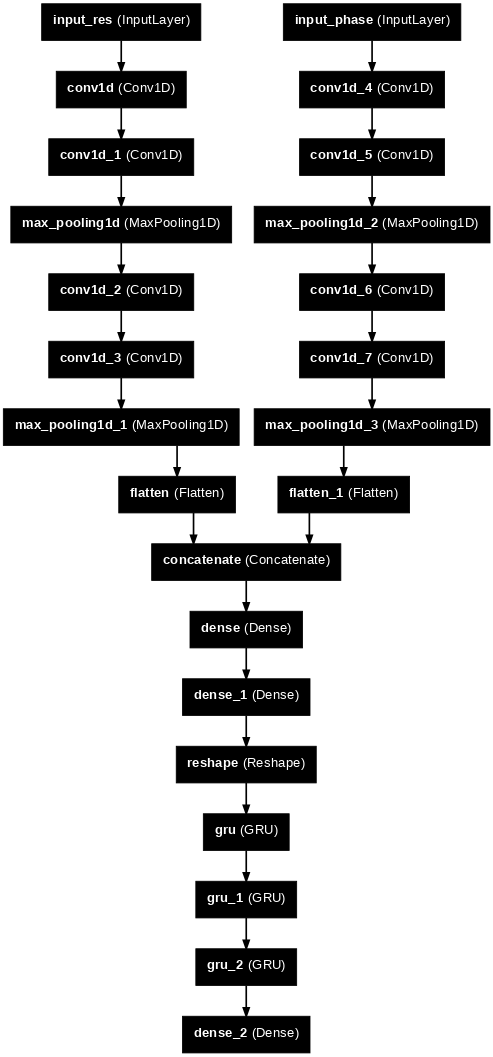

In [ ]:
plot_model(model, to_file='model_simple.png',
           show_shapes=False, show_layer_names=True, dpi=60)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_res           │ (None, 48, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_phase         │ (None, 48, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 48, 32)    │        128 │ input_res[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 48, 32)    │        128 │ input_phase[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 48, 64)    │      6,208 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 48, 64)    │      6,208 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 24, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 24, 64)    │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 24, 128)   │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 24, 128)   │     24,704 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 24, 256)   │     98,560 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 24, 256)   │     98,560 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 12, 256)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 12, 256)   │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3072)      │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3072)      │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 6144)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  1,573,120 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 128)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 1, 64)     │     37,248 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,937,492 (7.39 MB)

 Trainable params: 1,937,492 (7.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [EarlyStopping(monitor='val_loss', patience=15, verbose=1, restore_best_weights=True)]

In [ ]:
    checkpoint_filepath = '/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_Improved_model_Lapangan4.h5' # Choose a path in your Drive
    model_checkpoint_callback = ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=False, # Set to True if you only want to save weights
        monitor='val_loss',
        mode='min',
        save_best_only=True)

In [ ]:
    # Use Adam optimizer with learning rate scheduling
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
start = time.time()
history = model.fit(
    x=[X_train_res, X_train_phase],
    y=y_train,
    epochs=200,
    batch_size=16,  # sesuai paper
    validation_data=([X_val_res, X_val_phase], y_val),
    verbose=1,
    callbacks = [callbacks, model_checkpoint_callback]
)
end = time.time()
print(f"Waktu eksekusi: {(end - start) / 60:.2f} menit")

Epoch 1/200
 99996/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0171 - loss: 0.0171

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1106s 11ms/step - MSE: 0.0171 - loss: 0.0171 - val_MSE: 0.0091 - val_loss: 0.0091
Epoch 2/200
 99999/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0088 - loss: 0.0088

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1097s 11ms/step - MSE: 0.0088 - loss: 0.0088 - val_MSE: 0.0081 - val_loss: 0.0081
Epoch 3/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0081 - loss: 0.0081

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1108s 11ms/step - MSE: 0.0081 - loss: 0.0081 - val_MSE: 0.0078 - val_loss: 0.0078
Epoch 4/200
 99997/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0078 - loss: 0.0078

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1116s 11ms/step - MSE: 0.0078 - loss: 0.0078 - val_MSE: 0.0076 - val_loss: 0.0076
Epoch 5/200
 99997/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0076 - loss: 0.0076

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1119s 11ms/step - MSE: 0.0076 - loss: 0.0076 - val_MSE: 0.0076 - val_loss: 0.0076
Epoch 6/200
 99995/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0075 - loss: 0.0075

... (2 outputs left out)

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1125s 11ms/step - MSE: 0.0073 - loss: 0.0073 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 9/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1121s 11ms/step - MSE: 0.0073 - loss: 0.0073 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 10/200
 99999/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0072 - loss: 0.0072

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1123s 11ms/step - MSE: 0.0072 - loss: 0.0072 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 11/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1125s 11ms/step - MSE: 0.0072 - loss: 0.0072 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 12/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1123s 11ms/step - MSE: 0.0071 - loss: 0.0071 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 13/200
 99996/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0071 - loss: 0.0071

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1125s 11ms/step - MSE: 0.0071 - loss: 0.0071 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 14/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1124s 11ms/step - MSE: 0.0070 - loss: 0.0070 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 15/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1123s 11ms/step - MSE: 0.0070 - loss: 0.0070 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 16/200
 99998/100000 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0070 - loss: 0.0070

100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1126s 11ms/step - MSE: 0.0070 - loss: 0.0070 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 17/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1124s 11ms/step - MSE: 0.0069 - loss: 0.0069 - val_MSE: 0.0073 - val_loss: 0.0073
Epoch 18/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1123s 11ms/step - MSE: 0.0069 - loss: 0.0069 - val_MSE: 0.0075 - val_loss: 0.0075
Epoch 19/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1123s 11ms/step - MSE: 0.0069 - loss: 0.0069 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 20/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1124s 11ms/step - MSE: 0.0069 - loss: 0.0069 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 21/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1126s 11ms/step - MSE: 0.0068 - loss: 0.0068 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 22/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1126s 11ms/step - MSE: 0.0068 - loss: 0.0068 - val_MSE: 0.0074 - val_loss: 0.0074
Epoch 23/200
100000/100000 ━━━━━━━━━━━━━━━━━━━━ 1126s 11ms/step - MSE: 0.0068 - loss: 0.0068 - val_MSE:

In [ ]:
# model2 = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_Improved_model_Lapangan.h5')

In [ ]:
#     # Use Adam optimizer with learning rate scheduling
# model2.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
# start = time.time()
# history = model2.fit(
#     x=[X_train_res, X_train_phase],
#     y=y_train,
#     epochs=200,
#     initial_epoch = 76,
#     batch_size=16,  # sesuai paper
#     validation_data=([X_val_res, X_val_phase], y_val),
#     verbose=1,
#     callbacks = [callbacks, model_checkpoint_callback]
# )
# end = time.time()
# print(f"Waktu eksekusi: {(end - start) / 60:.2f} menit")

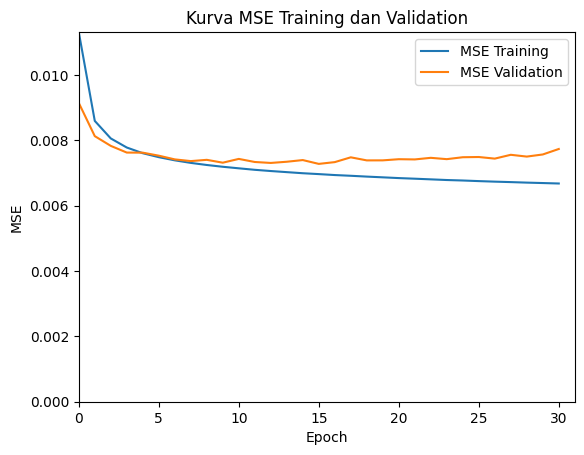

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.plot(mse_training, label='MSE Training')
plt.plot(mse_validation, label='MSE Validation')
plt.title('Kurva MSE Training dan Validation')
plt.xlim(0, len(mse_training))
plt.ylim(0, max(mse_training))
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Improved_takhingga_log_Lapangan4.h5')

#Deploy model dan Prediksi

In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Improved_takhingga_log_Lapangan4.h5')

In [ ]:
import numpy as np

# ... (kode untuk forward modelling dan fungsi normalisasi/denormalisasi) ...


# Forward modelling untuk data input
resis_true= np.array([300, 900, 300, 800 ,200])
ketebalan_true = np.array([900, 800, 700,800])

resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Nilai Resis_True [300 900 300 800 200]
Nilai ketebalan_True [900 800 700 800]
Nilai resis_predict [312.5881  375.2723  243.91058 538.3672  755.3261  847.88434 882.28345
 909.1655  763.1487  452.1475  386.86035 648.14075 808.3145  819.0012
 842.4831  848.916   708.7218  177.19957 511.9649  185.21854]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


#Grafik

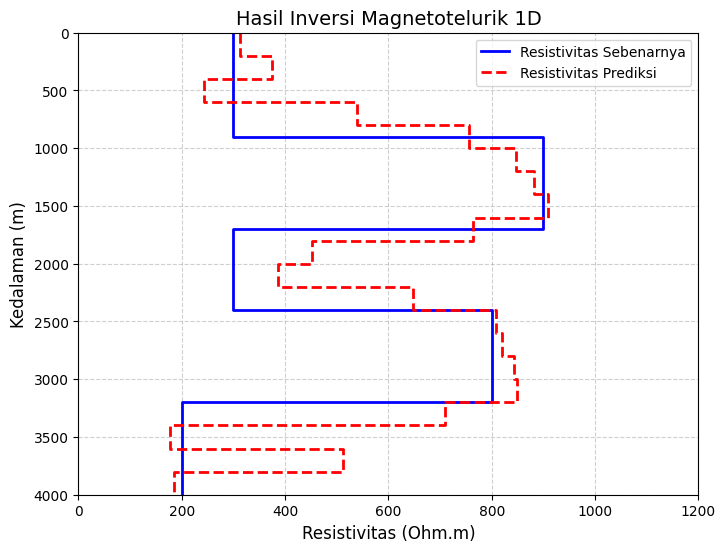

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

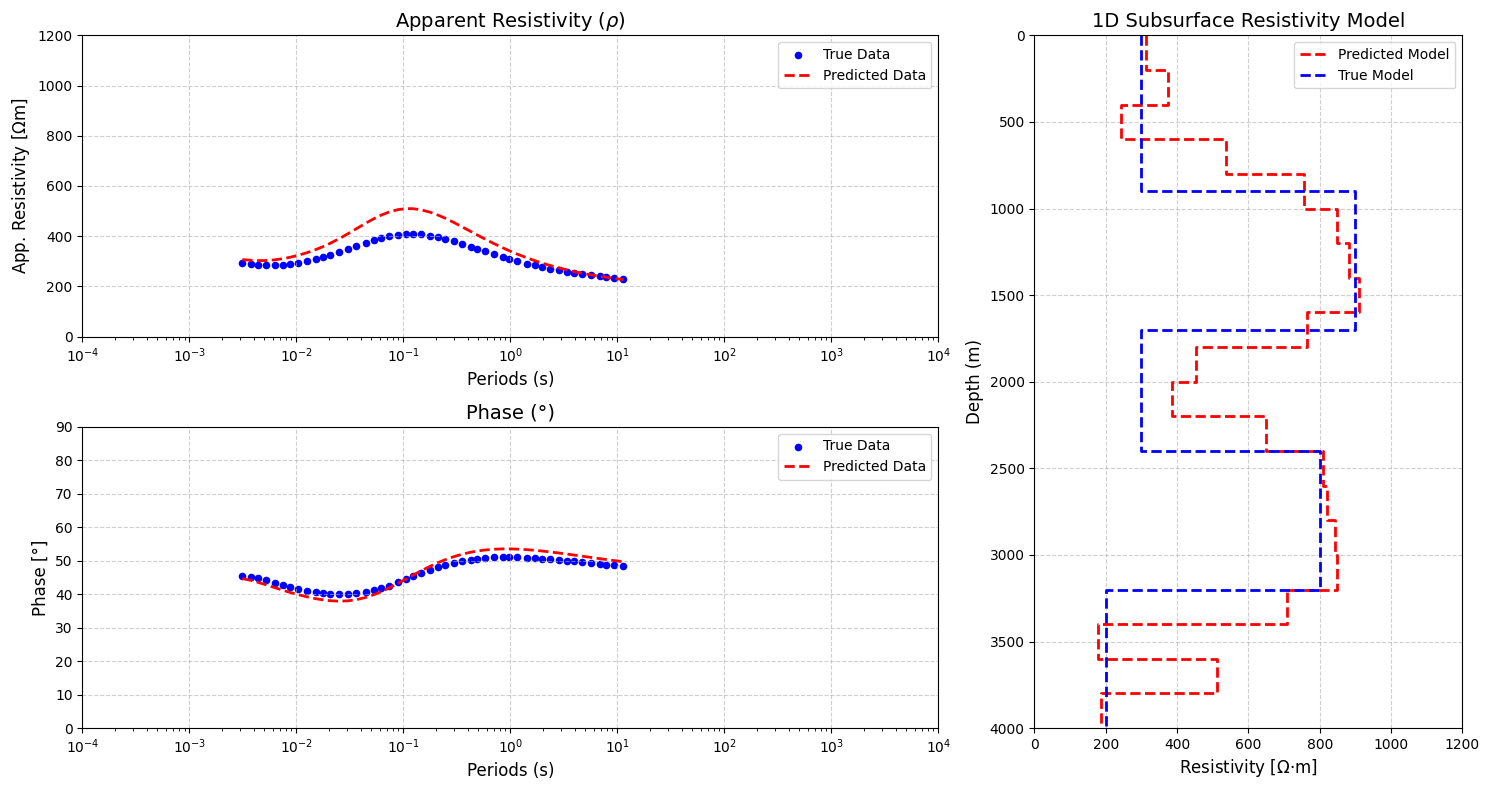

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

#Perhitungan Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 128.45
MSE Fasa: 0.28


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 2.65%
MAPE fasa: 1.02%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 11.33
RMSE Fasa: 0.53


[Interpolated] MSE model resistivitas: 15979.4188
[Interpolated] RMSE model resistivitas: 126.4097
[Interpolated] MAPE model resistivitas: 17.32%


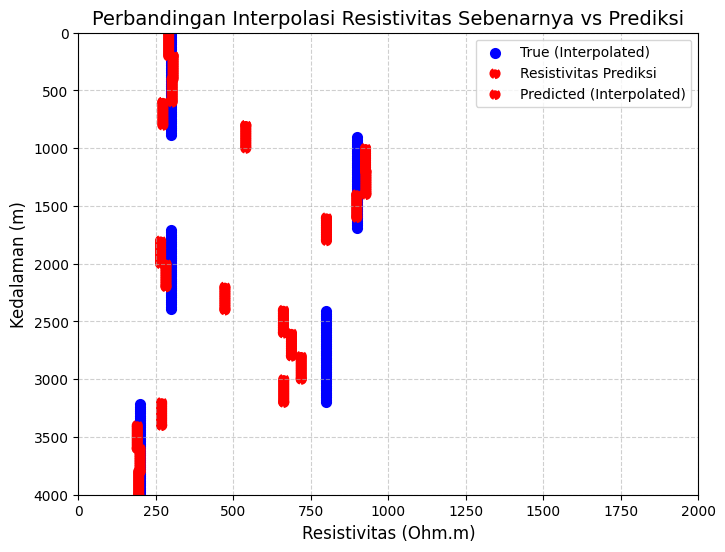

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Data Training

## Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_train[0].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_train_res[0].reshape(1, -1)
fasa = X_train_phase[0].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai resis_predict [820.67816 814.76337 810.27246 818.20264 833.68854 819.4208  823.26605
 812.5929  840.02844 819.711   821.2195  800.7738  823.8403  816.5509
 827.0454  844.7784  836.3014  812.4867  825.1751  807.807  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


##Grafik


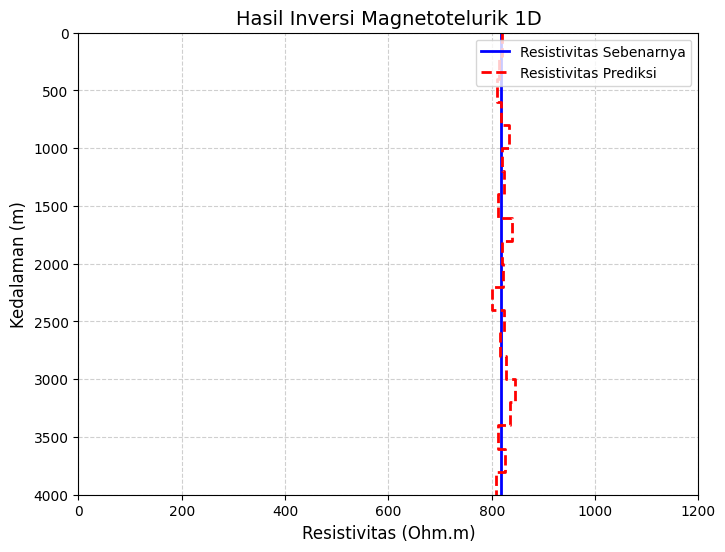

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)


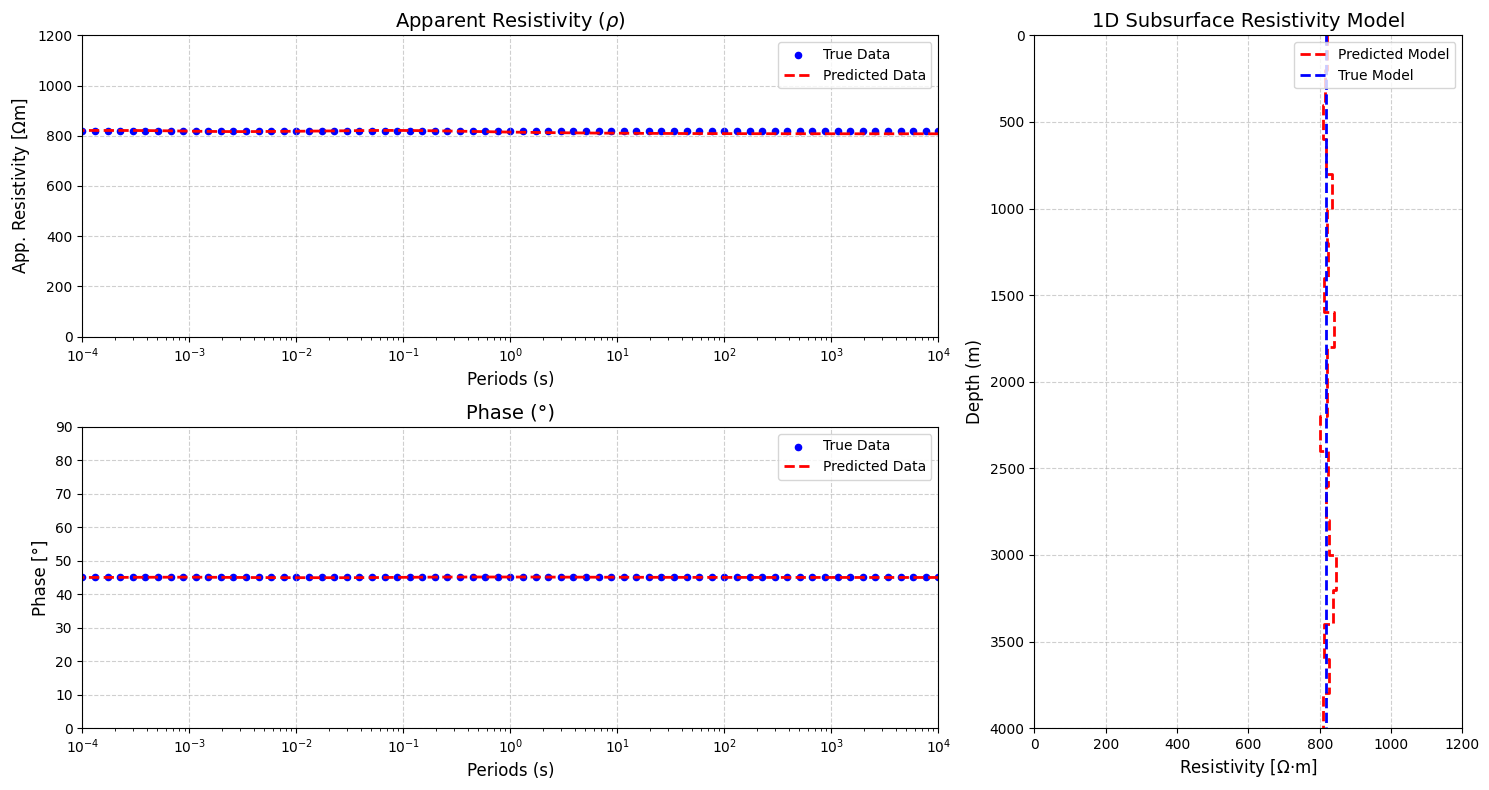

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

## Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 41.18
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 0.64%
MAPE fasa: 0.11%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 6.42
RMSE Fasa: 0.07


[Interpolated] MSE model resistivitas: 126.6817
[Interpolated] RMSE model resistivitas: 11.2553
[Interpolated] MAPE model resistivitas: 1.04%


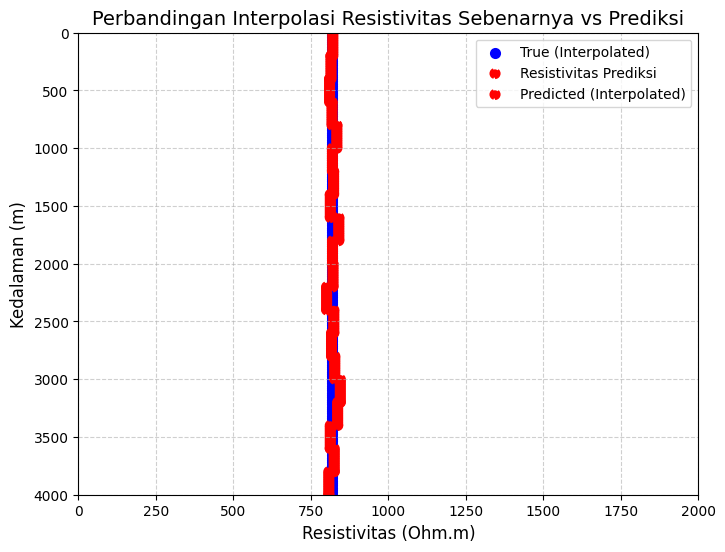

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Data validasi

## Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_val[2].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_val_res[2].reshape(1, -1)
fasa = X_val_phase[2].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai resis_predict [818.09753 948.69965 952.86017 960.4327  942.11707 925.71014 961.57855
 904.3097  979.6807  951.2055  955.77466 940.2487  839.65594 559.29333
 561.8957  528.15063 547.2303  521.33264 524.15906 518.40533]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


## Grafik

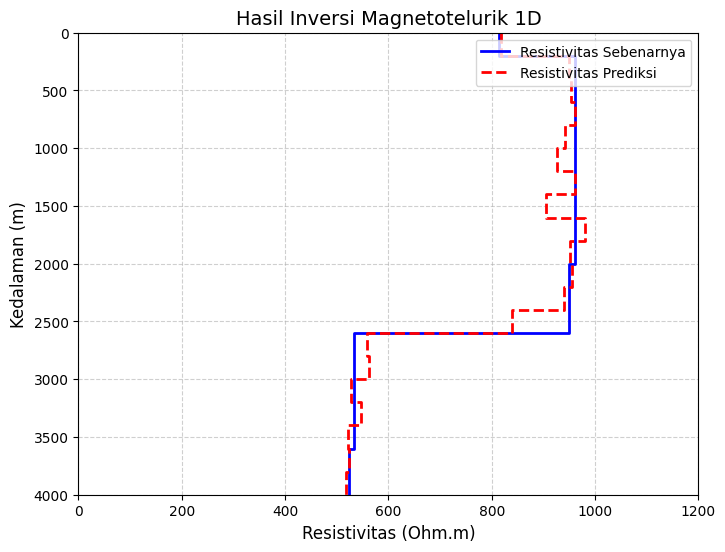

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

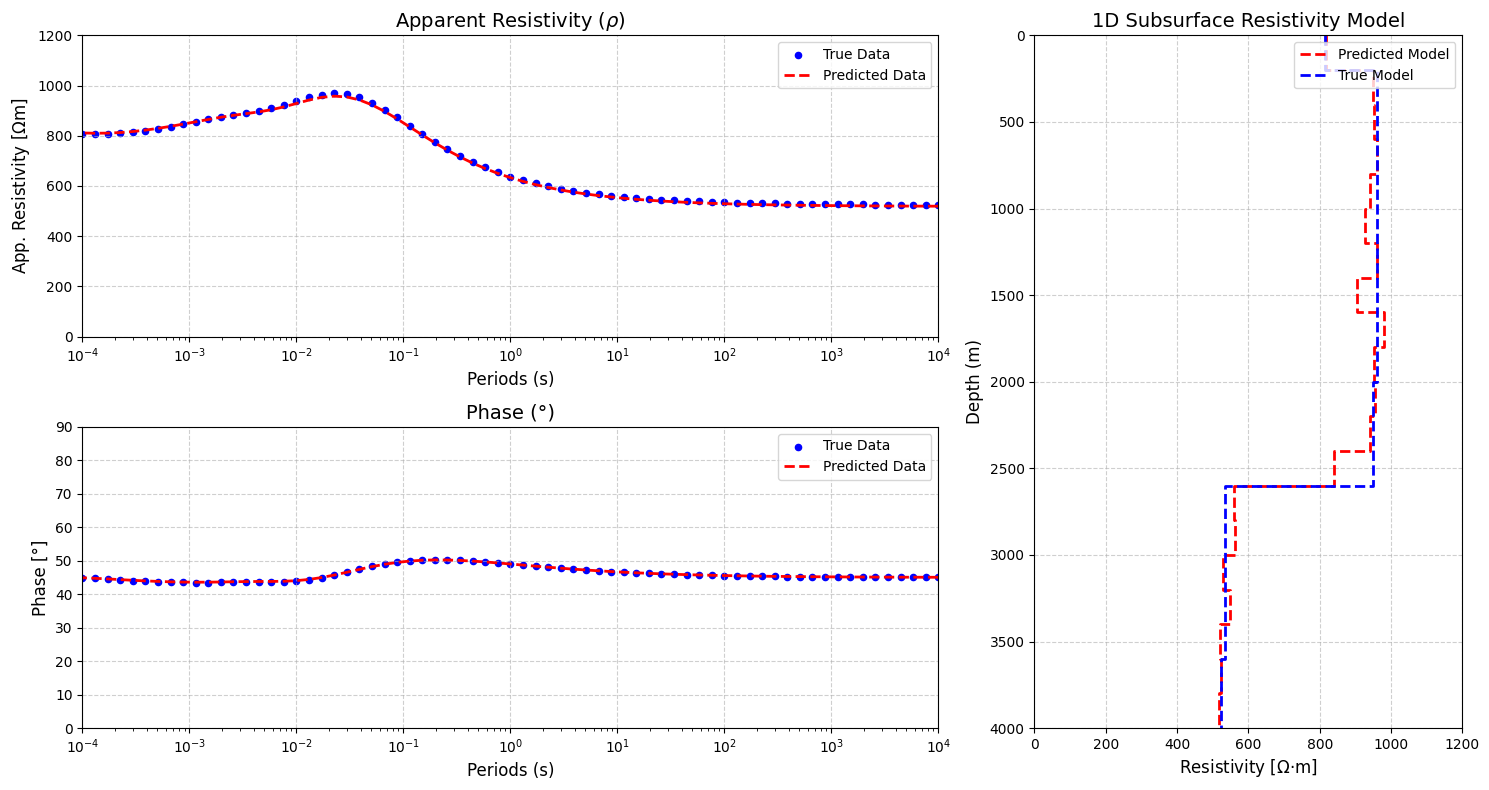

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

## Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 31.63
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.78%
MAPE fasa: 0.11%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 5.62
RMSE Fasa: 0.07


[Interpolated] MSE model resistivitas: 974.3406
[Interpolated] RMSE model resistivitas: 31.2144
[Interpolated] MAPE model resistivitas: 2.38%


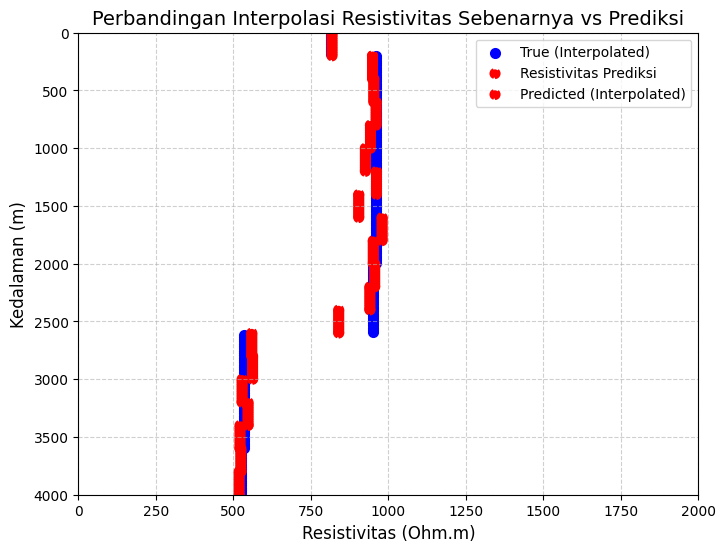

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi Homogen

## Model Bumi Homogen I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 100])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [100 100]
Nilai ketebalan_True [2000]
Nilai resis_predict [101.53285  102.84658  100.22984  104.15981  101.61939   97.06133
 104.02278  101.10168  106.07122  102.07138   98.738945  97.56168
  99.472786  97.95415  100.01395   98.4465    96.78348   97.32326
  98.95081   95.805405]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

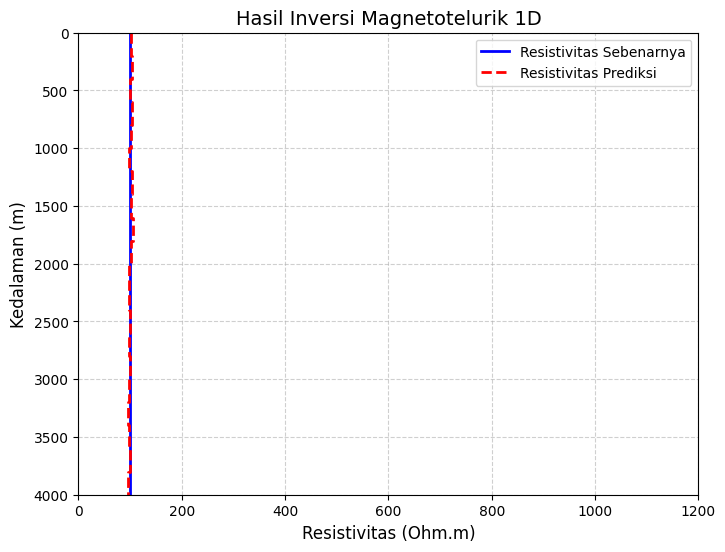

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

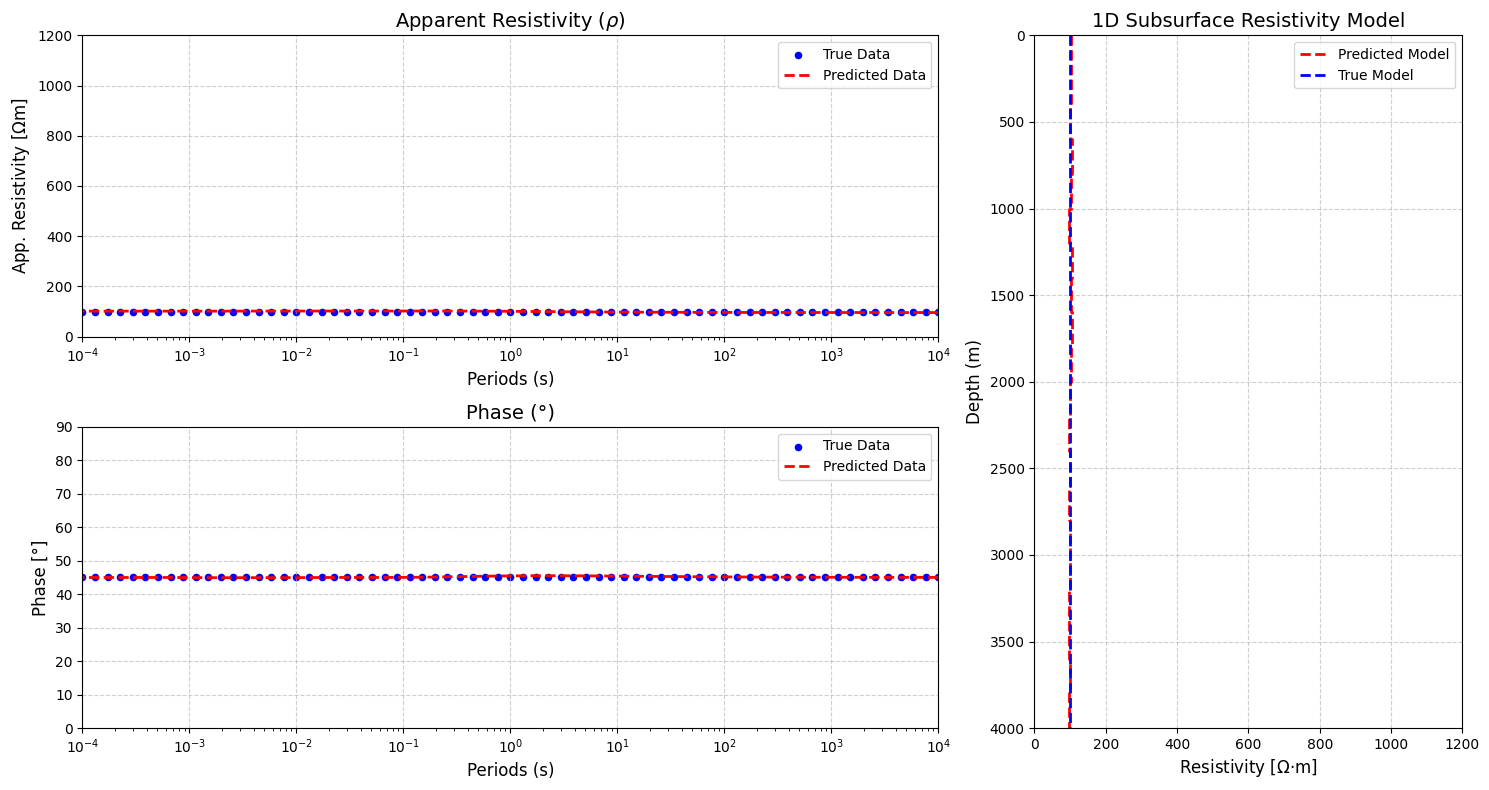

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)


MSE Resistivitas Semu: 6.70
MSE Fasa: 0.05


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)


MAPE resistivitas semu: 2.33%
MAPE fasa: 0.34%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 2.59
RMSE Fasa: 0.23


[Interpolated] MSE model resistivitas: 7.4117
[Interpolated] RMSE model resistivitas: 2.7224
[Interpolated] MAPE model resistivitas: 2.28%


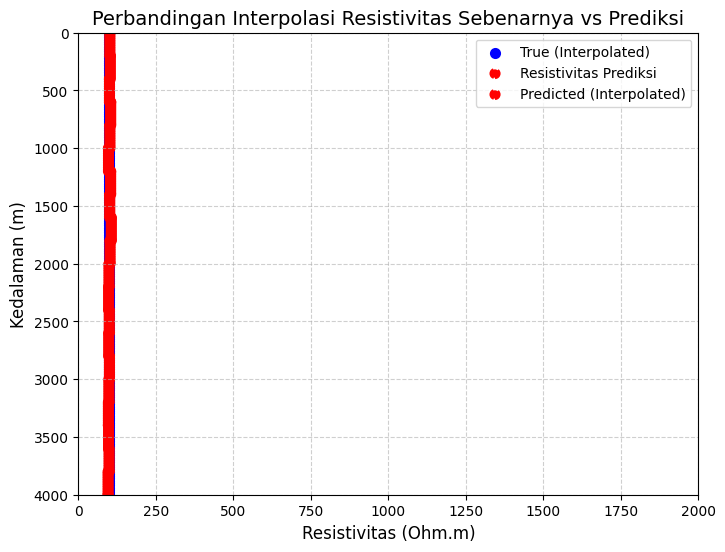

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi Homogen II

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([50, 50])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Dataset
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [50 50]
Nilai ketebalan_True [2000]
Nilai resis_predict [49.874096 51.9134   48.28141  51.769703 50.1057   49.419376 51.555023
 49.216534 49.65082  48.1486   46.612198 46.05174  47.482956 47.153923
 47.51516  47.136337 47.781265 49.687836 48.844036 47.37069 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

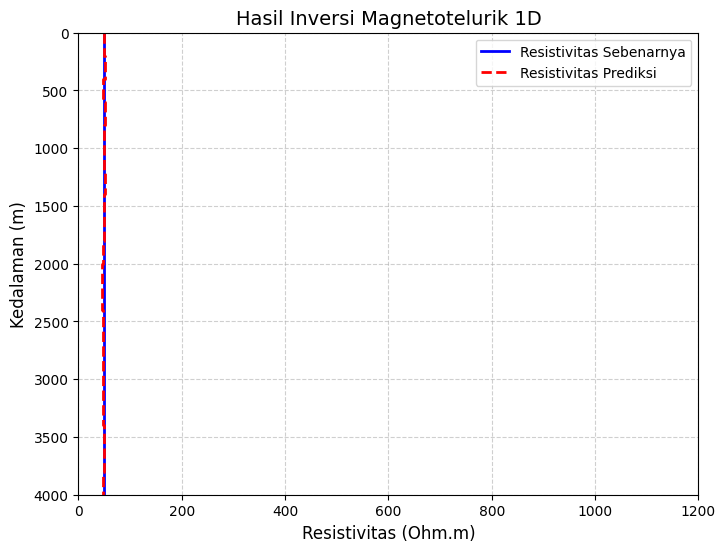

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

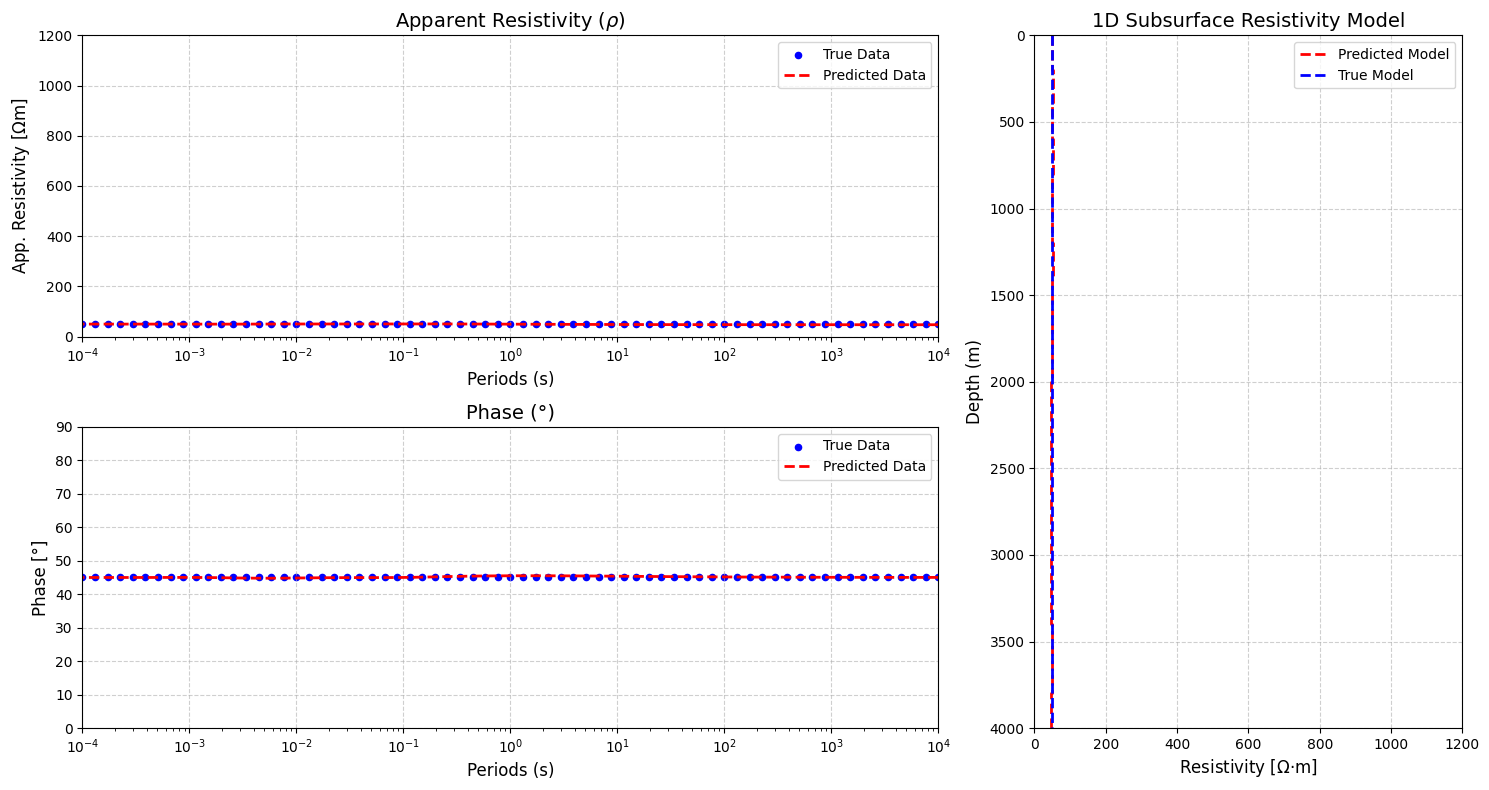

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, 1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 2.34
MSE Fasa: 0.06


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 2.31%
MAPE fasa: 0.37%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 1.53
RMSE Fasa: 0.24


[Interpolated] MSE model resistivitas: 4.2919
[Interpolated] RMSE model resistivitas: 2.0717
[Interpolated] MAPE model resistivitas: 3.51%


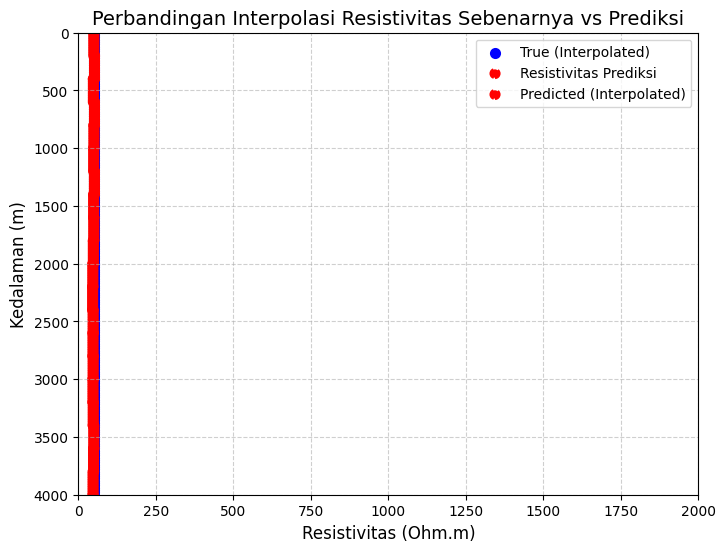

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi Homogen III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([500, 500])
ketebalan_true = np.array([2000])
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)
period = 1/frequencies

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Dataset
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [500 500]
Nilai ketebalan_True [2000]
Nilai resis_predict [499.3645  505.70694 500.71893 491.2594  512.5158  489.82407 502.4926
 500.3318  514.8366  503.73798 491.69406 486.92902 518.5593  502.97144
 502.8246  501.3378  504.10205 501.258   504.87003 488.12433]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

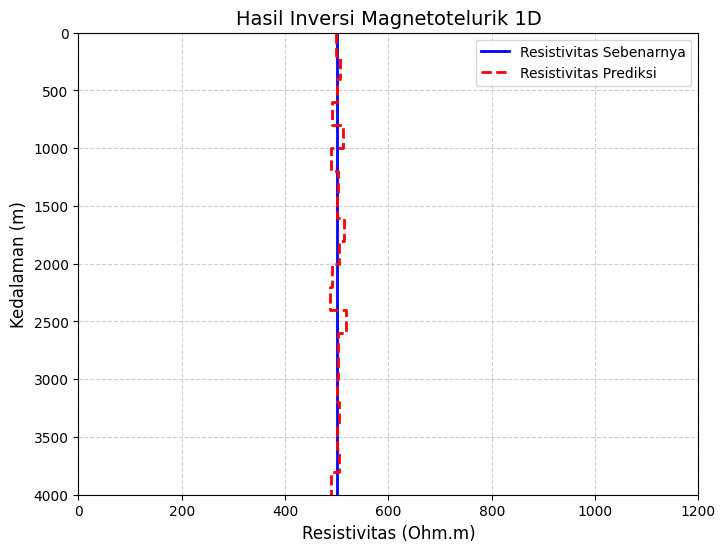

In [ ]:

plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

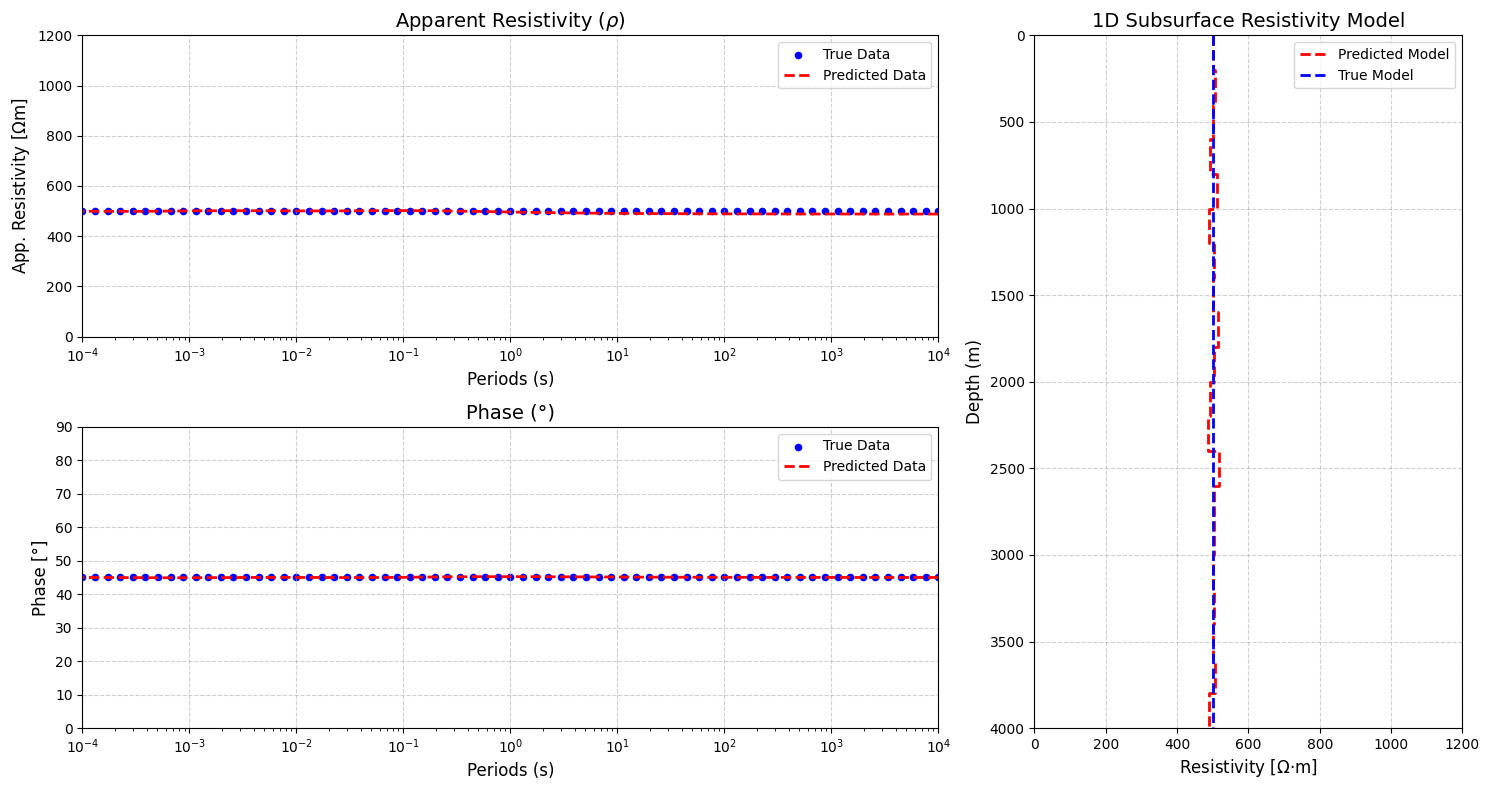

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict,1/frequencies, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 53.36
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 1.12%
MAPE fasa: 0.16%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.30
RMSE Fasa: 0.10


[Interpolated] MSE model resistivitas: 69.8274
[Interpolated] RMSE model resistivitas: 8.3563
[Interpolated] MAPE model resistivitas: 1.29%


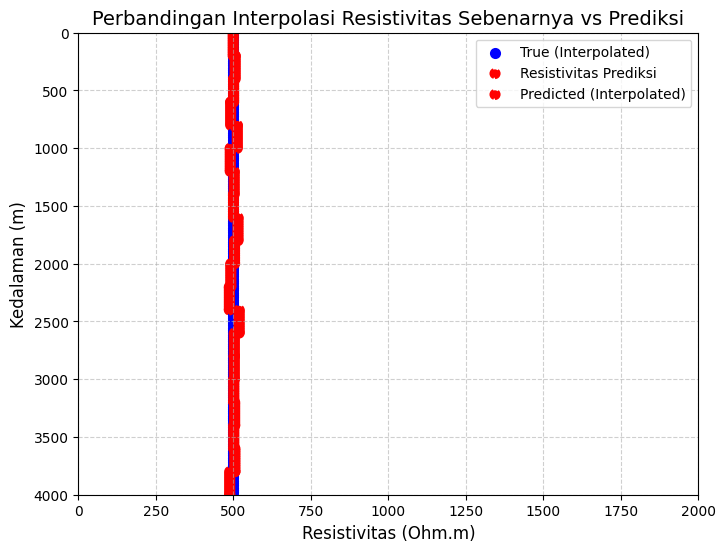

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 2 Lapis

## Model Bumi 2 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 200])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai Resis_True [ 50 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 49.453354  50.343857  51.80015   55.139336  49.096123 299.5383
 166.93634  160.842    215.0883   215.38347  229.30879  239.73485
 231.95801  194.03537  183.44743  184.34573  188.71097  185.42894
 188.05963  185.02545 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

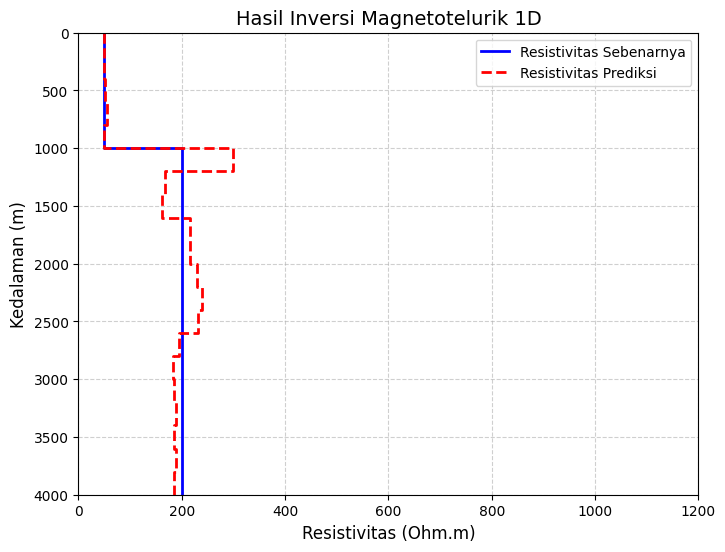

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

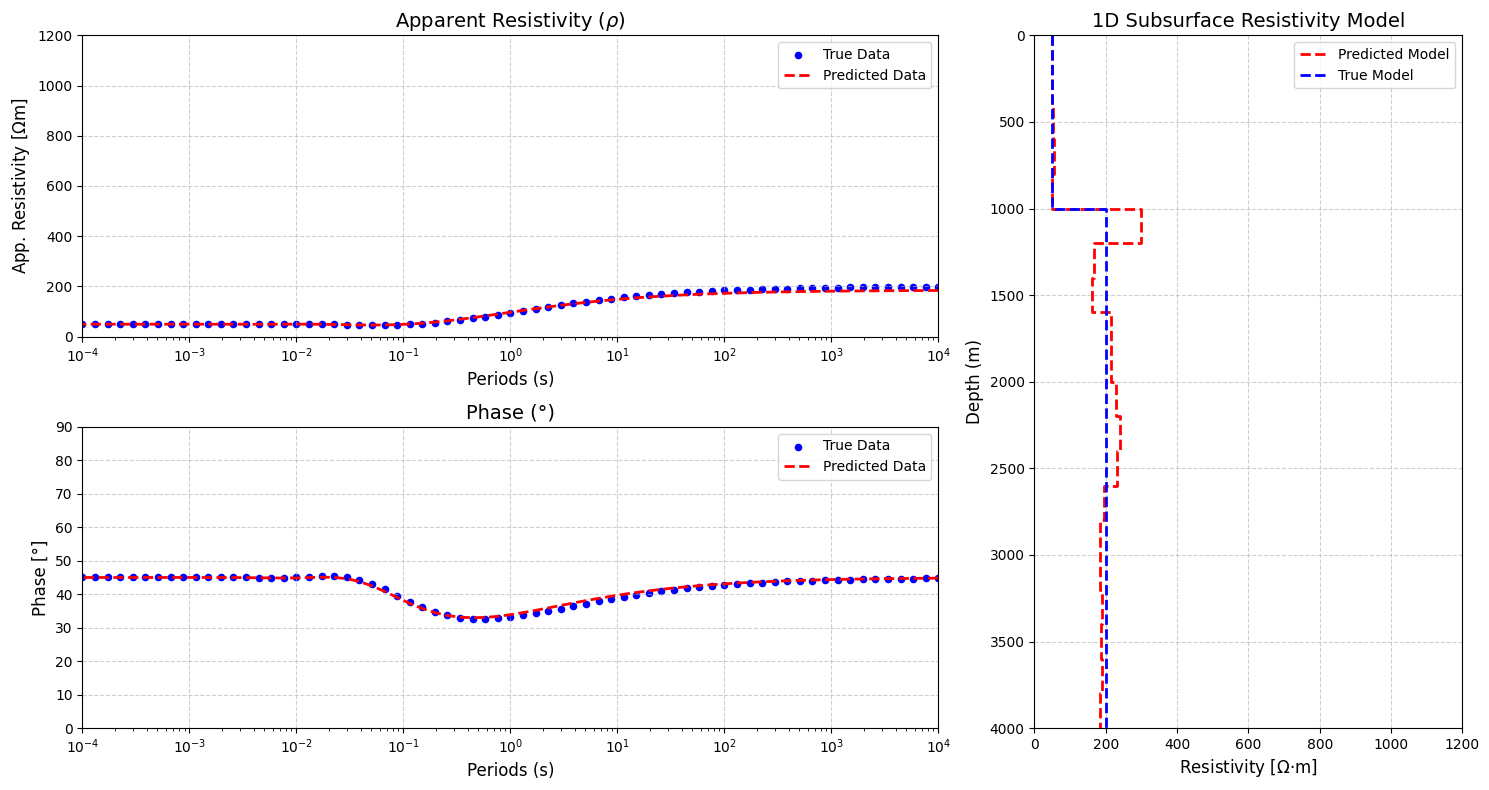

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 58.06
MSE Fasa: 0.20


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.38%
MAPE fasa: 0.85%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.62
RMSE Fasa: 0.45


[Interpolated] MSE model resistivitas: 887.4994
[Interpolated] RMSE model resistivitas: 29.7909
[Interpolated] MAPE model resistivitas: 10.73%


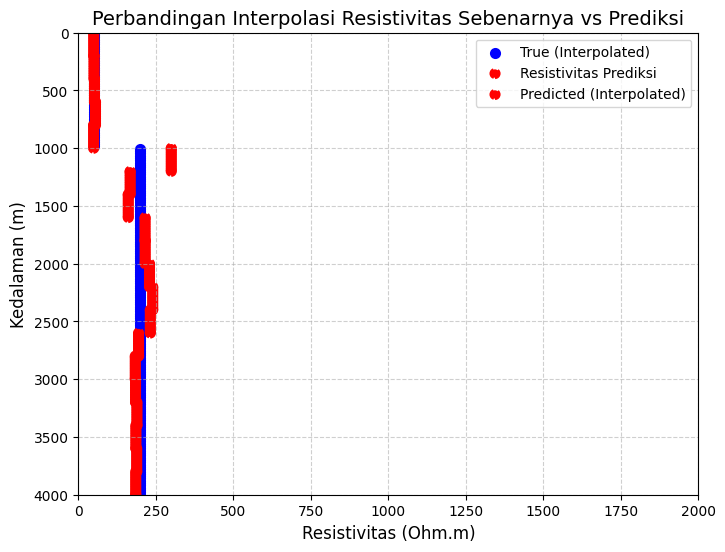

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 50])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [200  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [201.99939  210.85164  204.87125  190.95561  208.07648   53.23982
  51.881046  49.620518  53.00765   49.385284  52.00566   48.122124
  48.165695  50.26597   51.10092   50.51456   49.55577   50.77421
  50.632946  45.935326]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

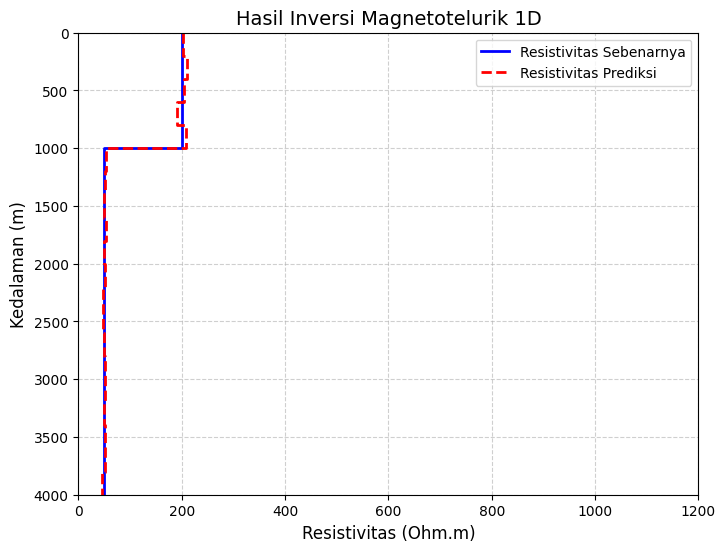

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

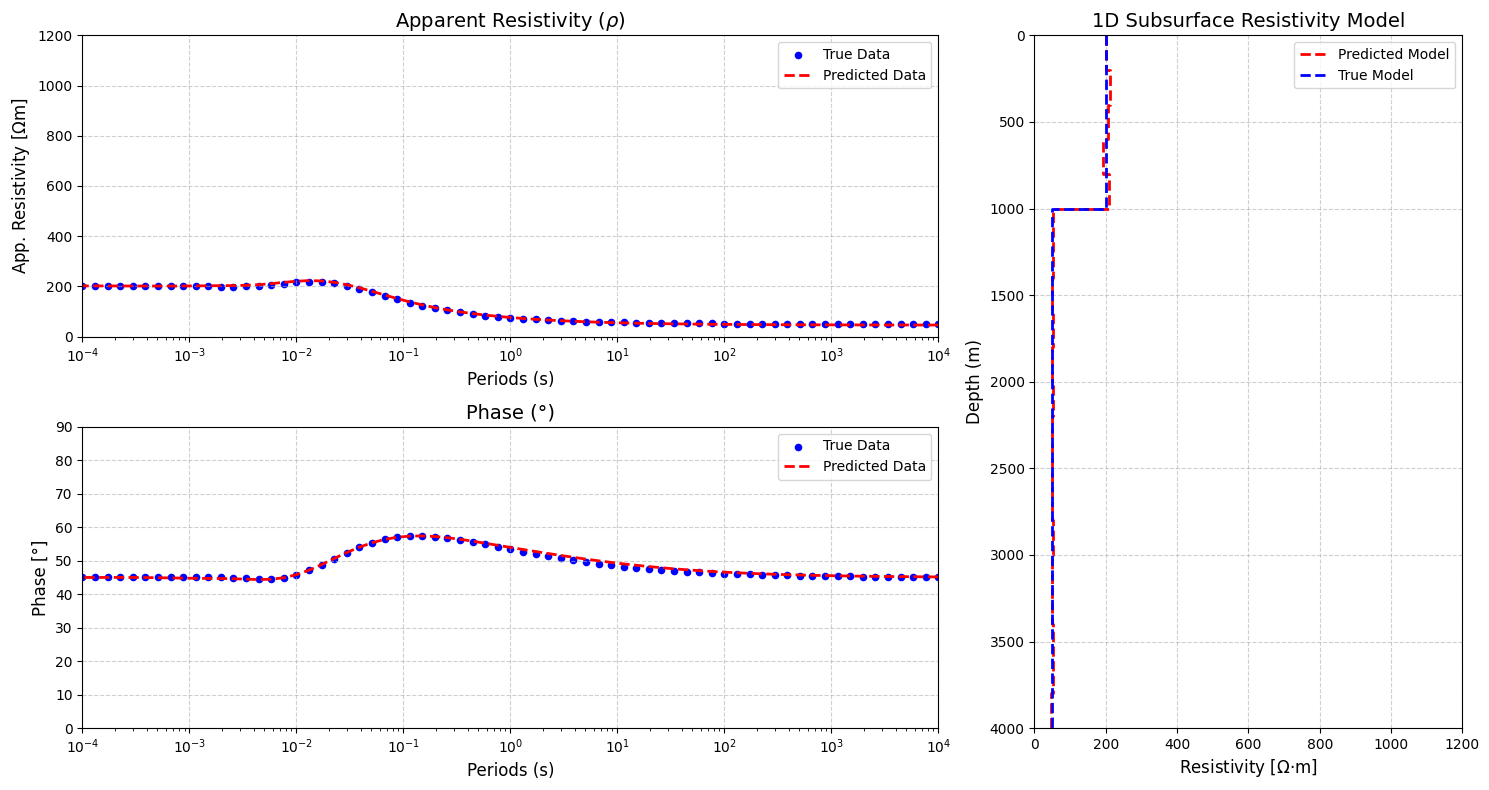

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 9.72
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.56%
MAPE fasa: 0.58%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 3.12
RMSE Fasa: 0.40


[Interpolated] MSE model resistivitas: 17.3149
[Interpolated] RMSE model resistivitas: 4.1611
[Interpolated] MAPE model resistivitas: 3.13%


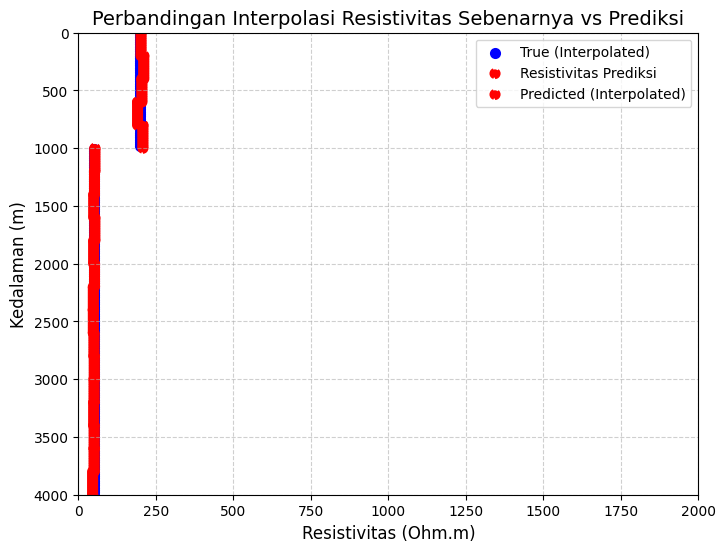

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50,800])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [ 50 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 47.090893  46.03627   48.983025  50.96728   50.337543 794.9396
 850.91156  820.75165  797.54175  801.2967   778.7797   808.8596
 828.7188   782.485    772.2595   768.9568   752.97656  726.9644
 721.97107  789.1492  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

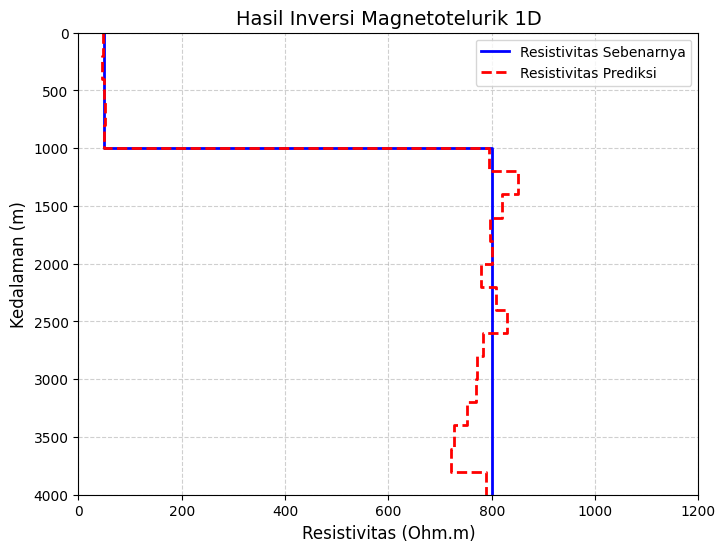

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

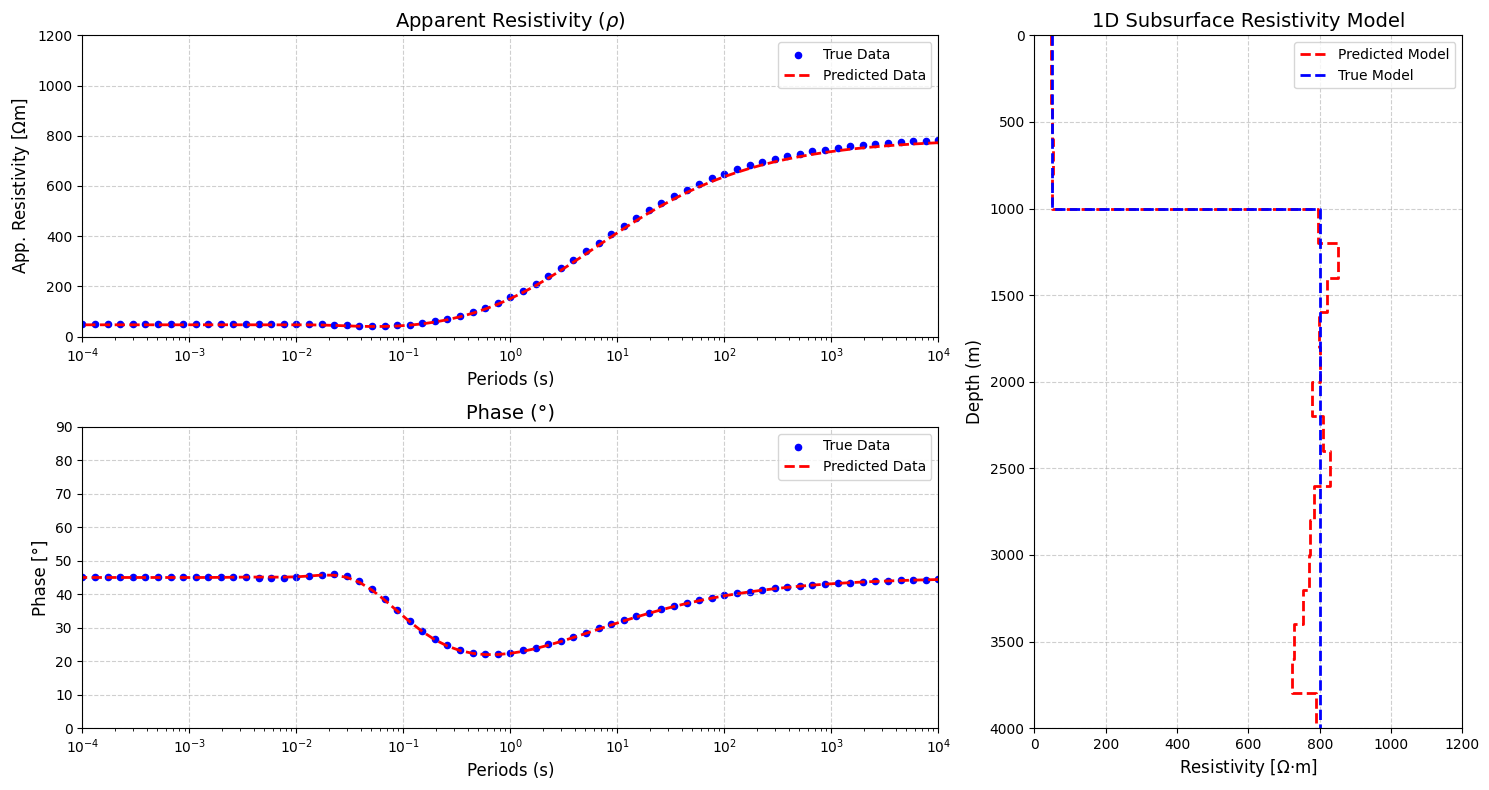

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 66.33
MSE Fasa: 0.03


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 3.85%
MAPE fasa: 0.40%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 8.14
RMSE Fasa: 0.16


[Interpolated] MSE model resistivitas: 1011.3708
[Interpolated] RMSE model resistivitas: 31.8021
[Interpolated] MAPE model resistivitas: 3.57%


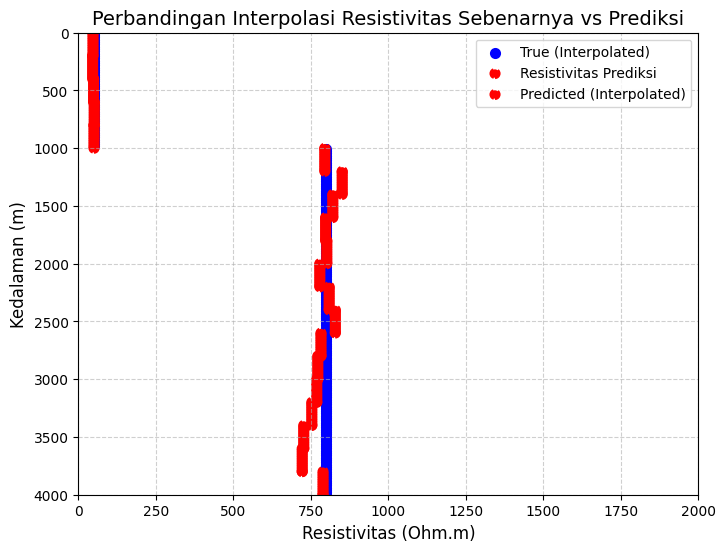

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 50])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Nilai Resis_True [800  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [819.91125  786.0227   767.5852   795.2552   777.54004   46.117455
  48.965576  48.425392  51.206947  49.946198  48.567482  48.03293
  50.538403  50.753433  51.532894  48.12886   48.669384  49.33476
  50.214653  47.625717]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

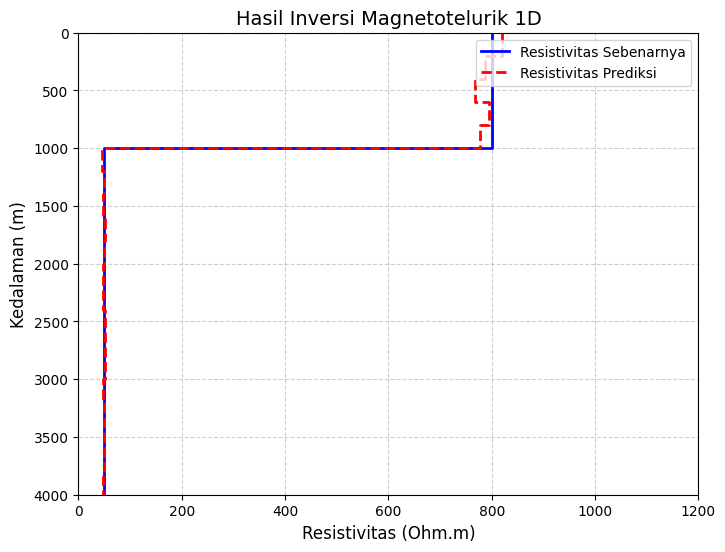

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

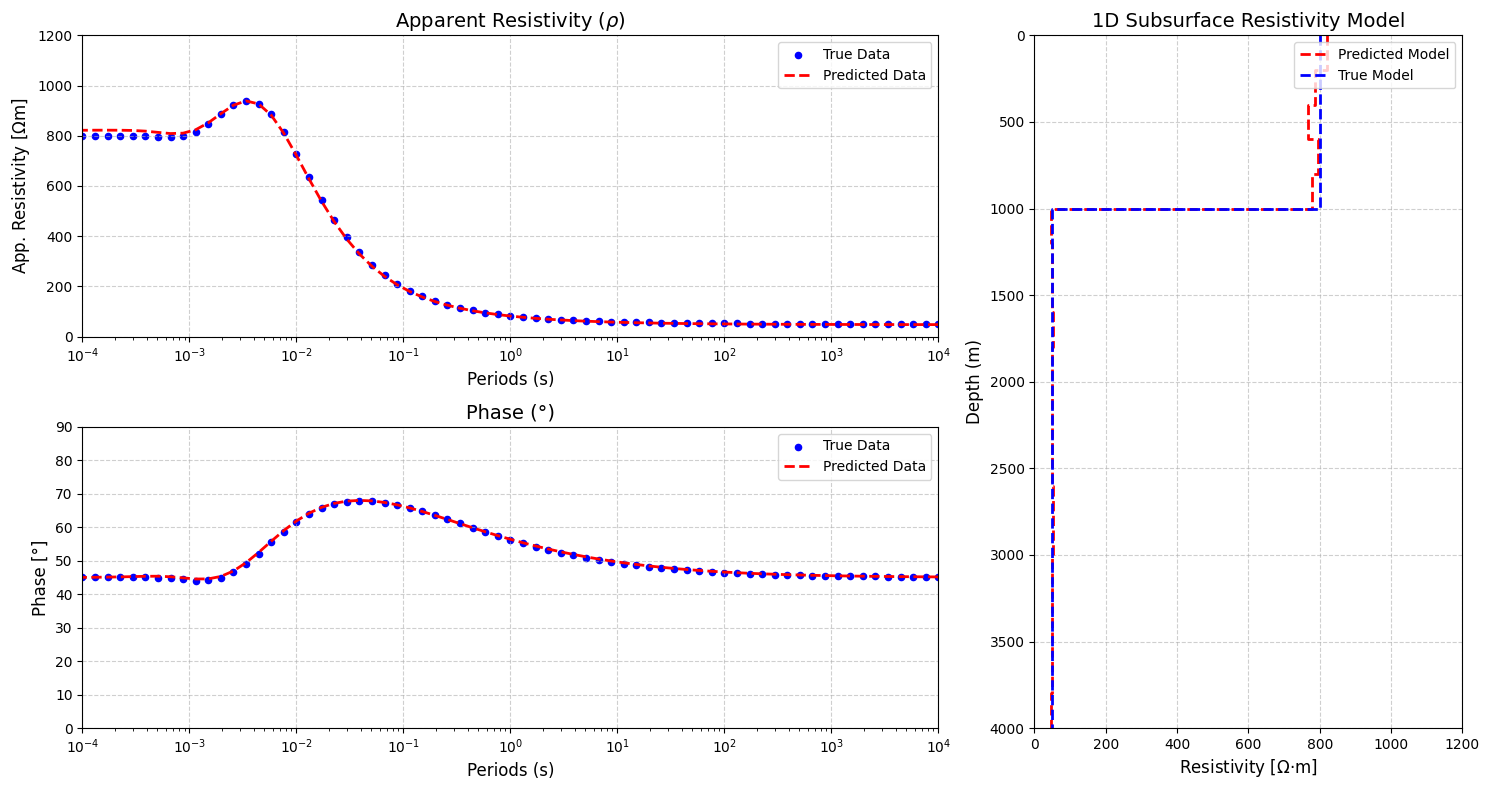

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 58.61
MSE Fasa: 0.05


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 2.60%
MAPE fasa: 0.37%


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 7.66
RMSE Fasa: 0.23


[Interpolated] MSE model resistivitas: 110.5057
[Interpolated] RMSE model resistivitas: 10.5122
[Interpolated] MAPE model resistivitas: 2.63%


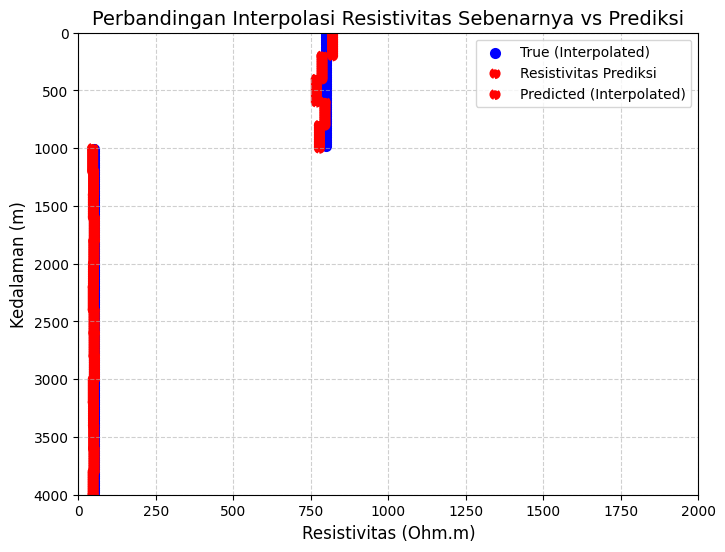

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [200 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [197.77208 203.59196 199.92126 190.58319 203.0301  813.10693 824.6724
 776.0368  793.8768  781.6791  773.07477 771.2016  812.7312  804.767
 818.1838  824.404   830.8247  814.67163 799.31213 784.361  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

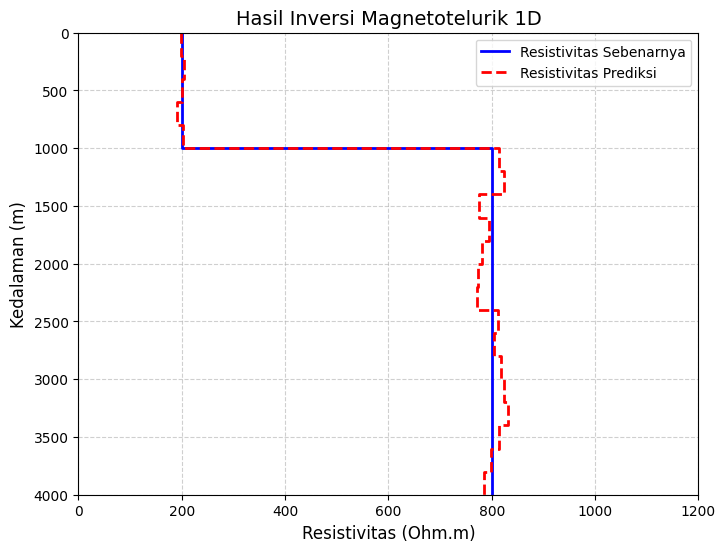

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


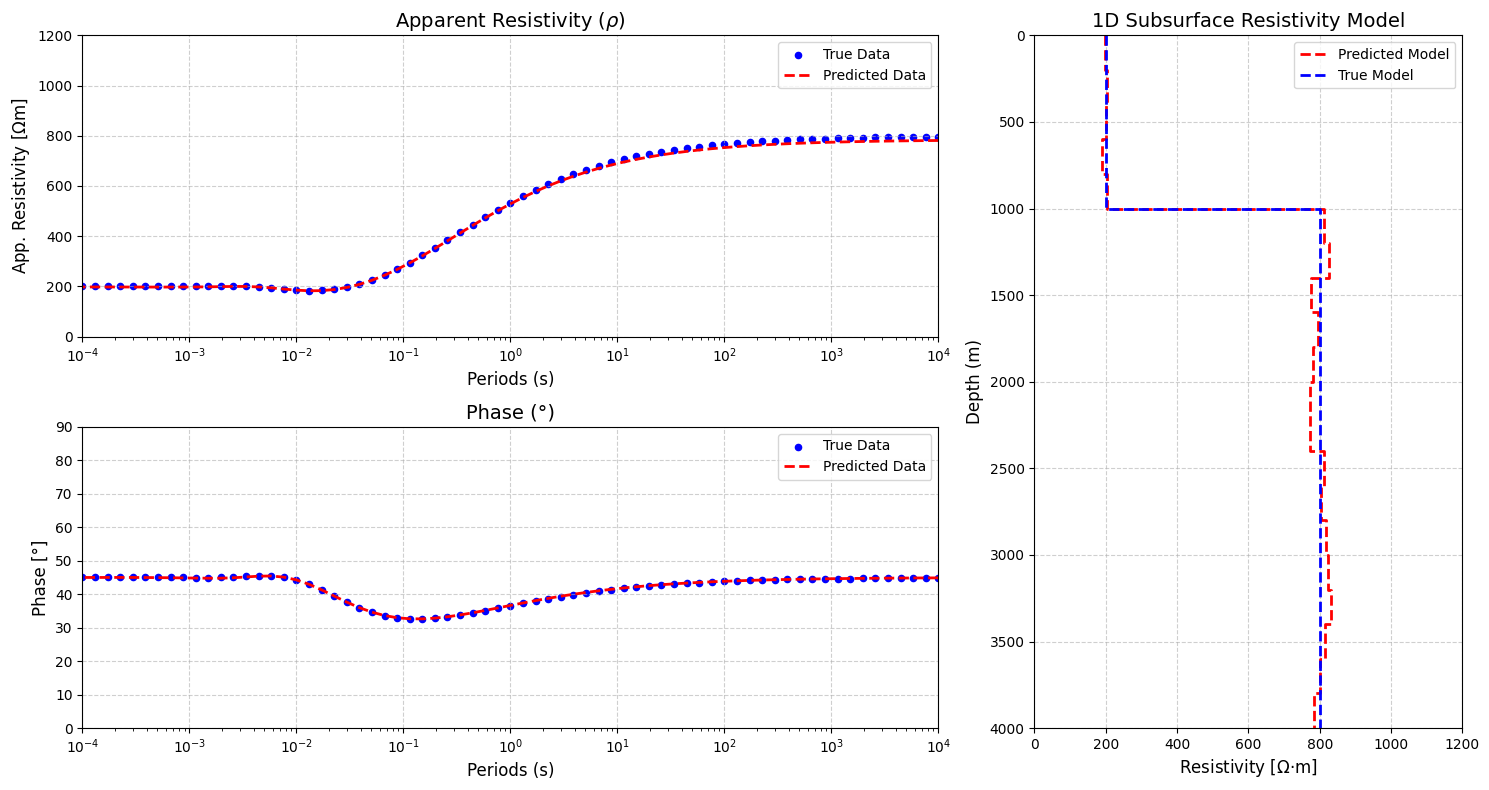

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 88.21
MSE Fasa: 0.01


In [ ]:
measure_RMSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

RMSE Resistivitas Semu: 9.39
RMSE Fasa: 0.08


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 1.20%
MAPE fasa: 0.15%


[Interpolated] MSE model resistivitas: 295.9717
[Interpolated] RMSE model resistivitas: 17.2038
[Interpolated] MAPE model resistivitas: 2.11%


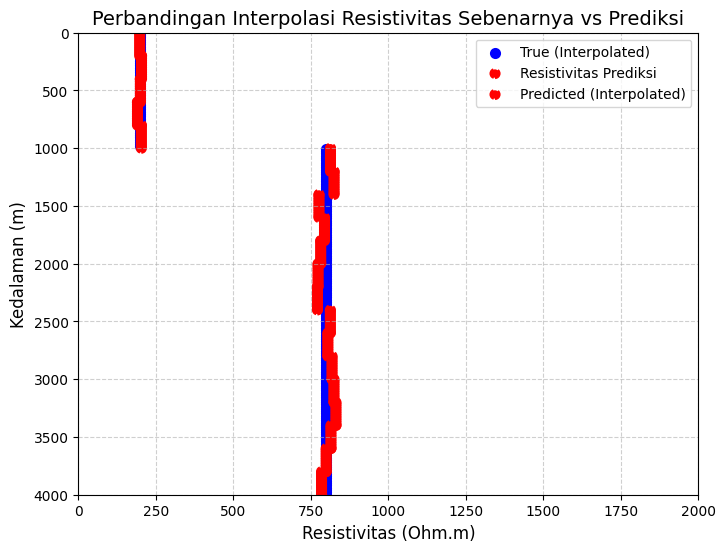

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 2 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 200])
ketebalan_true = np.array([1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [800 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [814.263   814.7048  792.2546  807.1492  799.4877  189.93625 197.94978
 194.68987 193.16597 198.76595 202.84851 201.19403 203.83331 193.23938
 201.43927 200.3171  208.98326 204.5833  204.94998 202.335  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

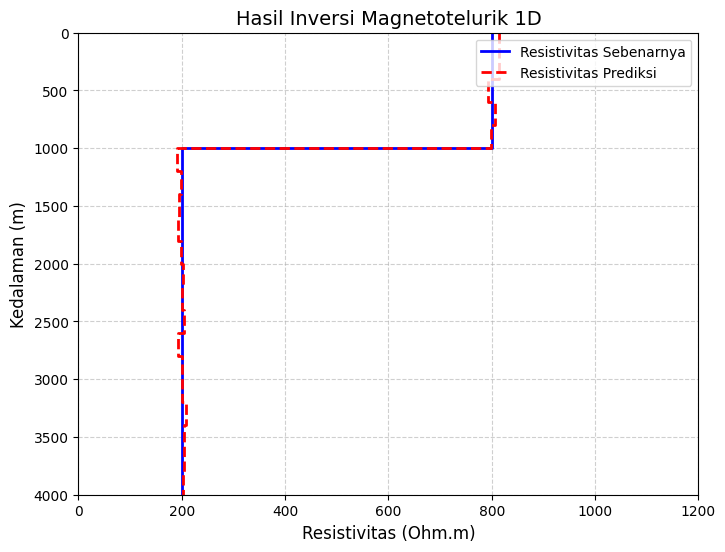

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

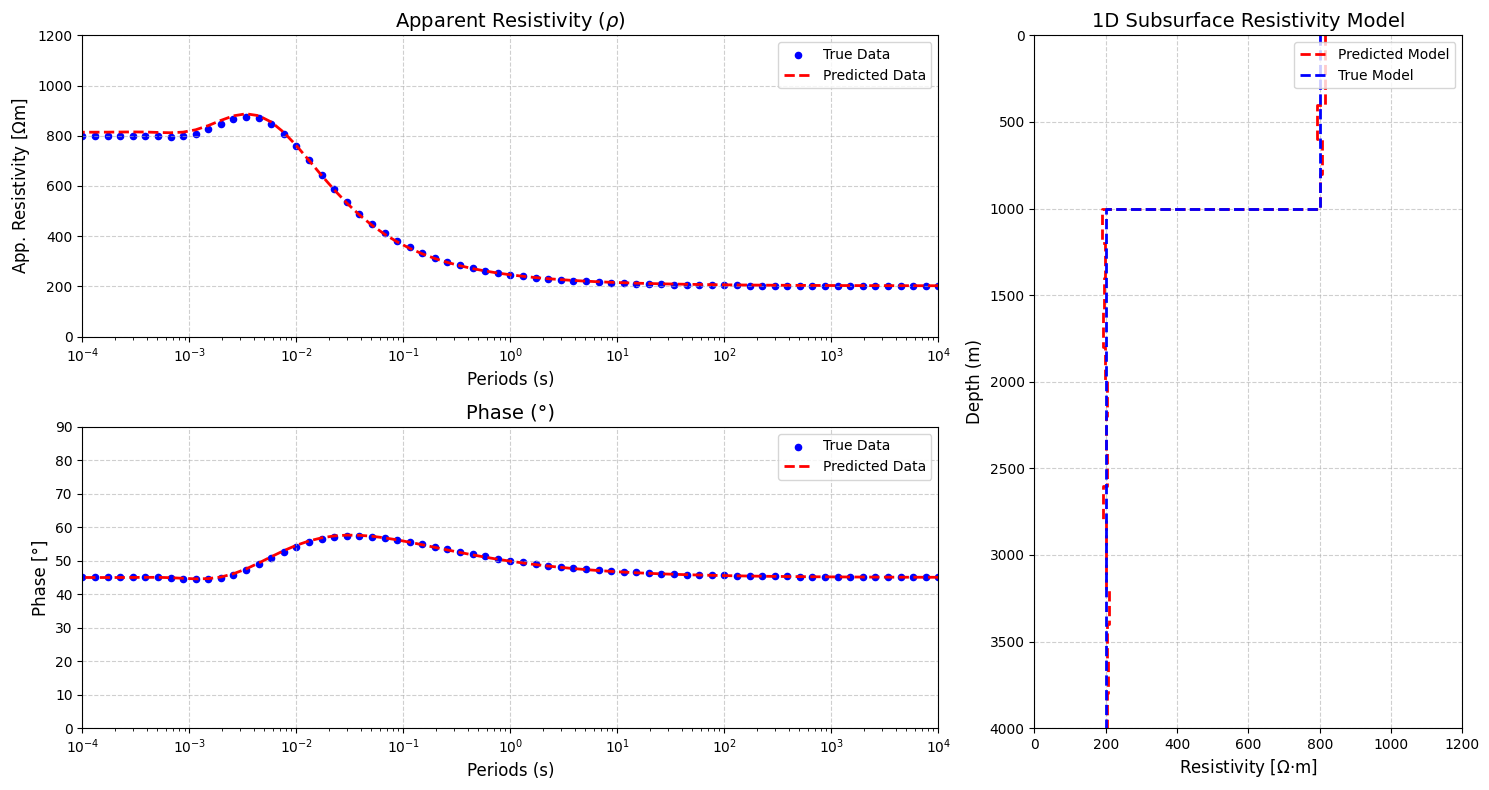

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 51.71
MSE Fasa: 0.03


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.04%
MAPE fasa: 0.22%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 7.19
RMSE Fasa: 0.16


[Interpolated] MSE model resistivitas: 45.8354
[Interpolated] RMSE model resistivitas: 6.7702
[Interpolated] MAPE model resistivitas: 1.85%


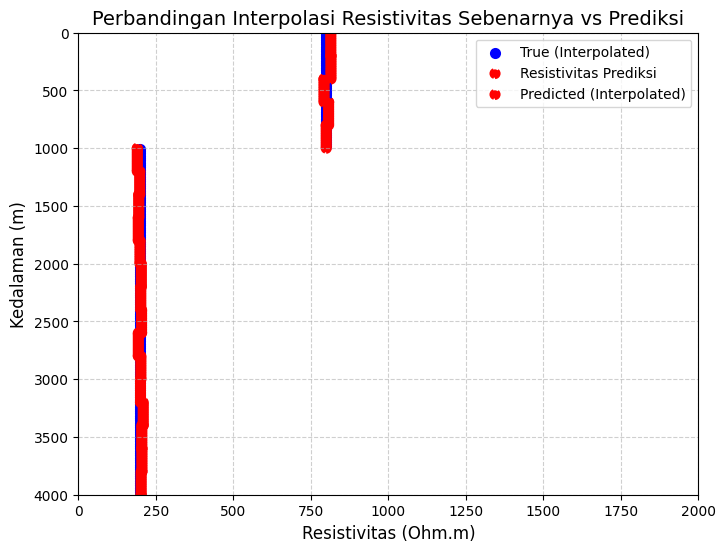

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 3 Lapis

## Model Bumi 3 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 200, 800])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [100 200 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [100.116615 120.9247   296.7307   173.53937  189.19632  166.44109
 544.5051   667.8188   718.9529   770.4044   783.2801   807.9938
 841.1821   824.22614  848.4622   833.2383   831.42017  798.6327
 798.3289   801.72345 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

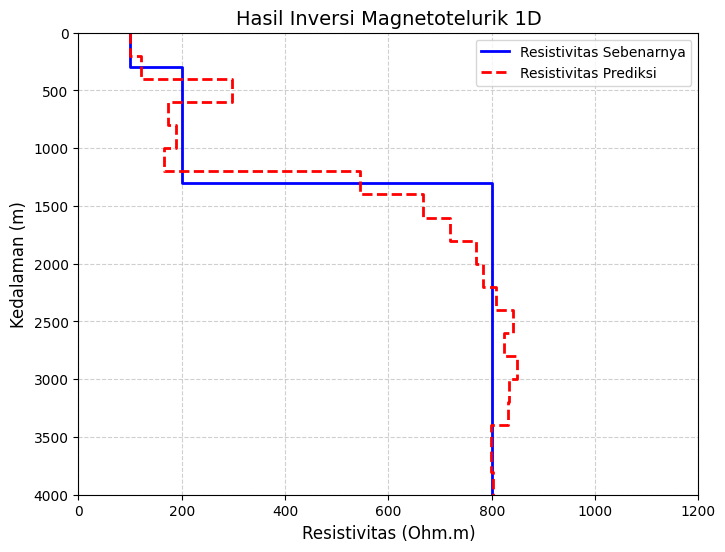

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

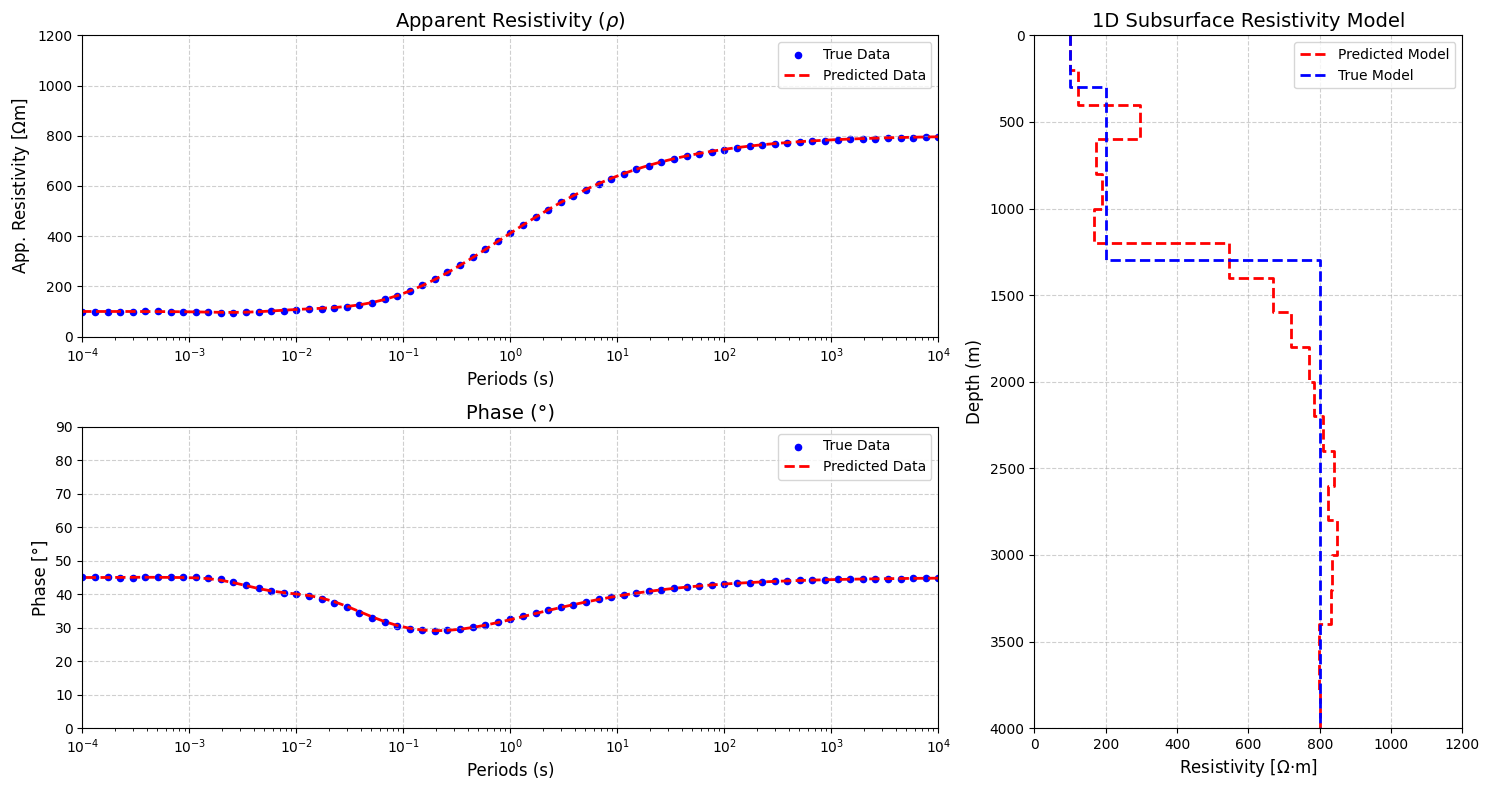

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1.19
MSE Fasa: 0.02


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.38%
MAPE fasa: 0.19%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 1.09
RMSE Fasa: 0.12


[Interpolated] MSE model resistivitas: 6930.8487
[Interpolated] RMSE model resistivitas: 83.2517
[Interpolated] MAPE model resistivitas: 13.63%


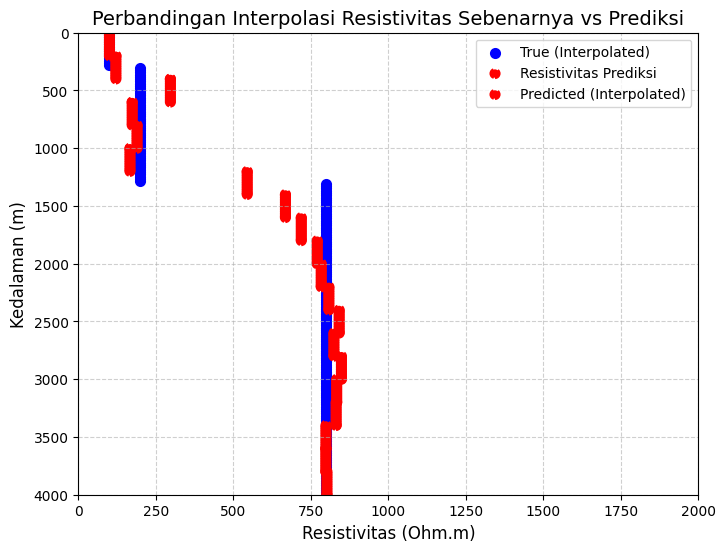

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 800, 200])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)
# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [100 800 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 104.473465  192.95316  1110.3948    607.3748    856.44257   859.557
  430.52808   167.13641   205.55373   197.22476   188.0238    193.36406
  218.2852    216.24171   210.40797   211.0842    198.95482   195.14346
  201.48251   197.9624  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

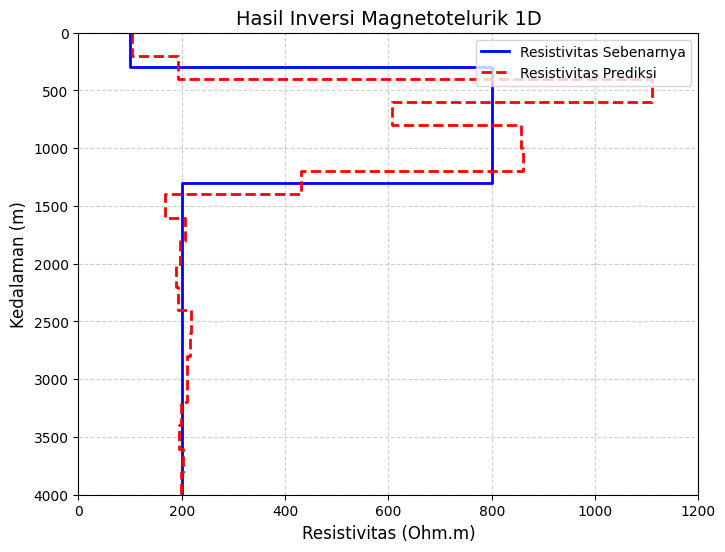

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

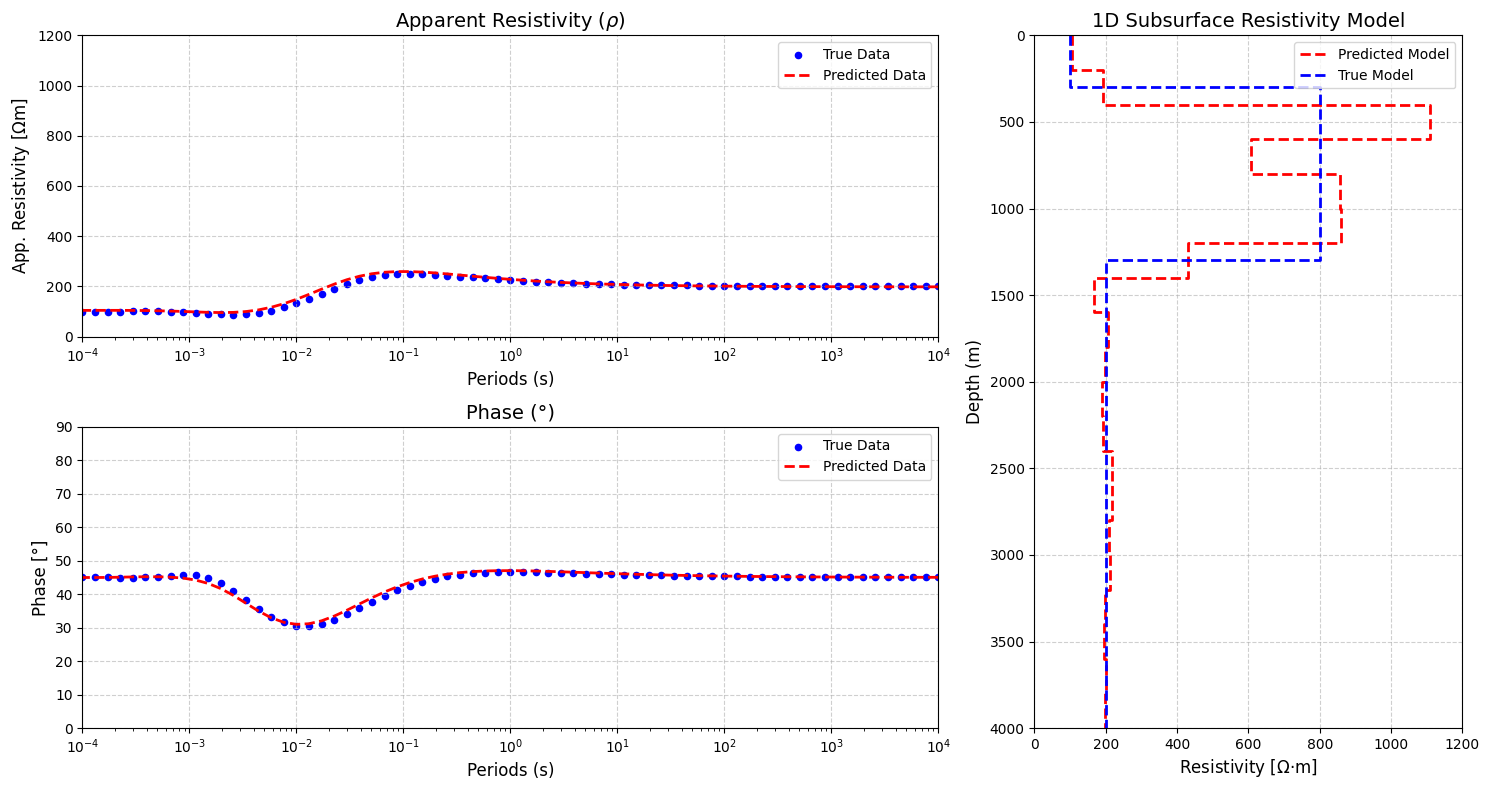

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 55.14
MSE Fasa: 0.38


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.39%
MAPE fasa: 1.02%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 7.43
RMSE Fasa: 0.61


[Interpolated] MSE model resistivitas: 21288.4000
[Interpolated] RMSE model resistivitas: 145.9054
[Interpolated] MAPE model resistivitas: 15.48%


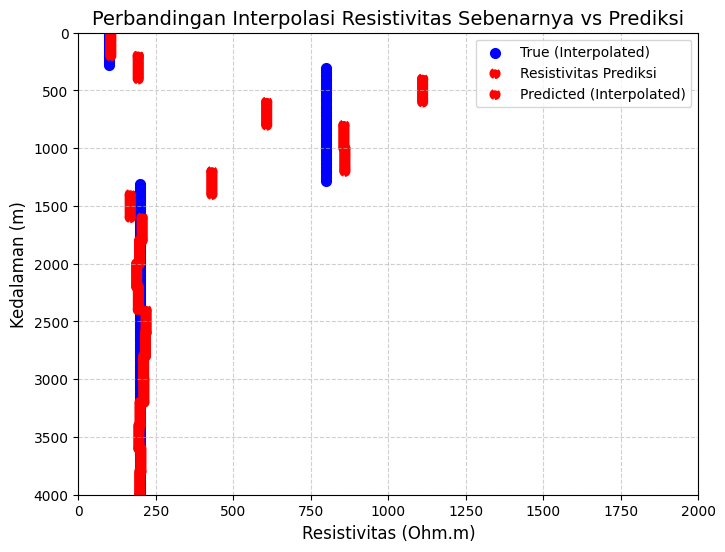

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 100, 800])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [200 100 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [194.96036 153.46823  82.62941 108.30367 108.54688  89.06888 247.78793
 704.96014 797.434   841.04456 848.0133  872.9819  885.9635  805.736
 772.8405  754.3904  773.4734  783.0419  769.25995 807.41907]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

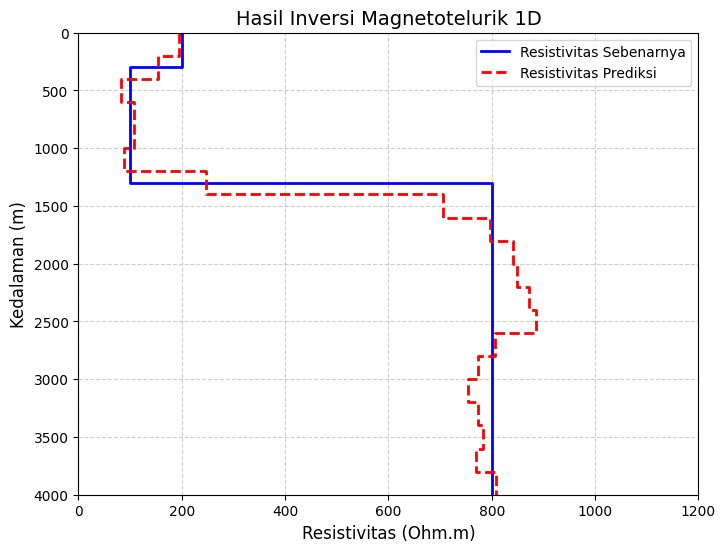

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

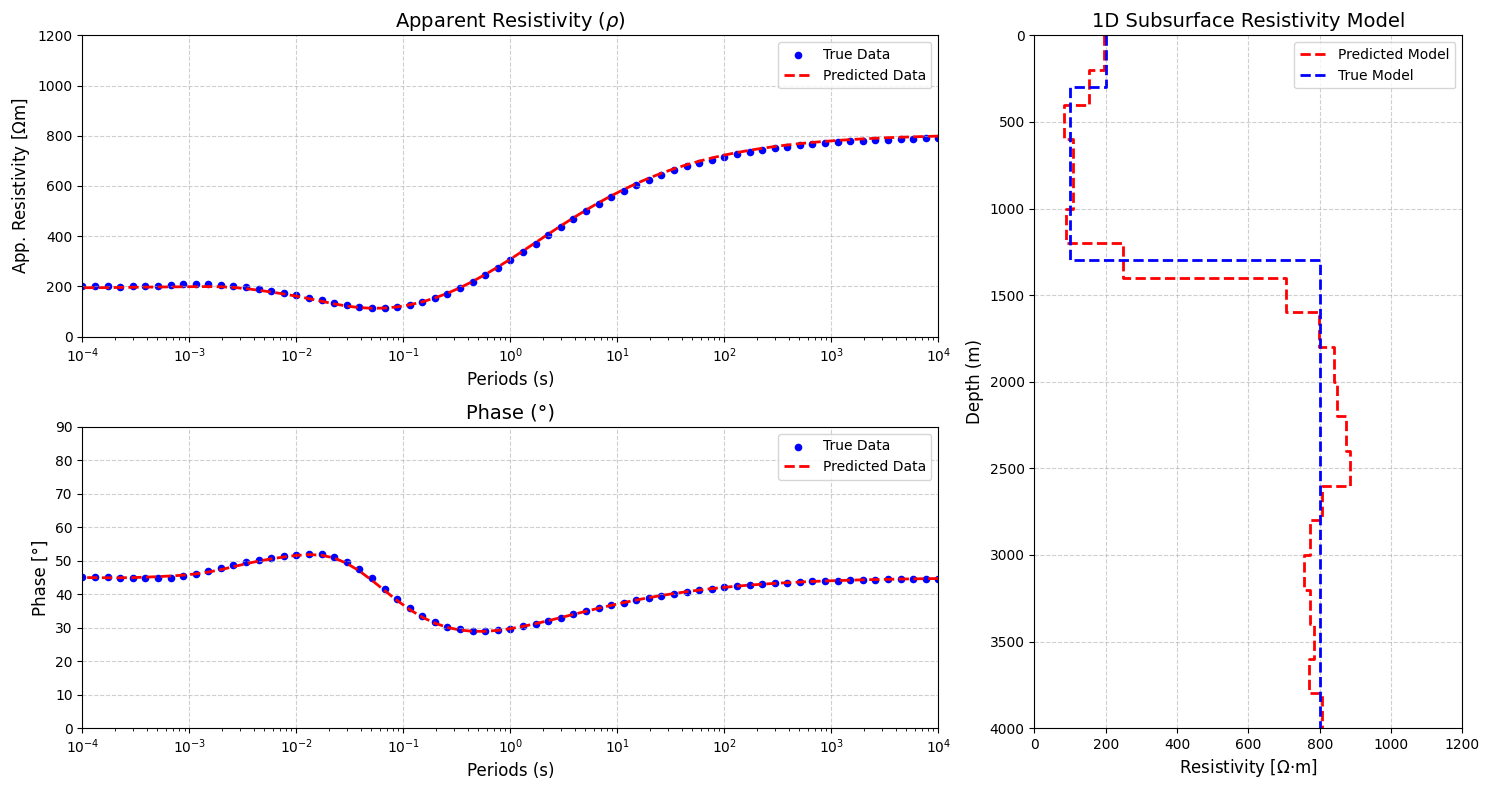

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 32.40
MSE Fasa: 0.06


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.52%
MAPE fasa: 0.35%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 5.69
RMSE Fasa: 0.24


[Interpolated] MSE model resistivitas: 9853.8776
[Interpolated] RMSE model resistivitas: 99.2667
[Interpolated] MAPE model resistivitas: 12.88%


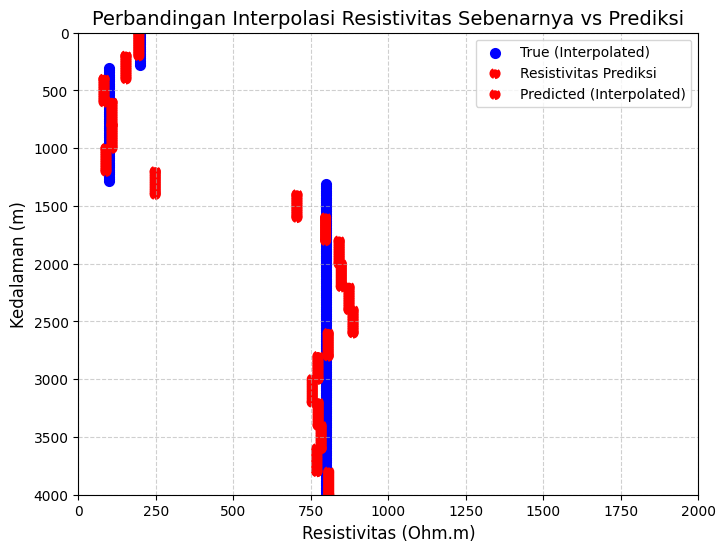

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800, 100])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai Resis_True [200 800 100]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 220.24582   302.0665   1048.029     651.1094    774.6752    823.3791
  323.1163     88.64626    94.842026   96.964455   99.27508    99.94951
  104.80377   101.105064  102.25703    98.9835     97.41742    96.8425
  102.60927   109.763985]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

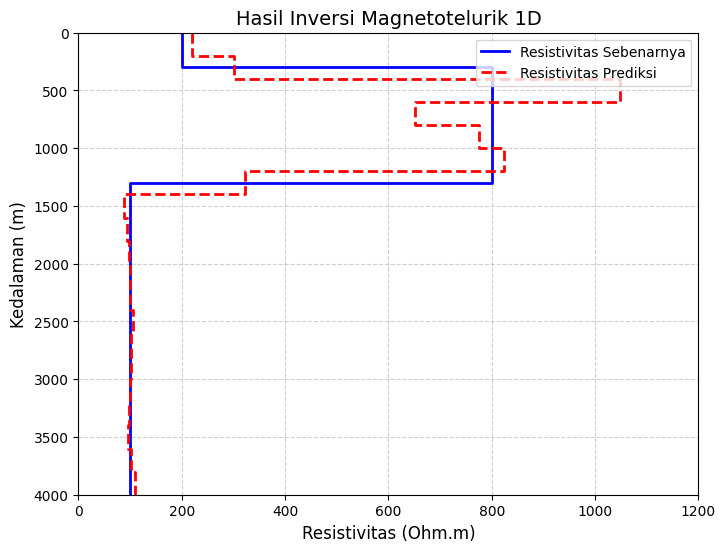

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

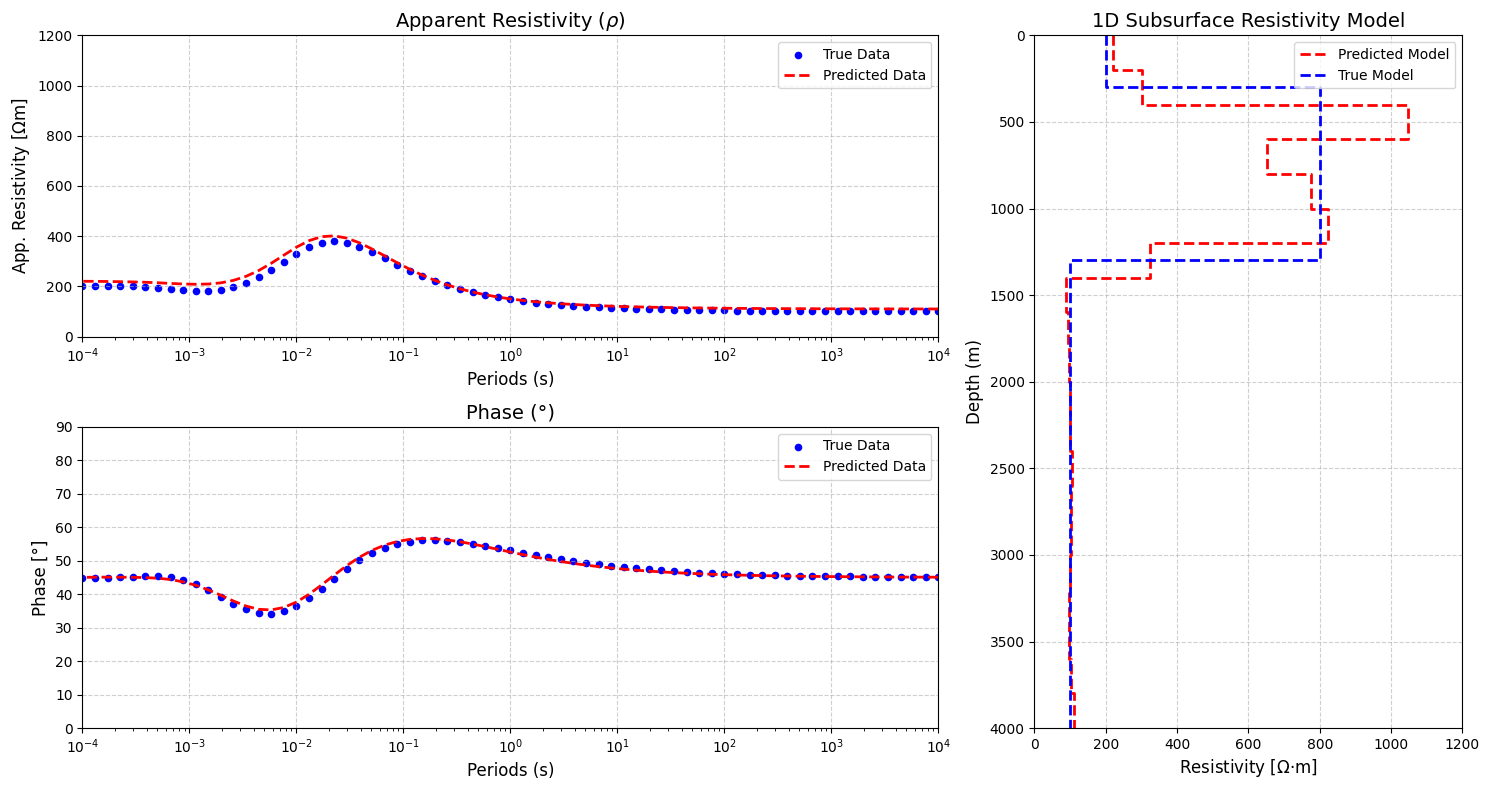

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 217.26
MSE Fasa: 0.35


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.34%
MAPE fasa: 1.05%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 14.74
RMSE Fasa: 0.59


[Interpolated] MSE model resistivitas: 17668.8129
[Interpolated] RMSE model resistivitas: 132.9241
[Interpolated] MAPE model resistivitas: 15.57%


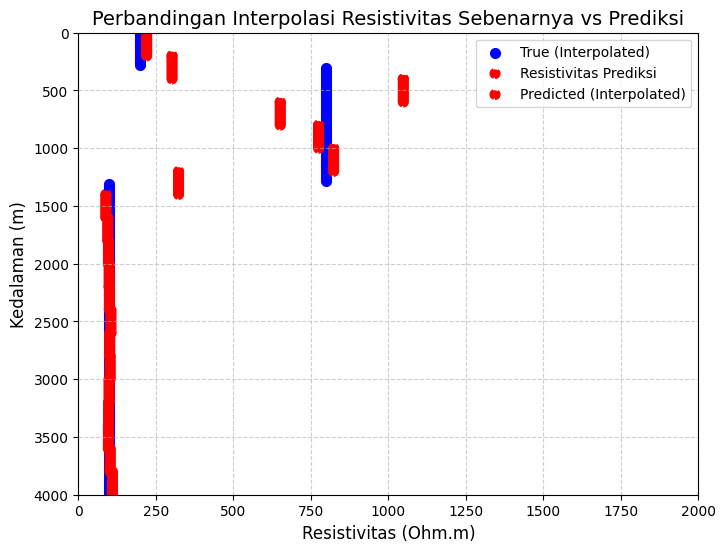

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 100, 200])
ketebalan_true = np.array([300,1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [800 100 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [886.3498   427.21896   75.570435 106.53377  103.39276   95.063545
 194.04176  151.58307  199.91972  199.96506  208.48366  211.81319
 217.70073  196.43985  193.3922   190.63196  190.6776   181.83168
 195.17924  190.6124  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

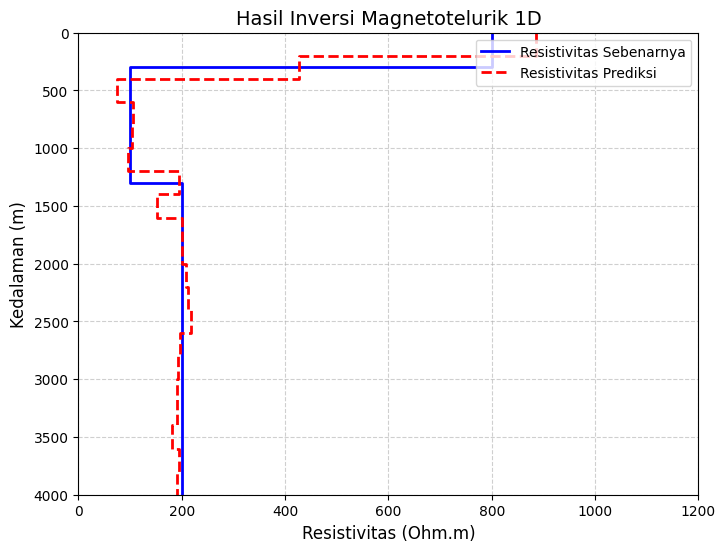

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


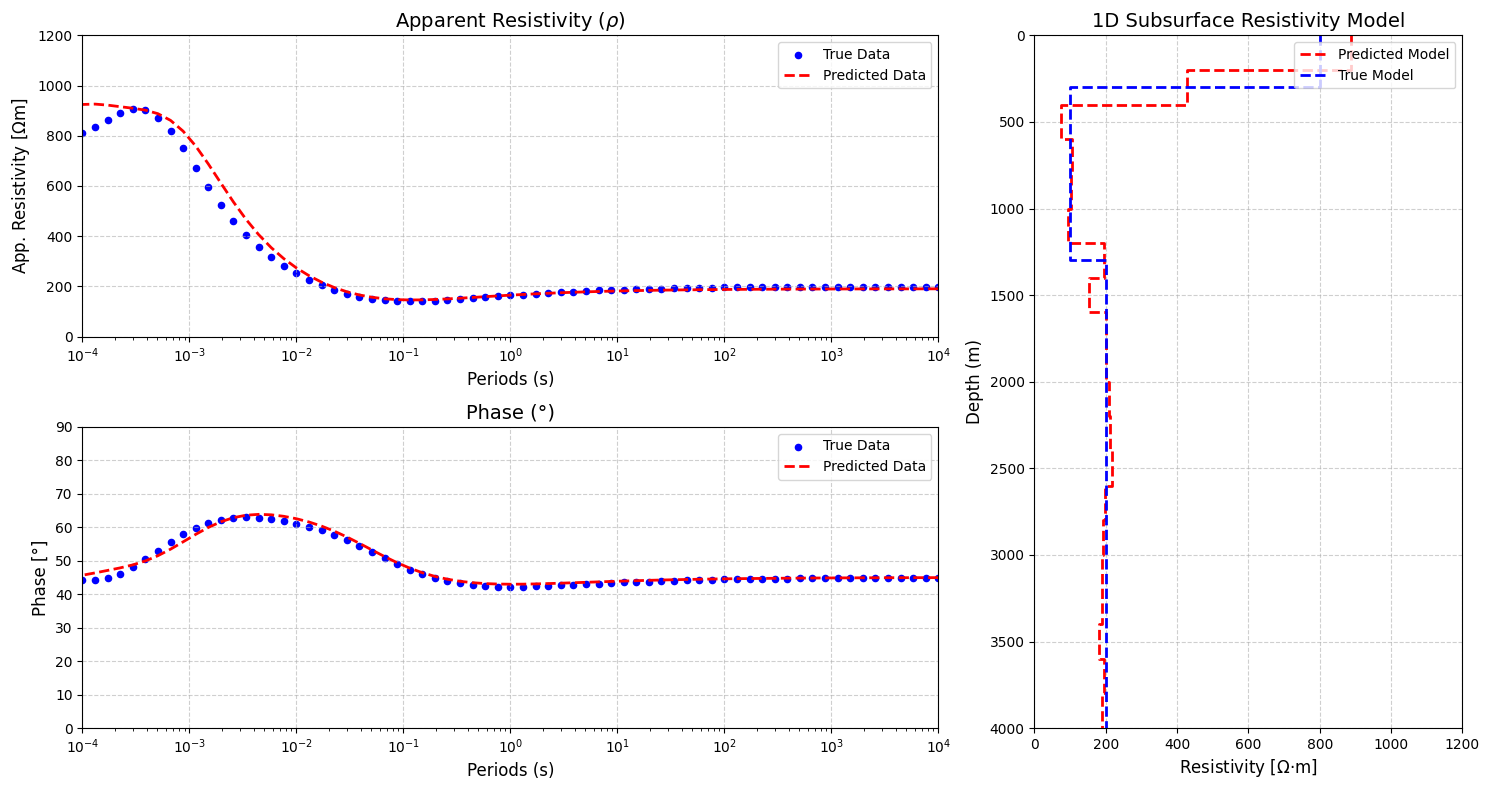

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1063.97
MSE Fasa: 0.82


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.16%
MAPE fasa: 1.33%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 32.62
RMSE Fasa: 0.90


[Interpolated] MSE model resistivitas: 6956.5909
[Interpolated] RMSE model resistivitas: 83.4062
[Interpolated] MAPE model resistivitas: 17.97%


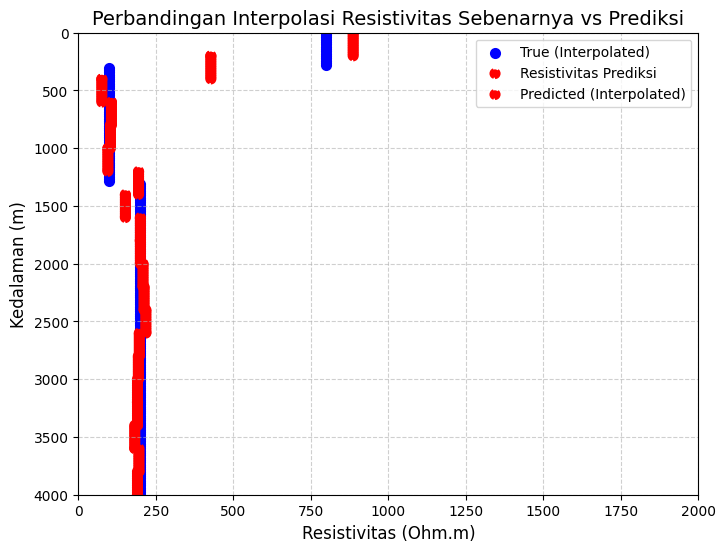

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 3 Lapis VI

### Prediksi

In [ ]:

start = time.time()
# Forward modelling untuk data input
resis_true= np.array([ 800, 200, 50])
ketebalan_true = np.array([300,1000])

period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)
end = time.time()
print(end-start)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [800 200  50]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [831.8936   509.52695  157.89662  225.8076   212.2116   306.49457
  75.93313   55.83834   48.803577  52.125168  51.94714   49.160824
  51.09154   52.537365  54.11079   52.922207  52.27408   51.1538
  52.82217   47.65403 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]
0.10279035568237305


### Grafik

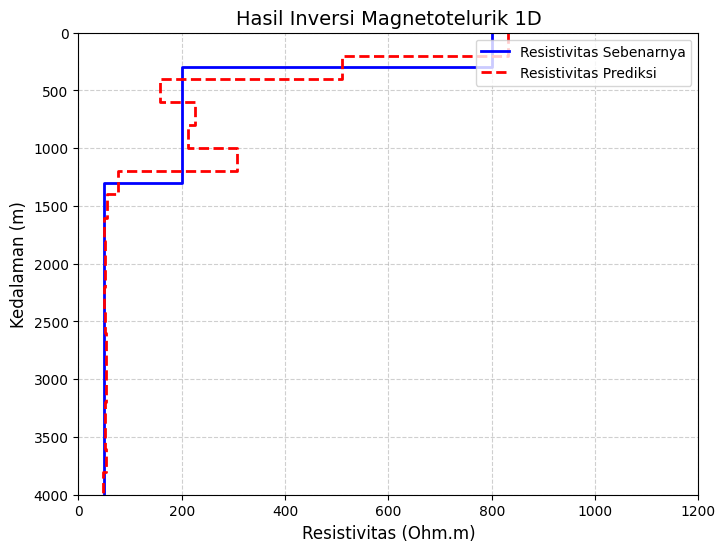

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

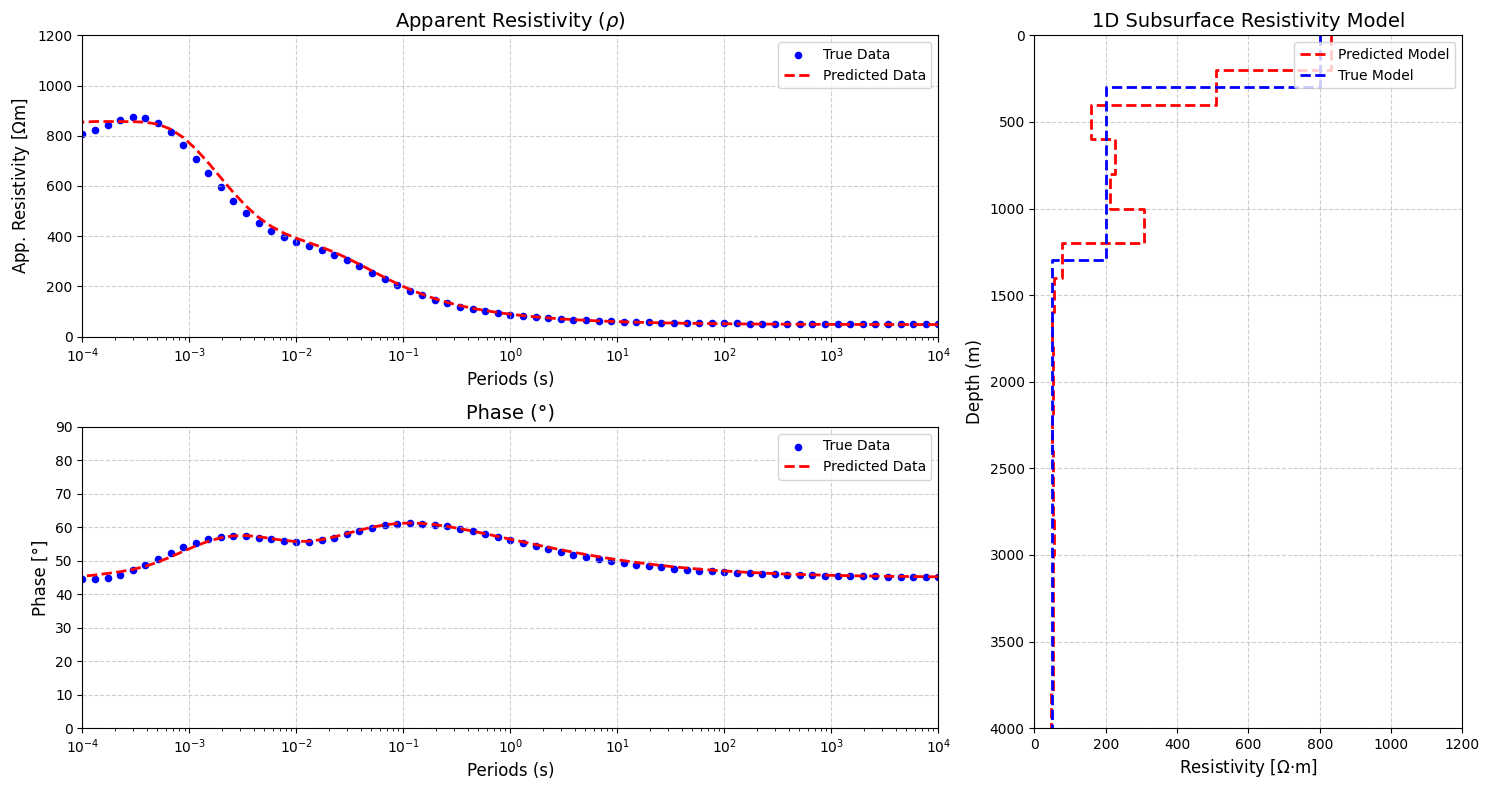

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 204.90
MSE Fasa: 0.26


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.29%
MAPE fasa: 0.75%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 14.31
RMSE Fasa: 0.51


[Interpolated] MSE model resistivitas: 5658.3517
[Interpolated] RMSE model resistivitas: 75.2220
[Interpolated] MAPE model resistivitas: 15.61%


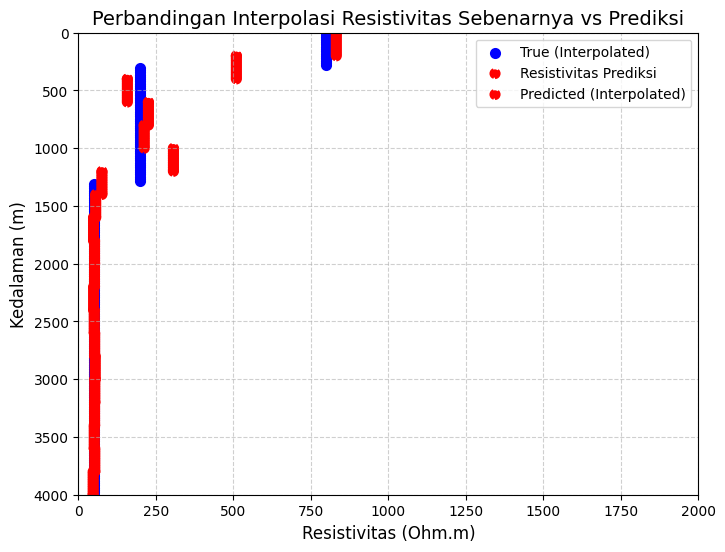

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

# Prediksi Bumi 4 Lapis

## Model Bumi 4 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 50, 200, 800, 1000])
ketebalan_true = np.array([200,500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Nilai Resis_True [  50  200  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 44.744293 198.36142  196.23032  395.83105  870.4064   807.22986
 832.0119   846.71216  887.1798   929.7489   941.2641   959.8892
 971.19214  930.16754  921.7117   898.0647   919.6374   915.4882
 957.0437   983.699   ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

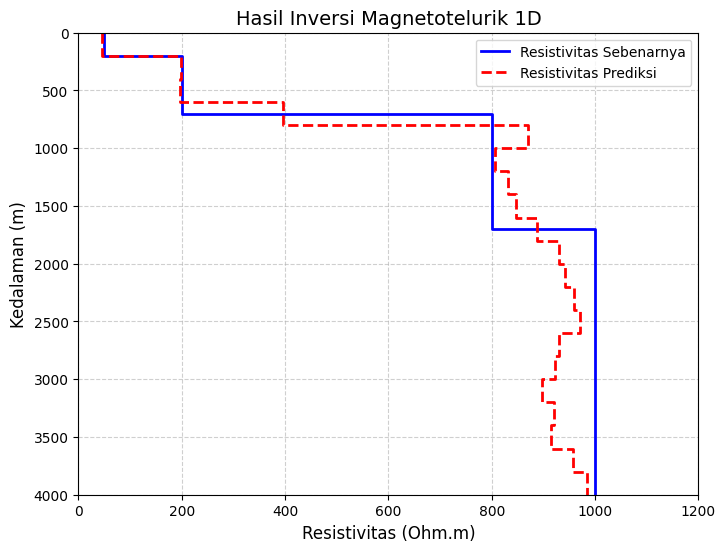

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

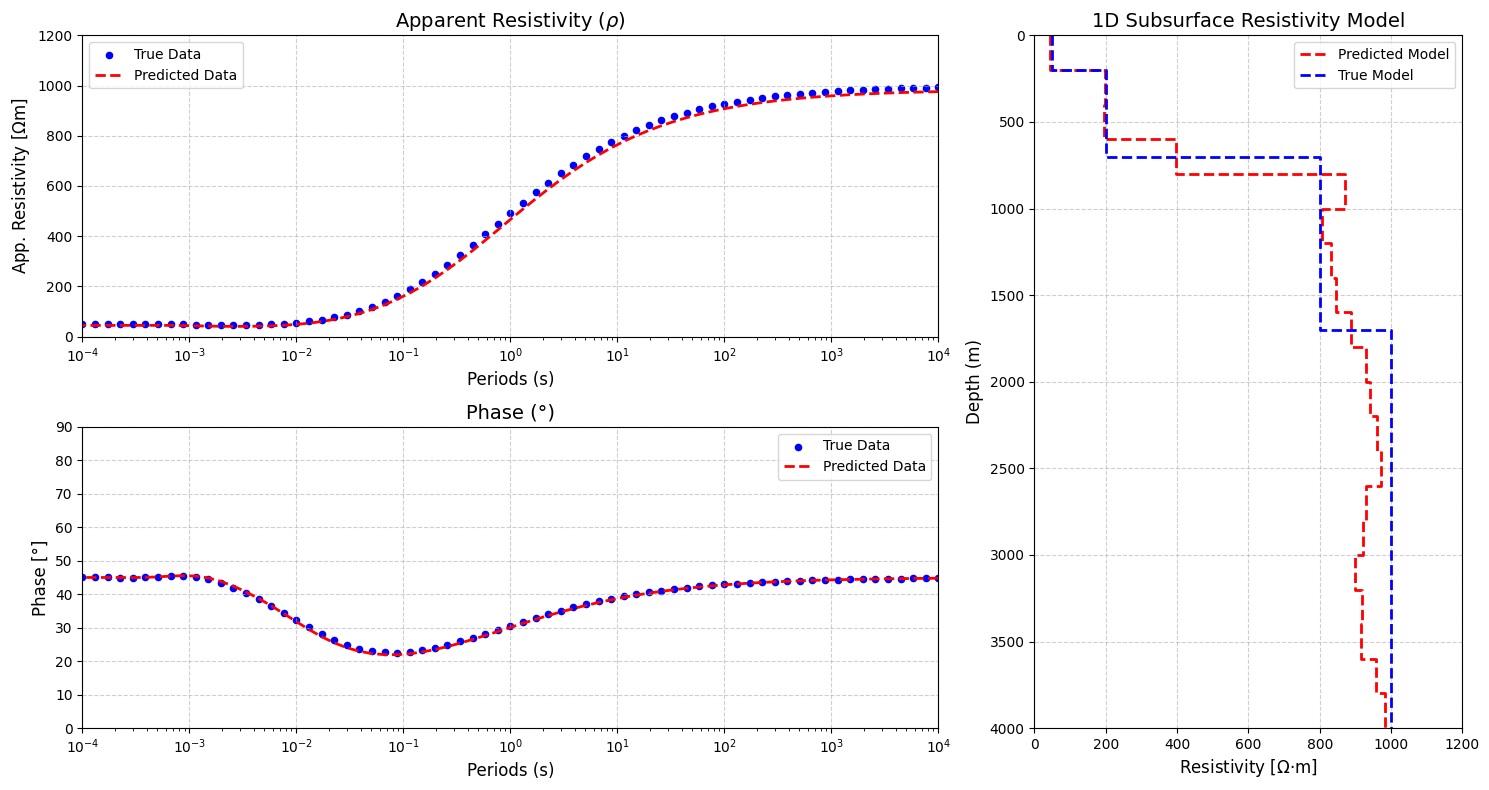

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 281.19
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 6.04%
MAPE fasa: 0.99%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 16.77
RMSE Fasa: 0.40


[Interpolated] MSE model resistivitas: 8360.3924
[Interpolated] RMSE model resistivitas: 91.4352
[Interpolated] MAPE model resistivitas: 9.26%


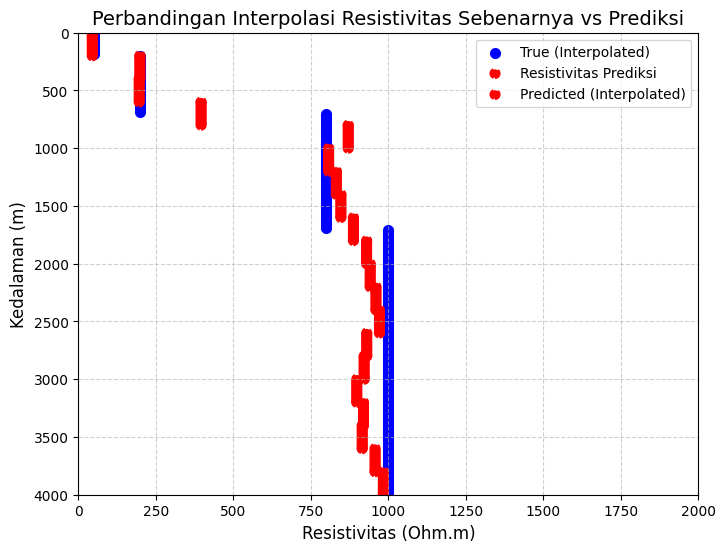

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 800, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Nilai Resis_True [  50  800  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 43.41533 821.61    957.4525  352.79297 175.47751 247.03331 170.24414
 171.8405  744.4217  907.4004  937.465   967.42896 984.75696 953.1458
 917.88916 940.9675  981.10486 970.2676  980.4507  979.4097 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

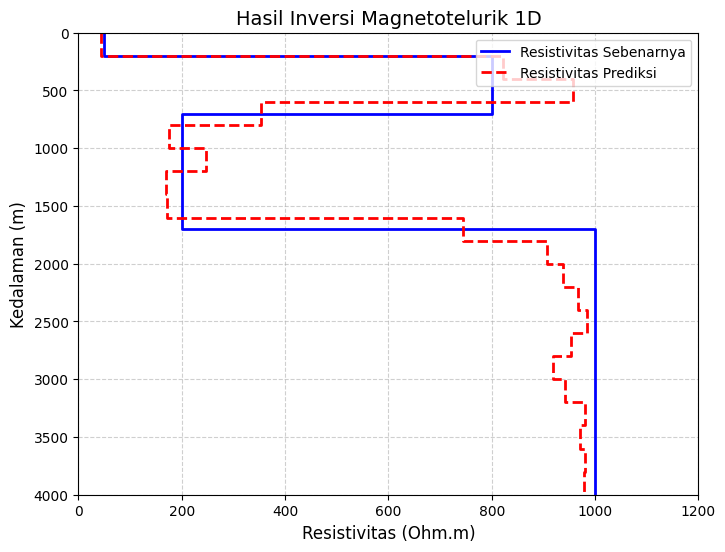

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

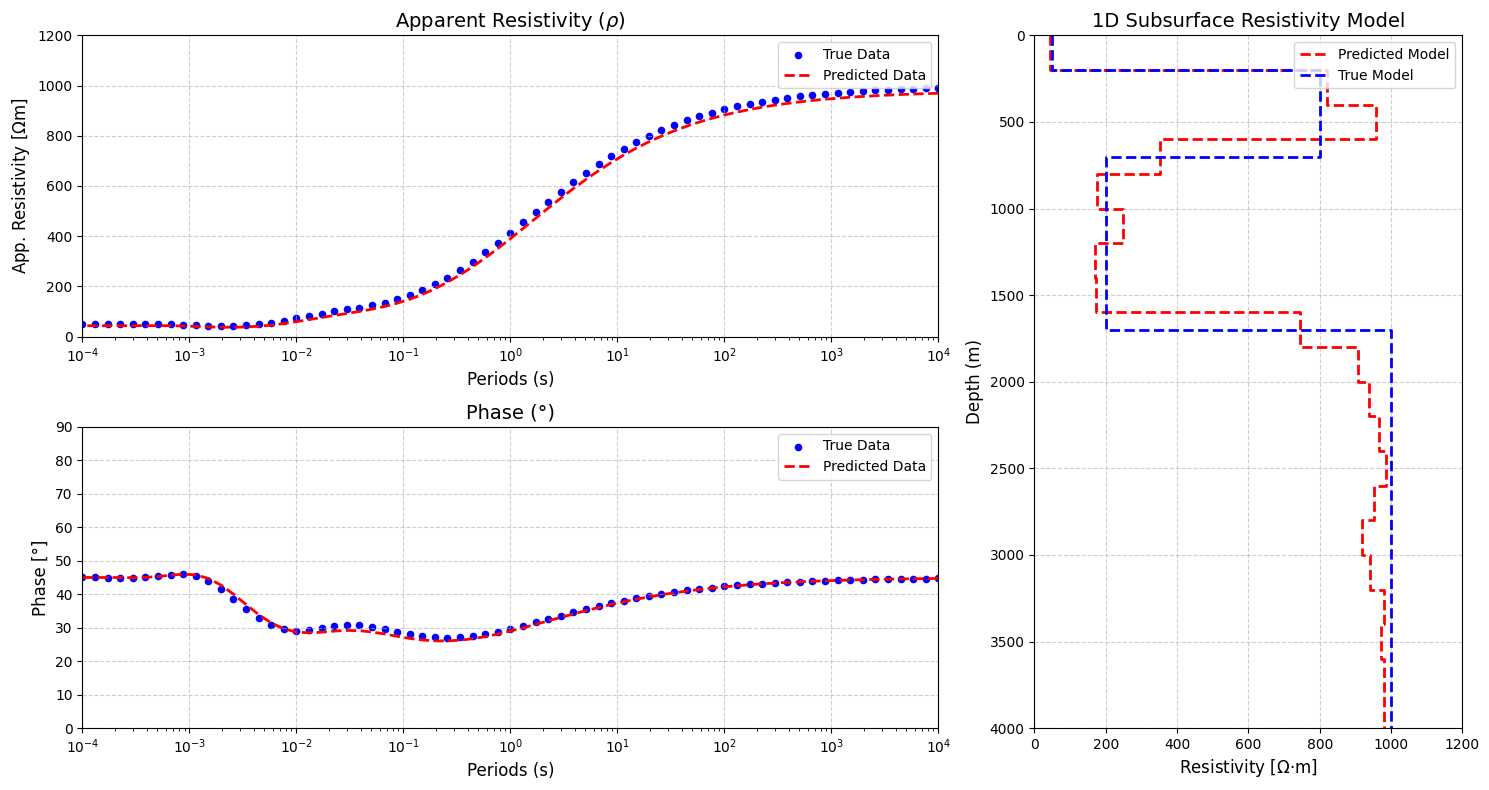

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 362.35
MSE Fasa: 0.49


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.77%
MAPE fasa: 1.53%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 19.04
RMSE Fasa: 0.70


[Interpolated] MSE model resistivitas: 17528.4541
[Interpolated] RMSE model resistivitas: 132.3951
[Interpolated] MAPE model resistivitas: 18.16%


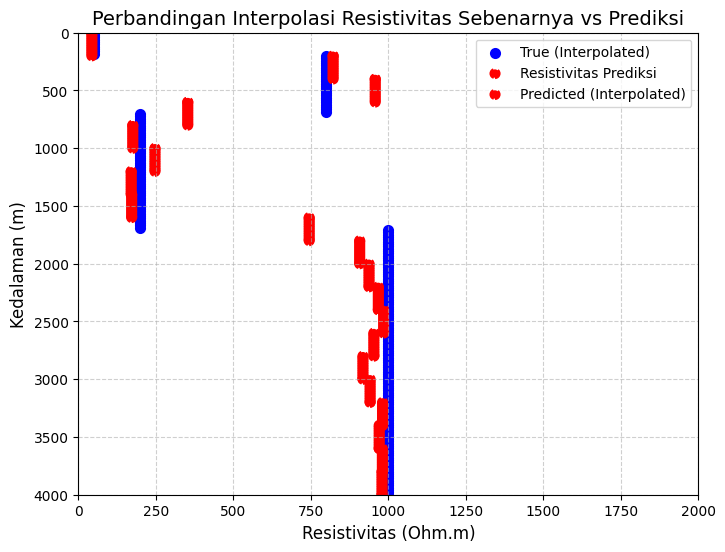

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis III

### Prediksi

In [ ]:

start = time.time()
# Forward modelling untuk data input
resis_true= np.array([50, 1000, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

end = time.time()
print(end - start)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Nilai Resis_True [  50 1000  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [  43.247433  956.5053   1014.5284    439.09268   184.9832    266.148
  165.0658    160.60605   548.98456   784.22064   821.09955   831.13495
  850.72894   807.8359    776.27075   769.2553    787.14374   771.426
  789.6159    830.07434 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]
0.10004472732543945


### Grafik

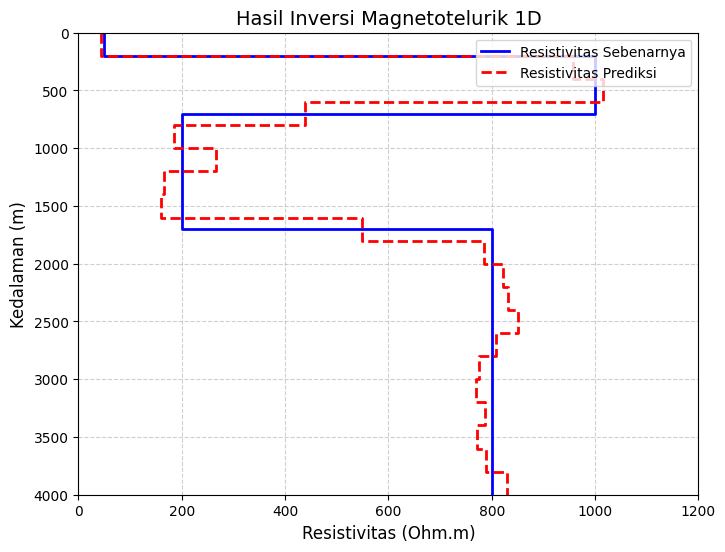

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

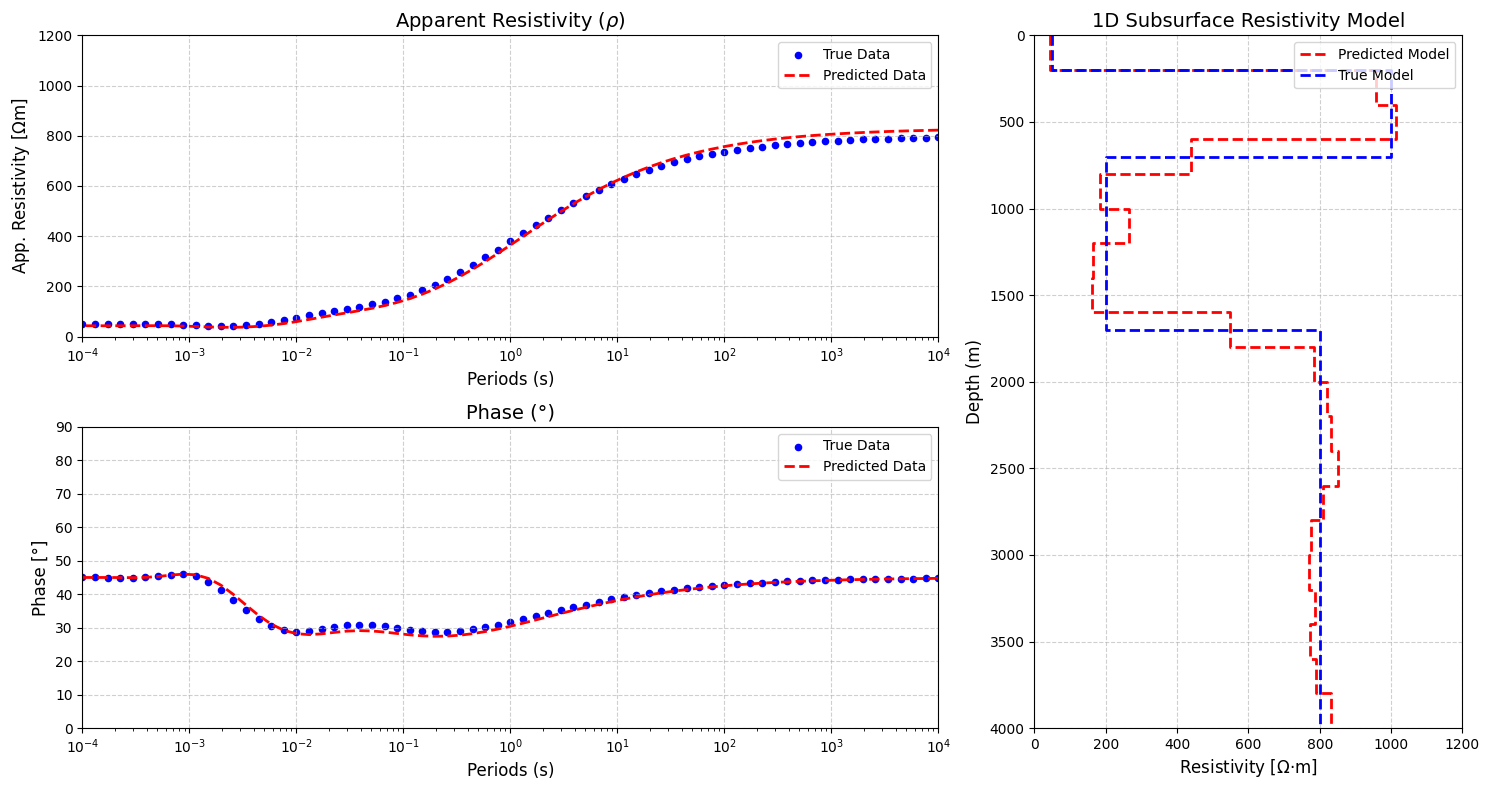

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 290.78
MSE Fasa: 0.79


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 7.64%
MAPE fasa: 2.01%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 17.05
RMSE Fasa: 0.89


[Interpolated] MSE model resistivitas: 14780.6606
[Interpolated] RMSE model resistivitas: 121.5757
[Interpolated] MAPE model resistivitas: 16.03%


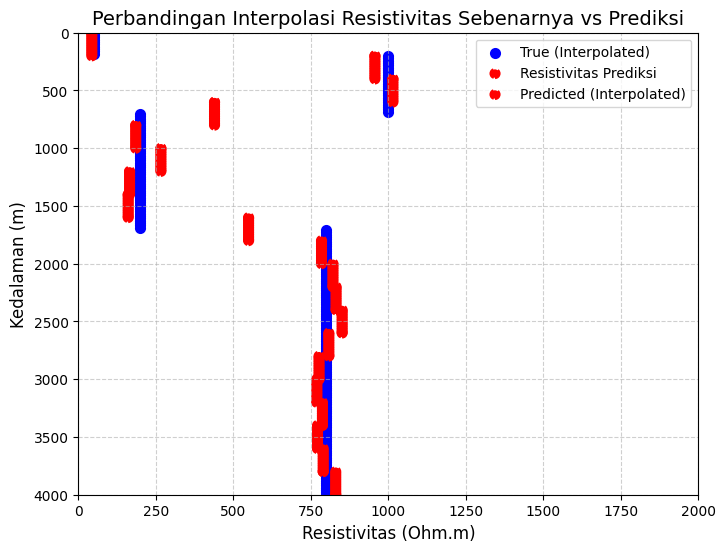

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 200, 50, 800, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Nilai Resis_True [ 200   50  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 193.12123    51.04982    51.920753   98.557846  966.8502    921.0753
  896.1145    898.7917    884.00604   936.3247    946.18695   971.7383
 1009.06055   978.1642    965.8131    975.32764  1002.14825  1008.3827
  976.4924    972.29645 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

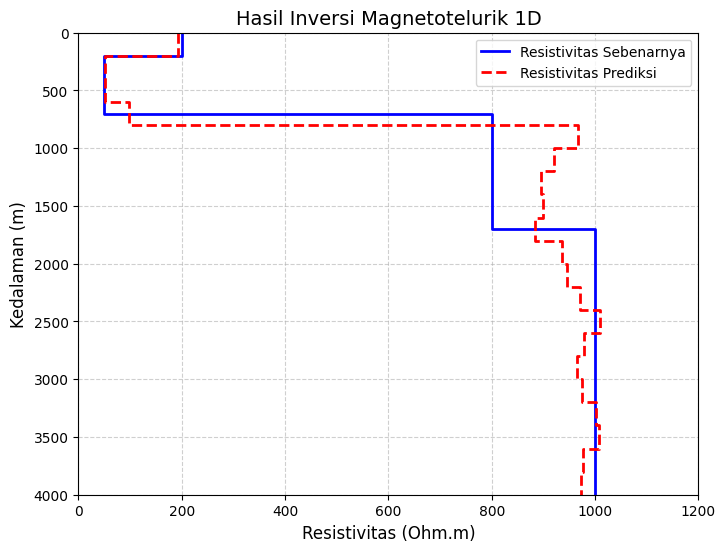

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

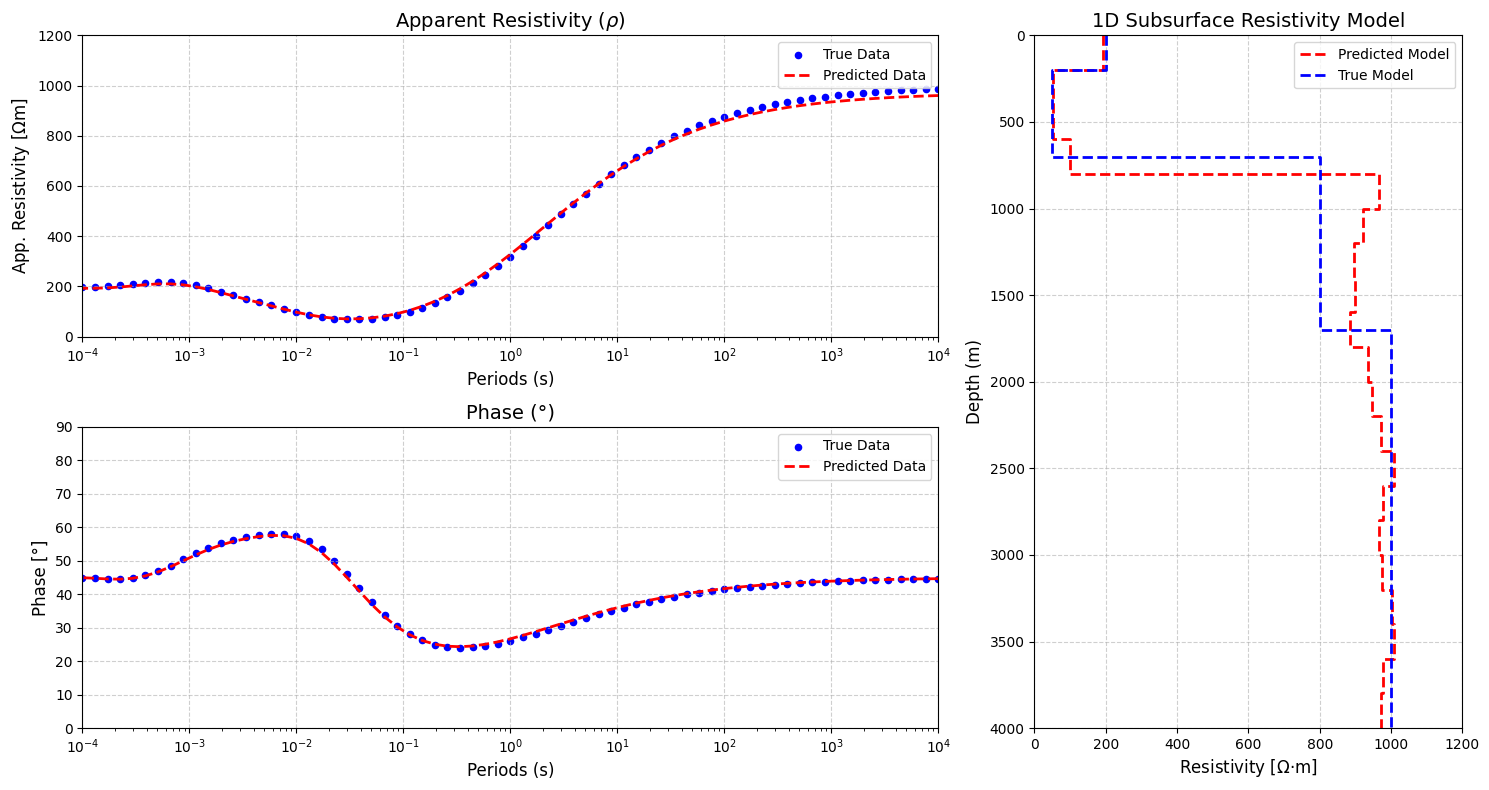

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 181.94
MSE Fasa: 0.20


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.51%
MAPE fasa: 0.91%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 13.49
RMSE Fasa: 0.44


[Interpolated] MSE model resistivitas: 16523.6938
[Interpolated] RMSE model resistivitas: 128.5445
[Interpolated] MAPE model resistivitas: 10.15%


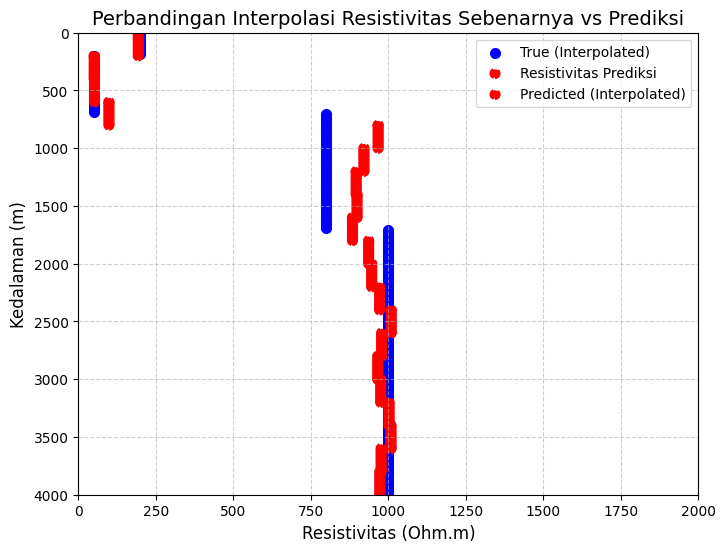

In [ ]:





measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 800, 50, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Nilai Resis_True [ 800   50  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [797.11847   55.632572  47.055668  58.258545 404.20724  221.79929
 191.54588  238.15459  515.8452   716.1151   893.9942   914.9898
 979.15436  955.8654   968.8932   943.6948   963.62476  955.1452
 946.32825  964.936   ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

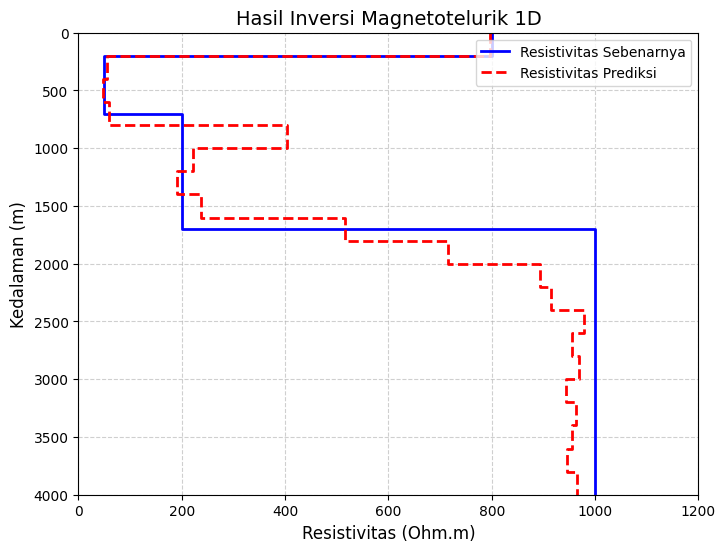

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

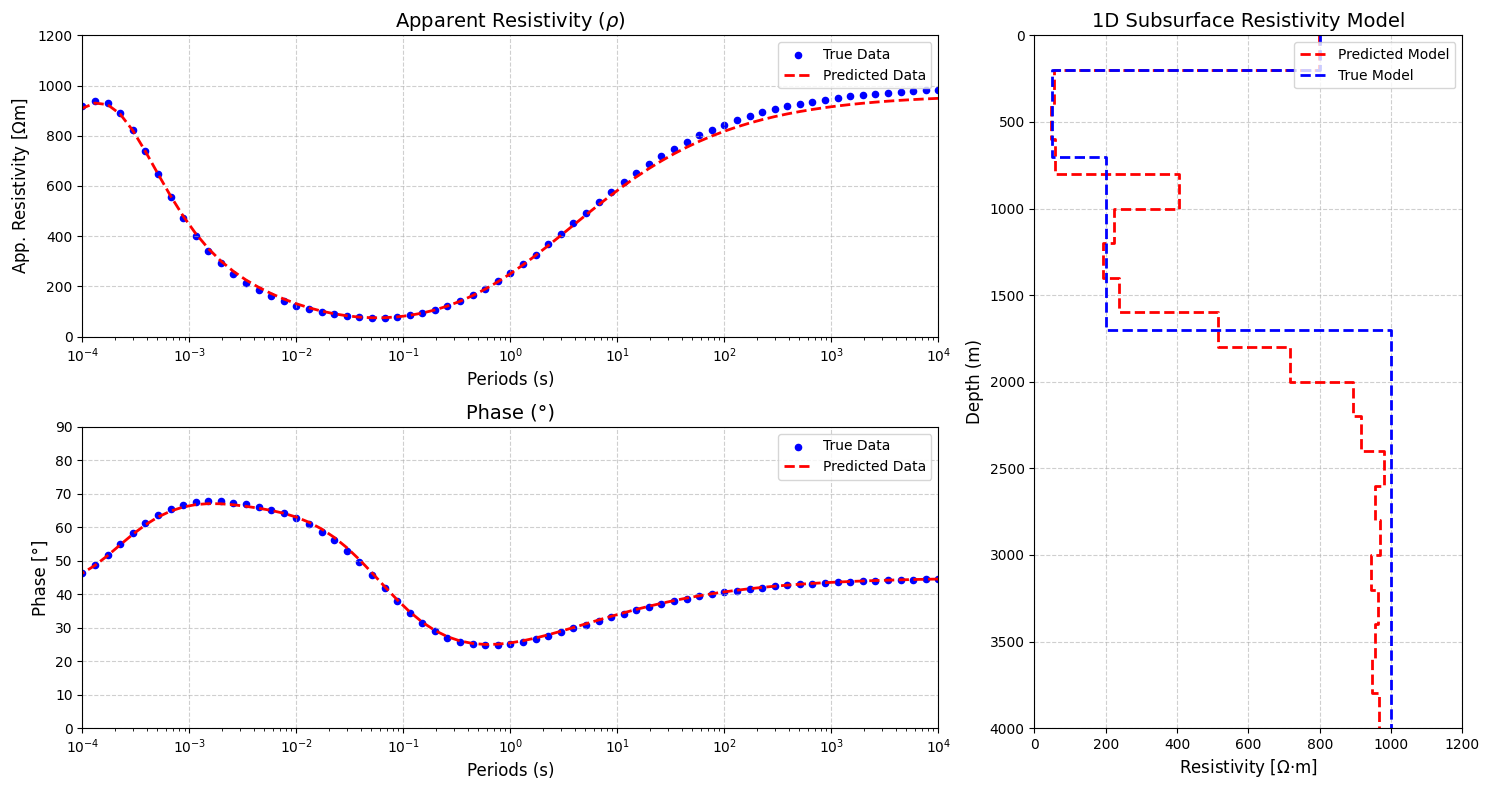

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 328.23
MSE Fasa: 0.16


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.34%
MAPE fasa: 0.67%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 18.12
RMSE Fasa: 0.39


[Interpolated] MSE model resistivitas: 16696.6677
[Interpolated] RMSE model resistivitas: 129.2156
[Interpolated] MAPE model resistivitas: 19.02%


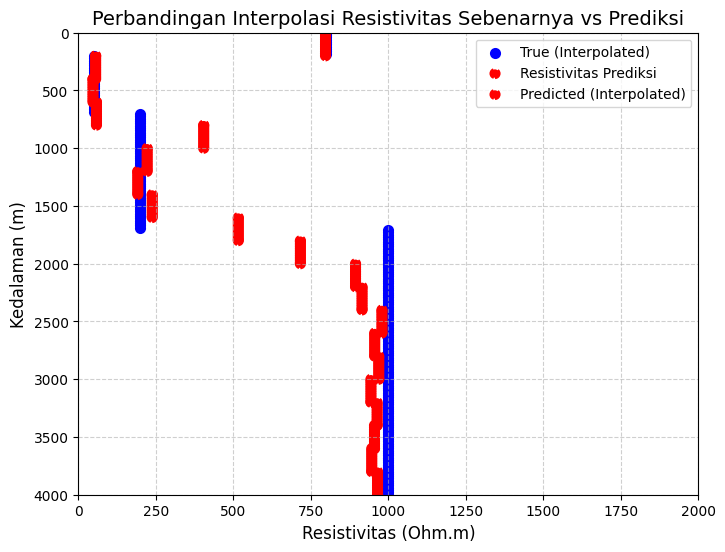

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

## Model Bumi 4 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([1000, 50, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Logaritma Data Input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Nilai Resis_True [1000   50  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [904.0739    52.81837   51.673122  76.064926 315.2988   257.11456
 203.46225  236.20657  401.5999   641.2858   742.6726   792.0815
 875.5948   891.667    819.334    817.35187  852.6071   824.98663
 792.00757  781.3569  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

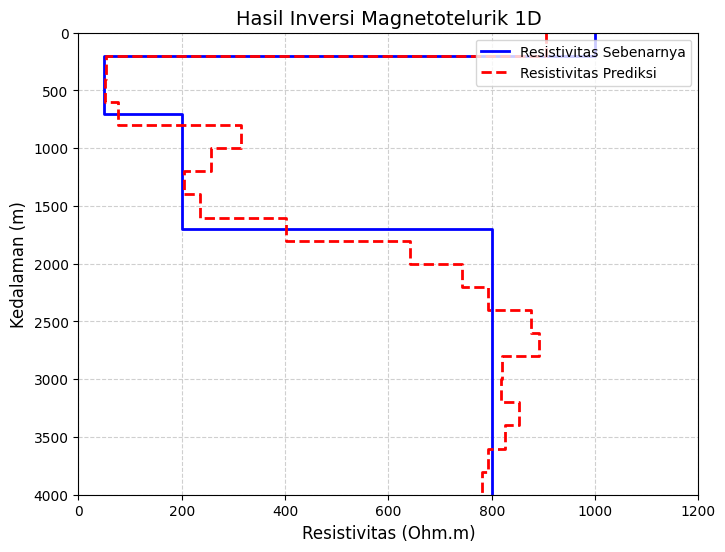

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

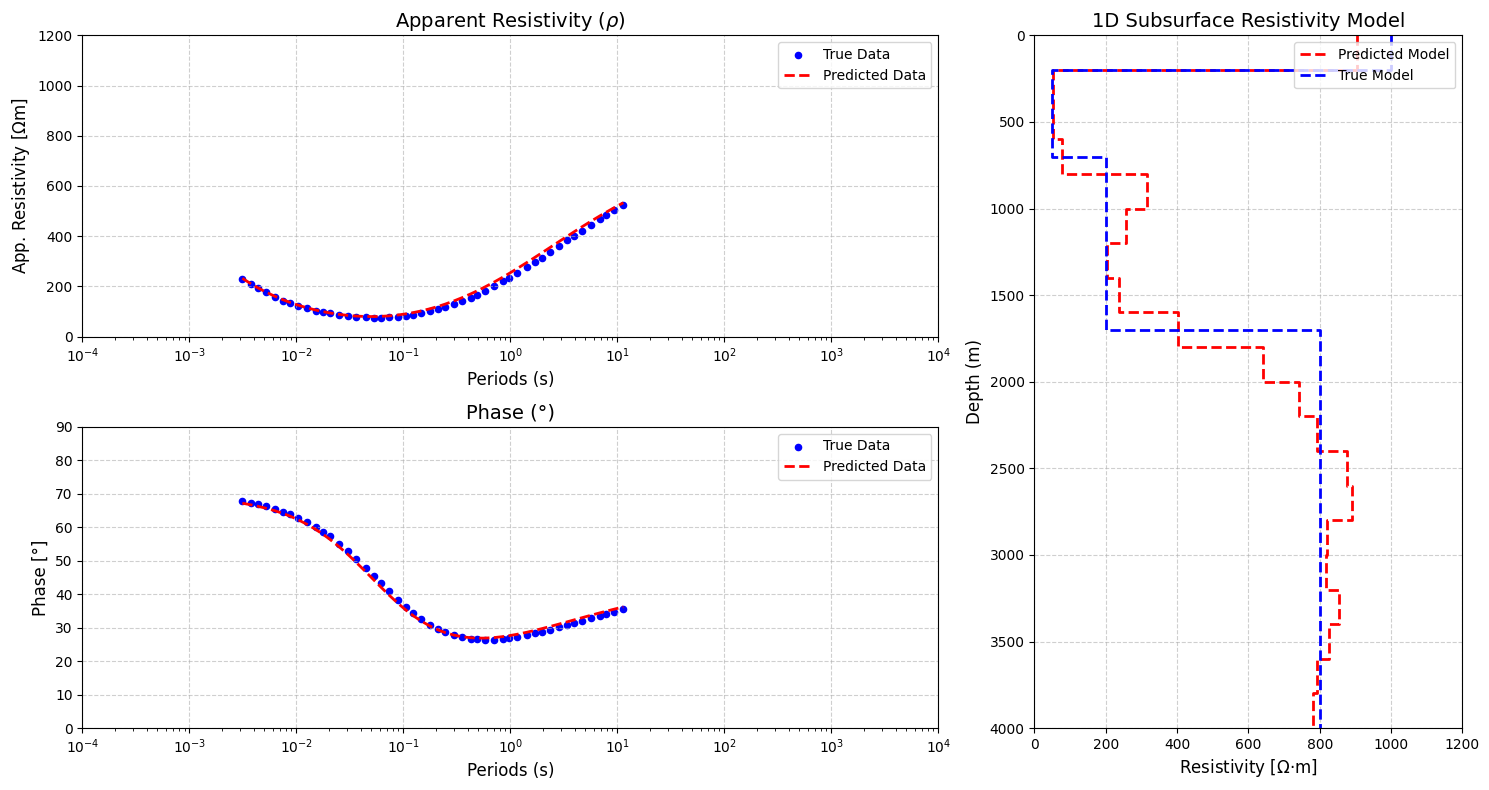

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 225.74
MSE Fasa: 0.30


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.01%
MAPE fasa: 0.71%


In [ ]:
measure_RMSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

RMSE Resistivitas Semu: 15.02
RMSE Fasa: 0.55


[Interpolated] MSE model resistivitas: 12021.1791
[Interpolated] RMSE model resistivitas: 109.6411
[Interpolated] MAPE model resistivitas: 18.25%


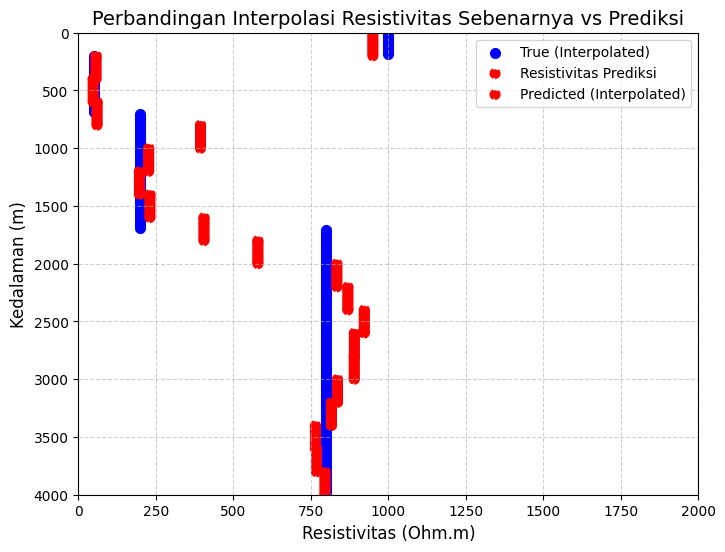

In [ ]:
measure_interpolated_resistivities(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

#Uji Coba Data Lapangan

##Aceh01

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/Frequency_Aceh01.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/RhoXY_Aceh01.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/RhoYX_Aceh01.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/PHSXY_Aceh01.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 01/PHSYX_Aceh01.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()

In [ ]:
#Penyesuaian

phaseYX = phaseYX+180

In [ ]:
frequency.shape, RHOXY.shape, RHOYX.shape, phaseXY.shape, phaseYX.shape

((48,), (48,), (48,), (48,), (48,))

In [ ]:

def hitung_rho_phi_avg(rhoxy, phixy_deg, rhoyx, phiyx_deg):
    # Ubah derajat ke radian (np.deg2rad juga bisa digunakan)
    phixy = np.radians(phixy_deg)
    phiyx = np.radians(phiyx_deg)

    # Hitung rho_avg (sesuai persamaan 3a)
    rho_avg = 0.25 * (rhoxy + rhoyx + 2 * np.sqrt(rhoxy * rhoyx) * np.cos(phixy - phiyx))

    # Hitung phi_avg (sesuai persamaan 3b)
    sqrt_rhoxy = np.sqrt(rhoxy)
    sqrt_rhoyx = np.sqrt(rhoyx)

    num = sqrt_rhoxy * np.sin(phixy) + sqrt_rhoyx * np.sin(phiyx)
    den = sqrt_rhoxy * np.cos(phixy) + sqrt_rhoyx * np.cos(phiyx)

    phi_avg = np.degrees(np.arctan2(num, den))  # np.arctan2 lebih baik untuk array

    return rho_avg, phi_avg

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Nilai resis_predict [  38.018974  502.48267    60.462708 1047.3469   1146.8066   1076.4689
 1076.8035   1107.3315   1022.559    1044.4657    984.31696  1019.7286
 1025.0635    954.87415   901.4809    823.757     675.8506    451.3276
  267.77094   984.9862  ]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


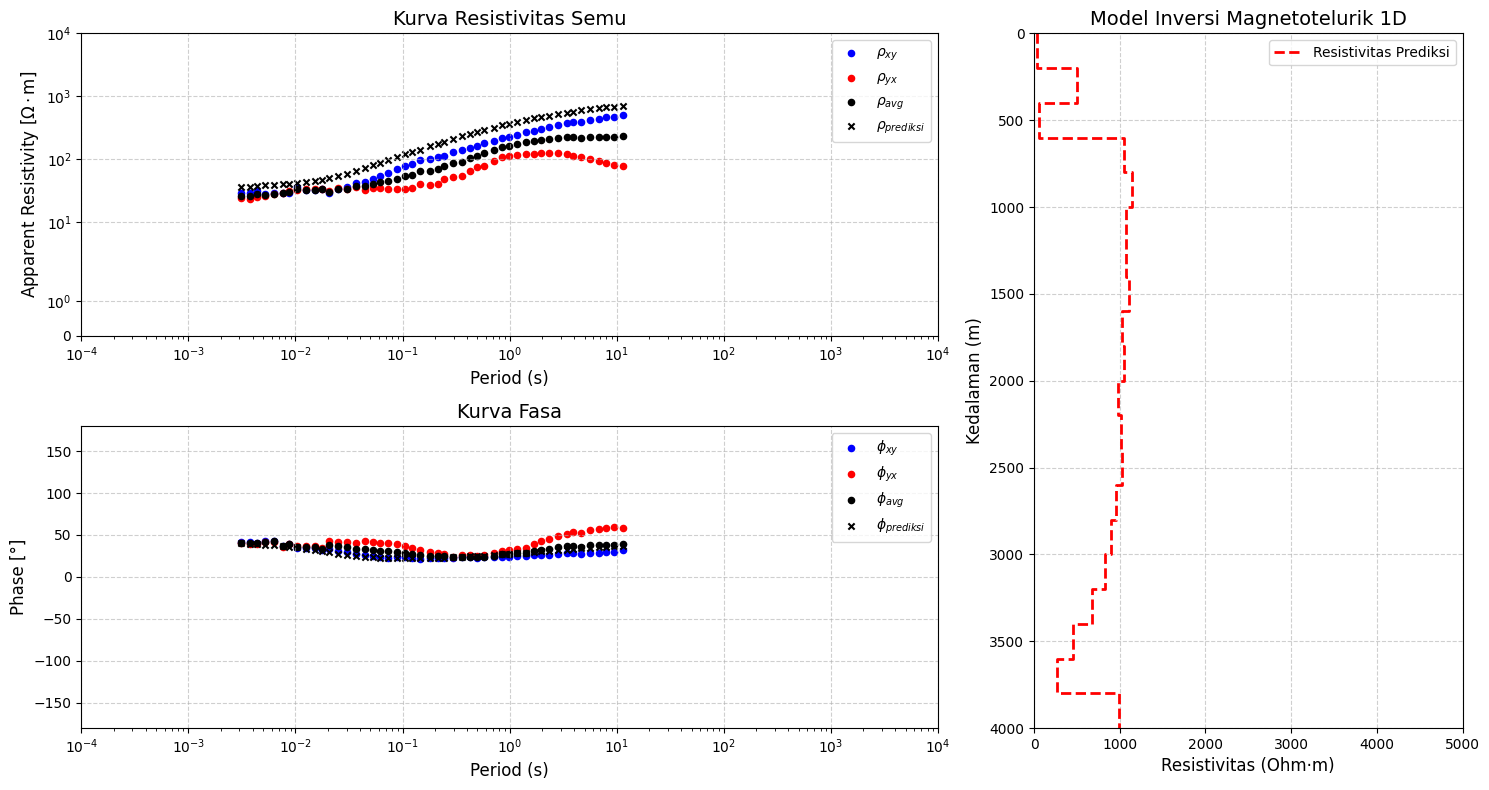

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh02

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/Frequency_Aceh02.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/RhoXY_Aceh02.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/RhoYX_Aceh02.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/PHSXY_Aceh02.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 02/PHSYX_Aceh02.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten() + 180

In [ ]:
RHOXY

array([358.7928, 404.3849, 437.671 , 507.3221, 580.2902, 659.3657,
       739.0038, 796.277 , 855.3944, 870.6155, 817.1707, 756.0457,
       792.7101, 704.7623, 712.6429, 642.299 , 625.1277, 587.3258,
       556.2343, 516.6679, 461.0262, 440.4007, 424.5789, 369.0516,
       331.2805, 318.9276, 319.1875, 313.5716, 317.3317, 325.7021,
       337.5253, 351.2324, 359.8749, 376.0805, 391.2031, 422.1734,
       445.4818, 472.1243, 514.9379, 554.8674, 587.2429, 608.2999,
       592.8276, 643.6456, 717.3214, 712.2511, 734.5885, 831.3029])

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Nilai resis_predict [ 123.199   1986.4127  1913.6289  2292.1074  2300.0916  2279.7915
 1559.7977  1146.0803   811.8718   316.99844  437.96094 1164.5242
  826.23395  890.556    978.99744 1066.7428  1230.4833   238.46216
  162.55655 1272.3096 ]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


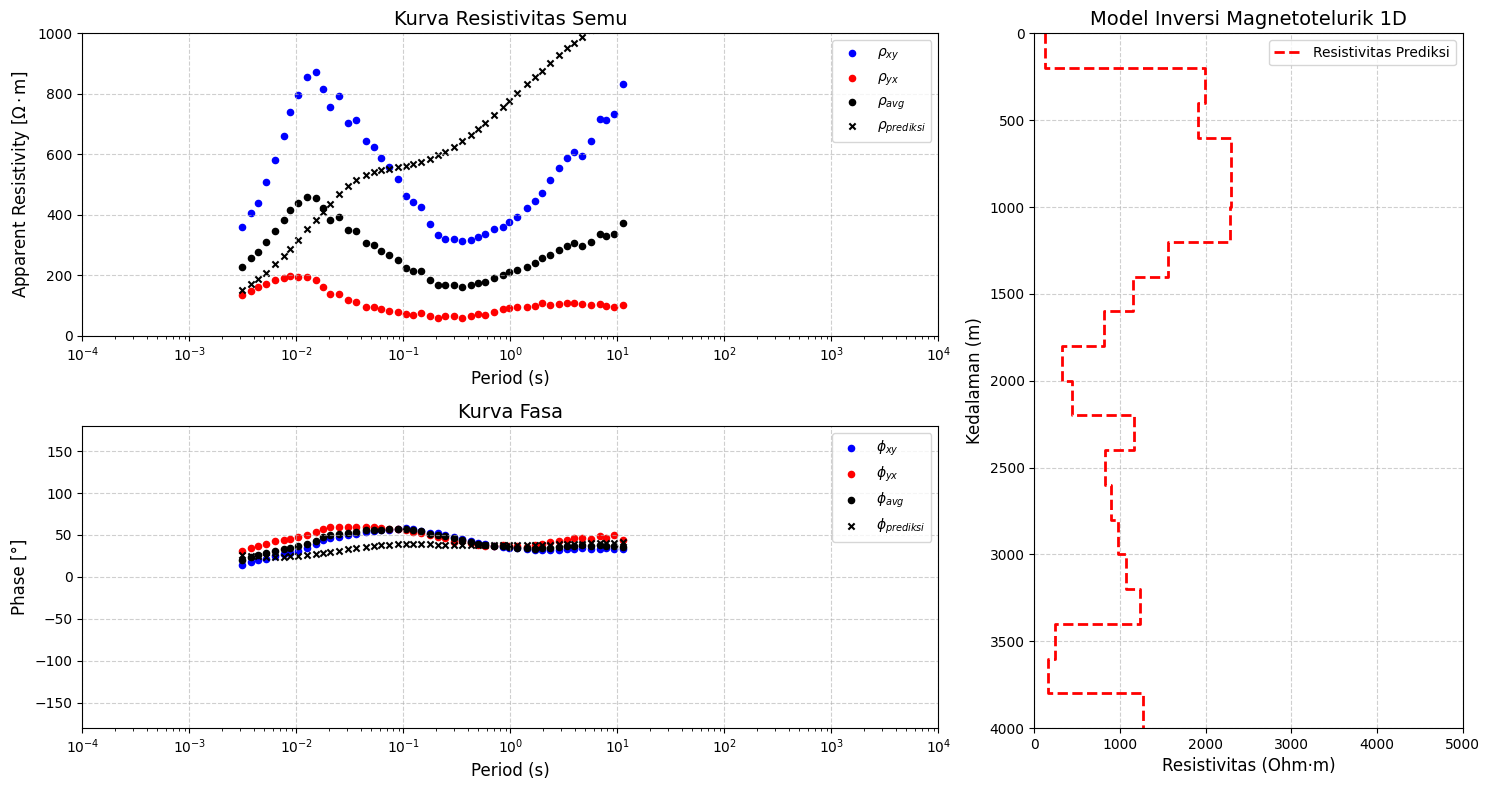

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_ylim([0, 1000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh04

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/Frequency_Aceh04.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/RhoXY_Aceh04.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/RhoYX_Aceh04.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/PHSXY_Aceh04.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 04/PHSYX_Aceh04.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Nilai resis_predict [ 175.42212 1477.9447  1072.3578   386.86227  346.463    764.7579
 1038.3279  1188.1703  1099.5125  1064.8284   913.617    904.6573
  789.98615  753.46326  728.0471   773.76434  824.9409   886.1503
  975.56915 1747.1582 ]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


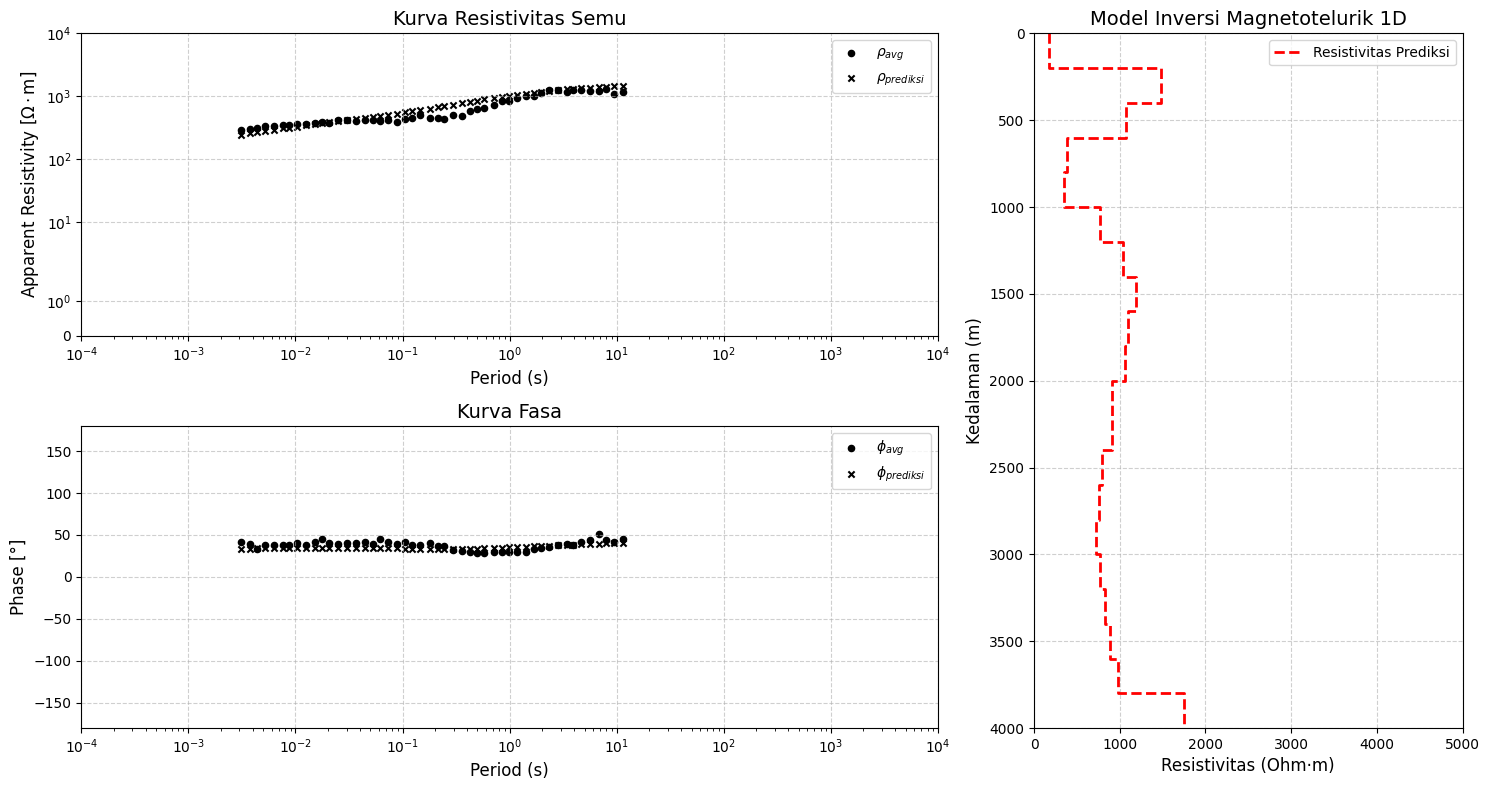

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
# ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
# ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
# ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
# ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh 05

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/Frequency_Aceh05.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/RhoXY_Aceh05.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/RhoYX_Aceh05.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/PHSXY_Aceh05.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 05/PHSYX_Aceh05.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Nilai resis_predict [  49.66078   112.54181    14.601713  582.78284   344.9688    218.31721
  195.21645   559.5403    860.13666   901.6853   1021.1078   1085.8907
 1063.1188   1123.8844   1105.17     1038.5383   1161.4456   1084.5223
 1018.98267    82.16413 ]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


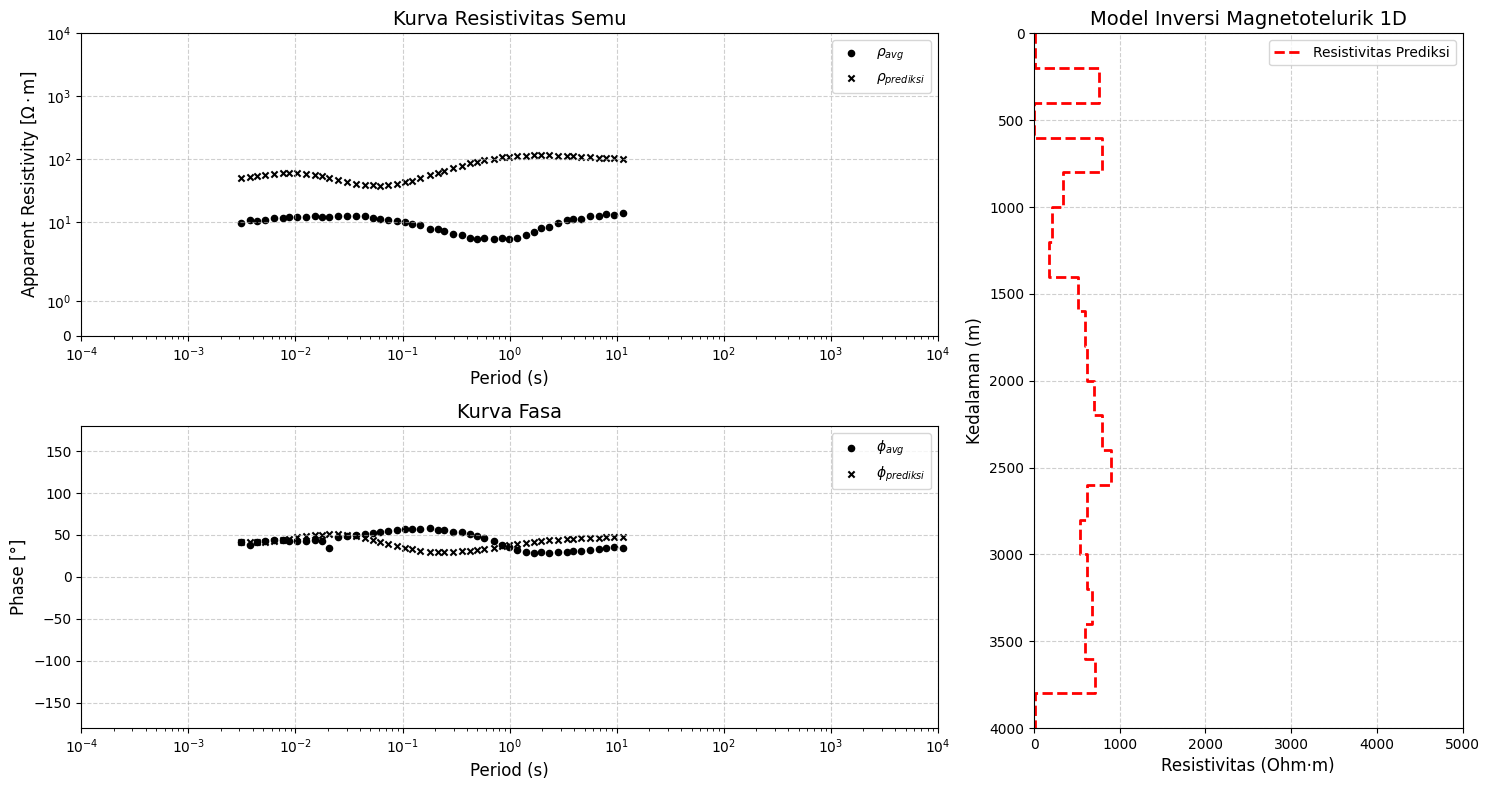

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
# ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
# ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
# ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
# ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


##Aceh 06

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/Frequency_Aceh06.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/RhoXY_Aceh06.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/RhoYX_Aceh06.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/PHSXY_Aceh06.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 06/PHSYX_Aceh06.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Nilai resis_predict [  9.129381 751.96405    3.374579 796.1052   332.9664   211.66173
 170.8216   511.99893  598.94885  620.95593  701.3555   789.58124
 898.9412   617.4814   534.2709   619.4224   678.607    590.6648
 713.0114     4.981201]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


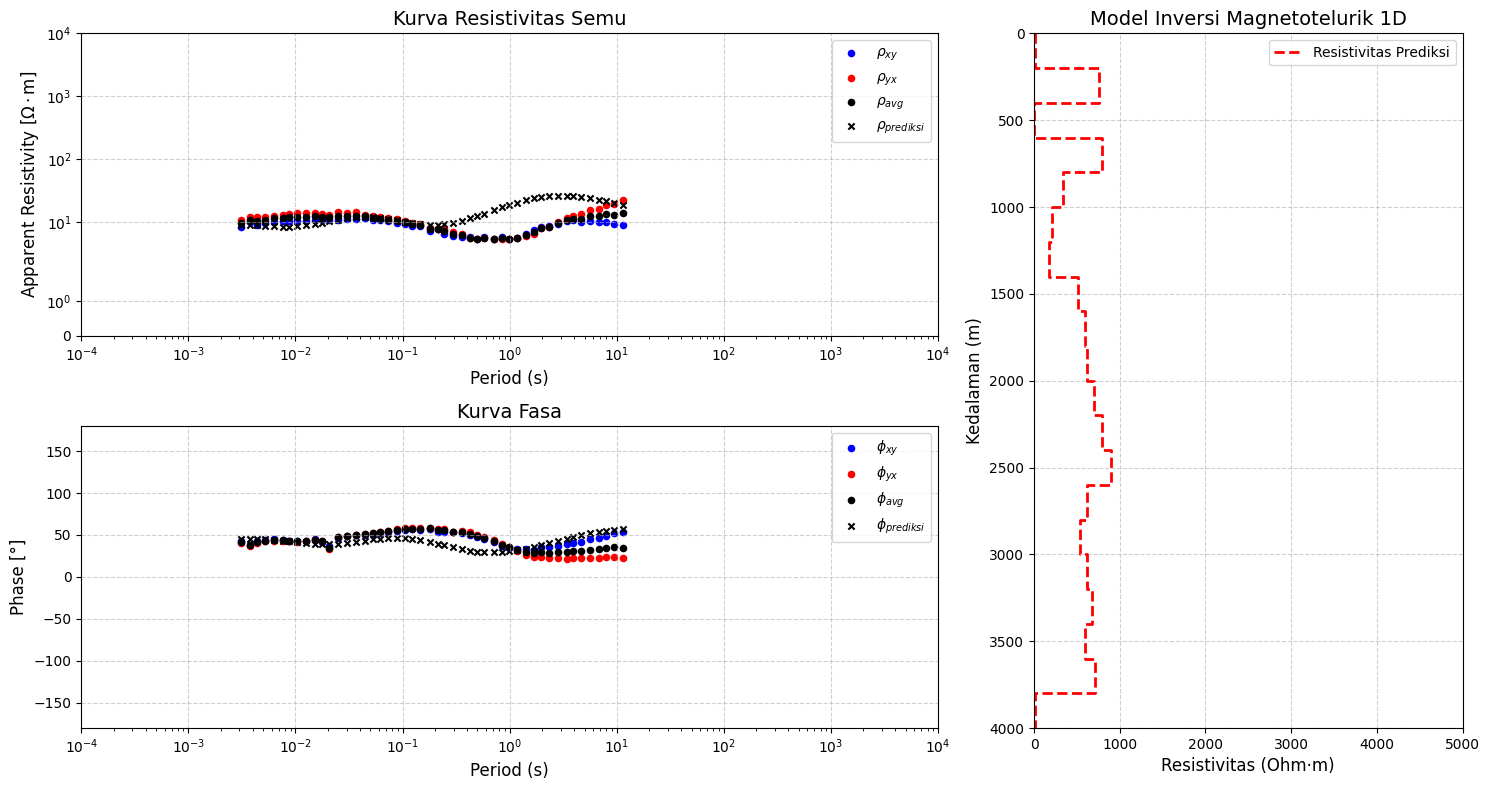

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


## Aceh 07

In [ ]:
frequency = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/Frequency_Aceh07.txt")
RHOXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/RhoXY_Aceh07.txt")
RHOYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/RhoYX_Aceh07.txt")
phaseXY = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/PHSXY_Aceh07.txt")
phaseYX = np.loadtxt("/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 07/PHSYX_Aceh07.txt")

In [ ]:
frequency = frequency.flatten()
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
period = 1/frequency

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,tebal_per_lapisan)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Nilai resis_predict [   5.146419  1332.9088       7.6203136  161.20053   1585.997
  722.3001     229.59688    328.12323    255.90971    531.1365
  964.3413     774.4141    1127.3678     739.52765    706.4862
  868.81525    911.0441     676.9367     631.76624     14.672855 ]
Nilai ketebalan_predict [200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200 200
 200]


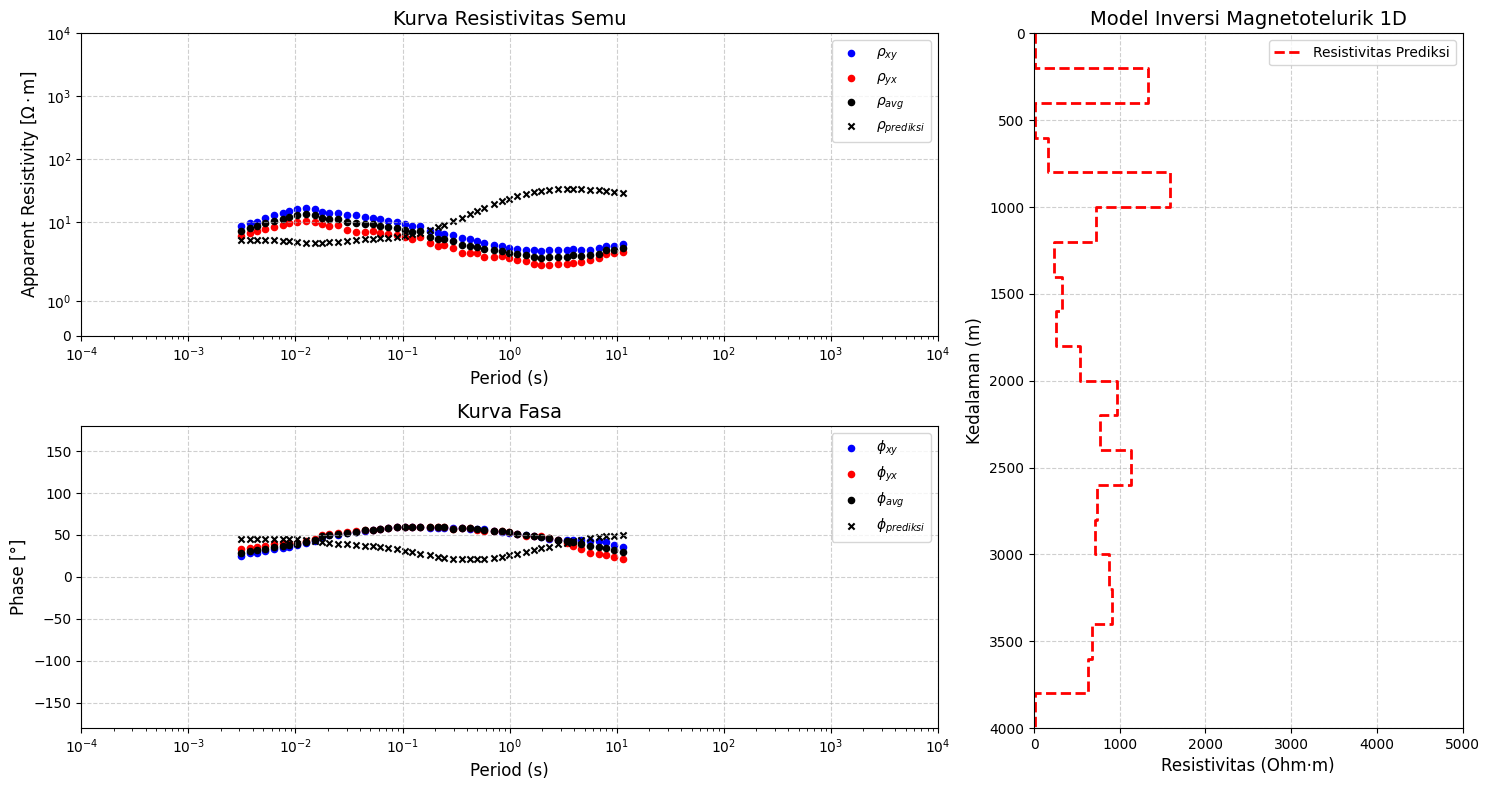

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


## Aceh 08

In [ ]:
def load_txt_cleaned(filepath):
    with open(filepath, "r") as f:
        lines = f.readlines()

    values = []
    for line in lines:
        for val in line.strip().split():
            try:
                values.append(float(val))
            except ValueError:
                pass  # Abaikan jika ada karakter non-numerik

    return np.array(values)


In [ ]:
# Path dasar folder
base = "/content/drive/MyDrive/Tugas Akhir/Data Lapangan/Aceh 08/"

# Baca dengan fungsi pembersih
frequency = load_txt_cleaned(base + "Frequency_Aceh08.txt")
RHOXY    = load_txt_cleaned(base + "RhoXY_Aceh08.txt")
RHOYX    = load_txt_cleaned(base + "RhoYX_Aceh08.txt")
phaseXY  = load_txt_cleaned(base + "PHSXY_Aceh08.txt")
phaseYX  = load_txt_cleaned(base + "PHSYX_Aceh08.txt")


In [ ]:
frequency = np.delete(frequency, -1)
RHOXY = np.delete(RHOXY, -1)
RHOYX = np.delete(RHOYX, -1)
phaseXY = np.delete(phaseXY, -1)
phaseYX = np.delete(phaseYX, -1)


In [ ]:
print("Jumlah data:", len(frequency), len(RHOXY), len(RHOYX), len(phaseXY), len(phaseYX))
print("Contoh data:", RHOXY[:5])


Jumlah data: 48 48 48 48 48
Contoh data: [3.971553 3.971553 3.805728 3.887897 3.946853]


In [ ]:
RHOXY = RHOXY.flatten()
RHOYX = RHOYX.flatten()
phaseXY = phaseXY.flatten()
phaseYX = phaseYX.flatten()+180

In [ ]:
rho_avg, phi_avg = hitung_rho_phi_avg(RHOXY, phaseXY, RHOYX, phaseYX)
#

In [ ]:


resistivitas_semu = np.array([RHOXY])
fasa = np.array([phaseXY])

#Reshape sebelum Logaritma
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritma data input
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Delogaritmik hasil prediksi
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Nilai resis_predict [   6.661608   40.273552   16.201756   68.30168    64.67569   928.29486
  834.4138   1300.8281    856.0656    786.7501    476.77817   447.1474
 1044.2301    985.5406    935.3075    895.1459   1020.5289   1036.2654
 1204.3186   1226.7904  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


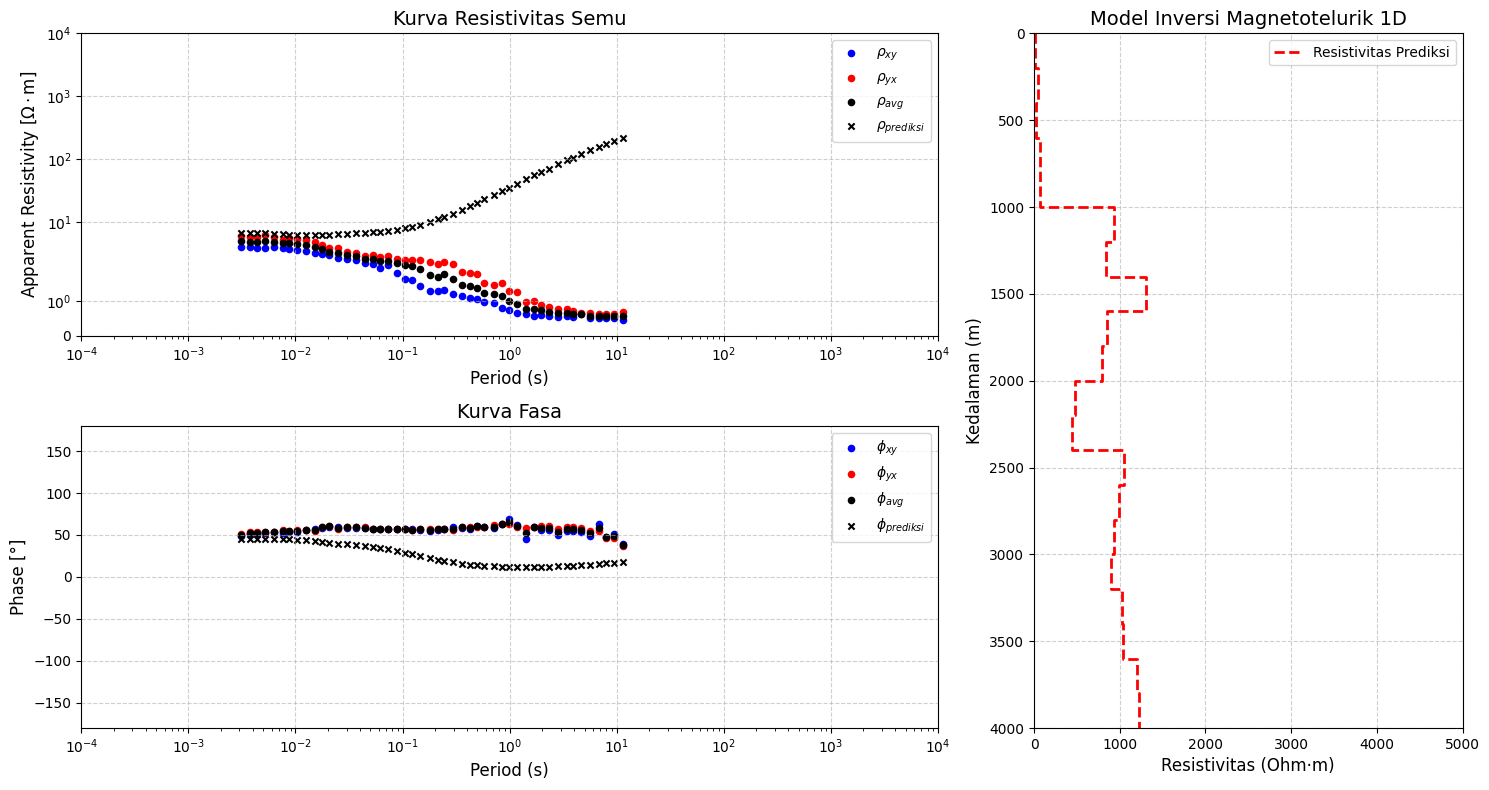

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)
  return depth_plot, resis_plot

depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Buat figure dan GridSpec
fig = plt.figure(figsize=(15, 8))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

# Subplot 1: Resistivitas Semu
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(1/frequency, RHOXY, color='blue', label=r'$\rho_{xy}$', s=20)
ax1.scatter(1/frequency, RHOYX, color='red', label=r'$\rho_{yx}$', s=20)
ax1.scatter(1/frequency, rho_avg, color='black', label=r'$\rho_{avg}$', s=20)
ax1.scatter(1/frequency, resistivitas_semu_predict[0], color='black',marker ='x', label=r'$\rho_{prediksi}$', s=20)
ax1.set_ylabel(r'Apparent Resistivity [$\Omega\cdot$m]', fontsize=12)
ax1.set_xlabel('Period (s)', fontsize=12)
ax1.set_xscale('log')
ax1.set_yscale('symlog')
ax1.set_ylim([0, 10000])
ax1.set_xlim([1e-4, 1e4])
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
ax1.legend()

# Subplot 2: Phase
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(1/frequency, phaseXY, color='blue', label=r'$\phi_{xy}$', s=20)
ax2.scatter(1/frequency, phaseYX, color='red', label=r'$\phi_{yx}$', s=20)
ax2.scatter(1/frequency, phi_avg, color='black', label=r'$\phi_{avg}$', s=20)
ax2.scatter(1/frequency, fasa_predict[0], color='black', marker = 'x', label=r'$\phi_{prediksi}$', s=20)
ax2.set_ylabel('Phase [°]', fontsize=12)
ax2.set_xlabel('Period (s)', fontsize=12)
ax2.set_xscale('log')
ax2.set_ylim([-180, 180])
ax2.set_xlim([1e-4, 1e4])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_title('Kurva Fasa', fontsize=14)
ax2.legend()

#Jika ingin mengaktifkan subplot 3, tinggal uncomment
ax3 = fig.add_subplot(gs[:, 1])
ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Resistivitas (Ohm·m)', fontsize=12)
ax3.set_ylabel('Kedalaman (m)', fontsize=12)
ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.set_xlim(0, 5000)
ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

plt.tight_layout()
plt.show()


In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 644.9/644.9 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 82.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.9/319.9 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 119.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 110.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 119.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.31.1
    Uninstalling protobuf-6.31.1:
      Successfully uninstalled protobuf-6.31.1
